<img src="https://brand.birmingham.ac.uk/wp-content/uploads/2024/01/UoB_Crest_Logo_RGB_POS_Landscape.svg" alt="UOB LOGO" width="300">

#Data Analysis for Final Project "Low-Cost Automation of Multi-Property Characterisation Spatial Mapping for Composition Spread Alloy Films (CSAF) using Open-Source CNC3018 Platform"

Irfan Budi Satria (2731349)

MSc. Electronic and Computer Engineering 25/26

##Library Imports

In [190]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import scipy.stats as stats
import math
from scipy.interpolate import griddata
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt

# Chapter 5: Experiment and Design Validation

##Resistivity Measurement

###Precision Resistor Calibration (10 Ohm to 10 kOhm)

In [191]:
# Precision Resistors
df_res = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/PrecisionResistor_20260820.csv')
print(df_res.head())

    R         mV  mV_ref    mA  mA_ref        ohm   ohm_ref
0  10  87.485000      87  8.78    8.78   9.964123  9.908884
1  10  87.716247      87  8.78    8.78   9.990461  9.908884
2  10  87.947502      87  8.78    8.78  10.016800  9.908884
3  10  87.651252      87  8.78    8.78   9.983058  9.908884
4  10  87.449996      87  8.78    8.78   9.960136  9.908884


In [192]:
print(df_res.tail())

        R           mV  mV_ref        mA  mA_ref          ohm      ohm_ref
35  10000  1537.897460    1540  0.156667   0.158  9829.789786  9746.835443
36  10000  1537.952514    1540  0.156602   0.158  9833.838524  9746.835443
37  10000  1537.607543    1540  0.156172   0.158  9860.922762  9746.835443
38  10000  1537.378784    1540  0.156498   0.158  9840.389144  9746.835443
39  10000  1537.571289    1540  0.156429   0.158  9844.698601  9746.835443


In [193]:
r10_measured = df_res[df_res['R'] == 10]['ohm']
r10_actual = df_res[df_res['R'] == 10]['ohm_ref']
r100_measured = df_res[df_res['R'] == 100]['ohm']
r100_actual = df_res[df_res['R'] == 100]['ohm_ref']
r1k_measured = df_res[df_res['R'] == 1000]['ohm']
r1k_actual = df_res[df_res['R'] == 1000]['ohm_ref']
r10k_measured = df_res[df_res['R'] == 10000]['ohm']
r10k_actual = df_res[df_res['R'] == 10000]['ohm_ref']

####R=10

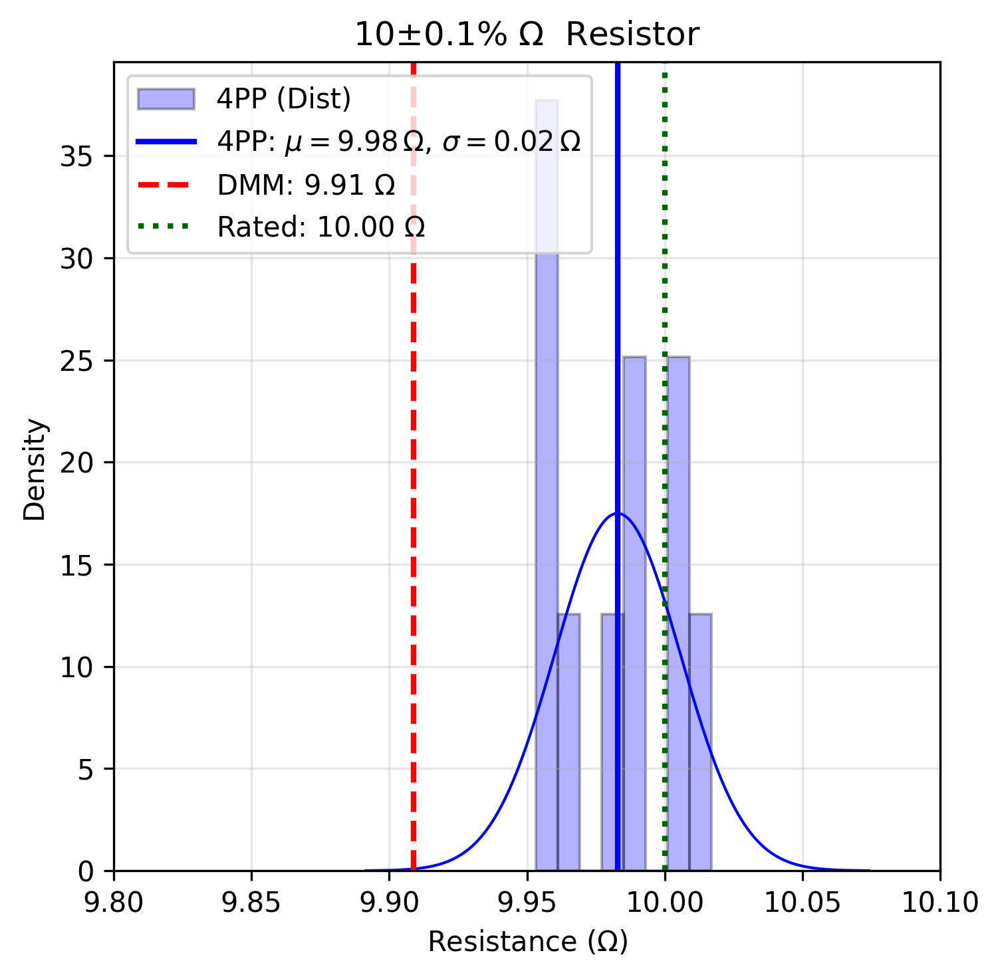

In [194]:
# 1. Statistics
mean_m = np.mean(r10_measured)
std_m = np.std(r10_measured, ddof=1)
mean_a = np.mean(r10_actual)
r_rated = 10

# 2. Plot
plt.figure(figsize=(5, 5), dpi=300)

# Measured: Histogram + Vertical Mean Line with mean & std dev in legend
plt.hist(r10_measured, bins=8, density=True, alpha=0.3, color="blue", edgecolor="black", label="4PP (Dist)")
plt.axvline(mean_m, color="blue", linestyle="-", linewidth=2, label=rf"4PP: $\mu={mean_m:.2f}\,\Omega$, $\sigma={std_m:.2f}\,\Omega$")

# Measured: Bellcurve
x = np.linspace(mean_m - 4 * std_m, mean_m + 4 * std_m, 200)
y = stats.norm.pdf(x, mean_m, std_m)
plt.plot(x, y,color="blue", linestyle="-", linewidth=1)

# Actual: Vertical Reference Line
plt.axvline(mean_a, color="red", linestyle="--", linewidth=2, label=rf"DMM: {mean_a:.2f} $\Omega$")

# Rated / Nominal Benchmark Line
plt.axvline(r_rated, color="darkgreen", linestyle=":", linewidth=2, label=rf"Rated: {r_rated:.2f} $\Omega$")

# 3. Canvas formatting
plt.title(r"10$\pm$0.1% $\Omega$  Resistor")
plt.xlabel(r"Resistance ($\Omega$)")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.xlim(9.8, 10.1)
plt.show()

In [195]:
# Statistical Result
print("--- STATISTICAL VALIDATION RESULTS ---")
print(f"Total Measurements (N): {len(r10_measured)}")
print(f"Mean Resistance:  {mean_m:.3e} Ω")
print(f"Standard Deviation (σ): {std_m:.3e} Ω")
print(f"Relative Standard Error:{((std_m / mean_m) * 100):.3e}%")

# Calculate and print 1-sigma, 2-sigma, and 3-sigma ranges

# 1-sigma range
one_sigma_lower = mean_m - std_m
one_sigma_upper = mean_m + std_m
points_in_one_sigma = r10_measured[(r10_measured >= one_sigma_lower) & (r10_measured <= one_sigma_upper)]
print(f"\n1-Sigma Range: [{one_sigma_lower:.3e} to {one_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 1-sigma: {len(points_in_one_sigma)} ({(len(points_in_one_sigma) / len(r10_measured)) * 100:.2f}%) ")

# 2-sigma range
two_sigma_lower = mean_m - (2 * std_m)
two_sigma_upper = mean_m + (2 * std_m)
points_in_two_sigma = r10_measured[(r10_measured >= two_sigma_lower) & (r10_measured <= two_sigma_upper)]
print(f"2-Sigma Range: [{two_sigma_lower:.3e} to {two_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 2-sigma: {len(points_in_two_sigma)} ({(len(points_in_two_sigma) / len(r10_measured)) * 100:.2f}%) ")

# 3-sigma range
three_sigma_lower = mean_m - (3 * std_m)
three_sigma_upper = mean_m + (3 * std_m)
points_in_three_sigma = r10_measured[(r10_measured >= three_sigma_lower) & (r10_measured <= three_sigma_upper)]
print(f"3-Sigma Range: [{three_sigma_lower:.3e} to {three_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 3-sigma: {len(points_in_three_sigma)} ({(len(points_in_three_sigma) / len(r10_measured)) * 100:.2f}%) ")

--- STATISTICAL VALIDATION RESULTS ---
Total Measurements (N): 10
Mean Resistance:  9.983e+00 Ω
Standard Deviation (σ): 2.280e-02 Ω
Relative Standard Error:2.284e-01%

1-Sigma Range: [9.960e+00 to 1.001e+01] Ω/sq
Number of points within 1-sigma: 6 (60.00%) 
2-Sigma Range: [9.937e+00 to 1.003e+01] Ω/sq
Number of points within 2-sigma: 10 (100.00%) 
3-Sigma Range: [9.914e+00 to 1.005e+01] Ω/sq
Number of points within 3-sigma: 10 (100.00%) 


####R=100

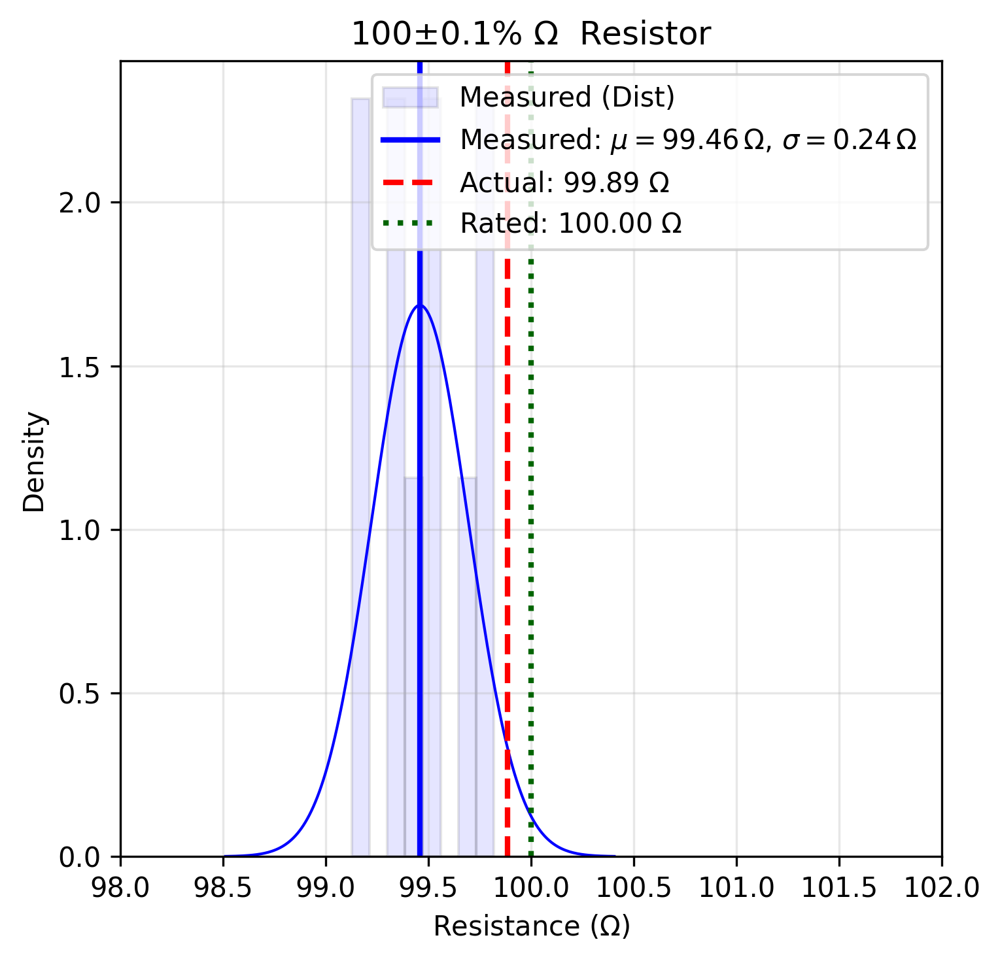

In [196]:
# 1. Statistics
mean_m = np.mean(r100_measured)
std_m = np.std(r100_measured, ddof=1)
mean_a = np.mean(r100_actual)
r_rated = 100

# 2. Plot
plt.figure(figsize=(5, 5), dpi=300)

# Measured: Histogram + Vertical Mean Line with mean & std dev in legend
plt.hist(r100_measured, bins=8, density=True, alpha=0.1, color="blue", edgecolor="black", label="Measured (Dist)")
plt.axvline(mean_m, color="blue", linestyle="-", linewidth=2, label=rf"Measured: $\mu={mean_m:.2f}\,\Omega$, $\sigma={std_m:.2f}\,\Omega$")

# Measured: Bellcurve
x = np.linspace(mean_m - 4 * std_m, mean_m + 4 * std_m, 200)
y = stats.norm.pdf(x, mean_m, std_m)
plt.plot(x, y,color="blue", linestyle="-", linewidth=1)

# Actual: Vertical Reference Line
plt.axvline(mean_a, color="red", linestyle="--", linewidth=2, label=rf"Actual: {mean_a:.2f} $\Omega$")

# Rated / Nominal Benchmark Line
plt.axvline(r_rated, color="darkgreen", linestyle=":", linewidth=2, label=rf"Rated: {r_rated:.2f} $\Omega$")

# 3. Canvas formatting
plt.title(r"100$\pm$0.1% $\Omega$  Resistor")
plt.xlabel(r"Resistance ($\Omega$)")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.xlim(98, 102)
plt.show()

In [197]:
# Statistical Result
print("--- STATISTICAL VALIDATION RESULTS ---")
print(f"Total Measurements (N): {len(r100_measured)}")
print(f"Mean Resistance:  {mean_m:.3e} Ω")
print(f"Standard Deviation (σ): {std_m:.3e} Ω")
print(f"Relative Standard Error:{((std_m / mean_m) * 100):.3e}%")

# 1-sigma range
one_sigma_lower = mean_m - std_m
one_sigma_upper = mean_m + std_m
points_in_one_sigma = r100_measured[(r100_measured >= one_sigma_lower) & (r100_measured <= one_sigma_upper)]
print(f"\n1-Sigma Range: [{one_sigma_lower:.3e} to {one_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 1-sigma: {len(points_in_one_sigma)} ({(len(points_in_one_sigma) / len(r100_measured)) * 100:.2f}%) ")

# 2-sigma range
two_sigma_lower = mean_m - (2 * std_m)
two_sigma_upper = mean_m + (2 * std_m)
points_in_two_sigma = r100_measured[(r100_measured >= two_sigma_lower) & (r100_measured <= two_sigma_upper)]
print(f"2-Sigma Range: [{two_sigma_lower:.3e} to {two_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 2-sigma: {len(points_in_two_sigma)} ({(len(points_in_two_sigma) / len(r100_measured)) * 100:.2f}%) ")

# 3-sigma range
three_sigma_lower = mean_m - (3 * std_m)
three_sigma_upper = mean_m + (3 * std_m)
points_in_three_sigma = r100_measured[(r100_measured >= three_sigma_lower) & (r100_measured <= three_sigma_upper)]
print(f"3-Sigma Range: [{three_sigma_lower:.3e} to {three_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 3-sigma: {len(points_in_three_sigma)} ({(len(points_in_three_sigma) / len(r100_measured)) * 100:.2f}%) ")

--- STATISTICAL VALIDATION RESULTS ---
Total Measurements (N): 10
Mean Resistance:  9.946e+01 Ω
Standard Deviation (σ): 2.367e-01 Ω
Relative Standard Error:2.380e-01%

1-Sigma Range: [9.922e+01 to 9.970e+01] Ω/sq
Number of points within 1-sigma: 6 (60.00%) 
2-Sigma Range: [9.899e+01 to 9.993e+01] Ω/sq
Number of points within 2-sigma: 10 (100.00%) 
3-Sigma Range: [9.875e+01 to 1.002e+02] Ω/sq
Number of points within 3-sigma: 10 (100.00%) 


####R=1k

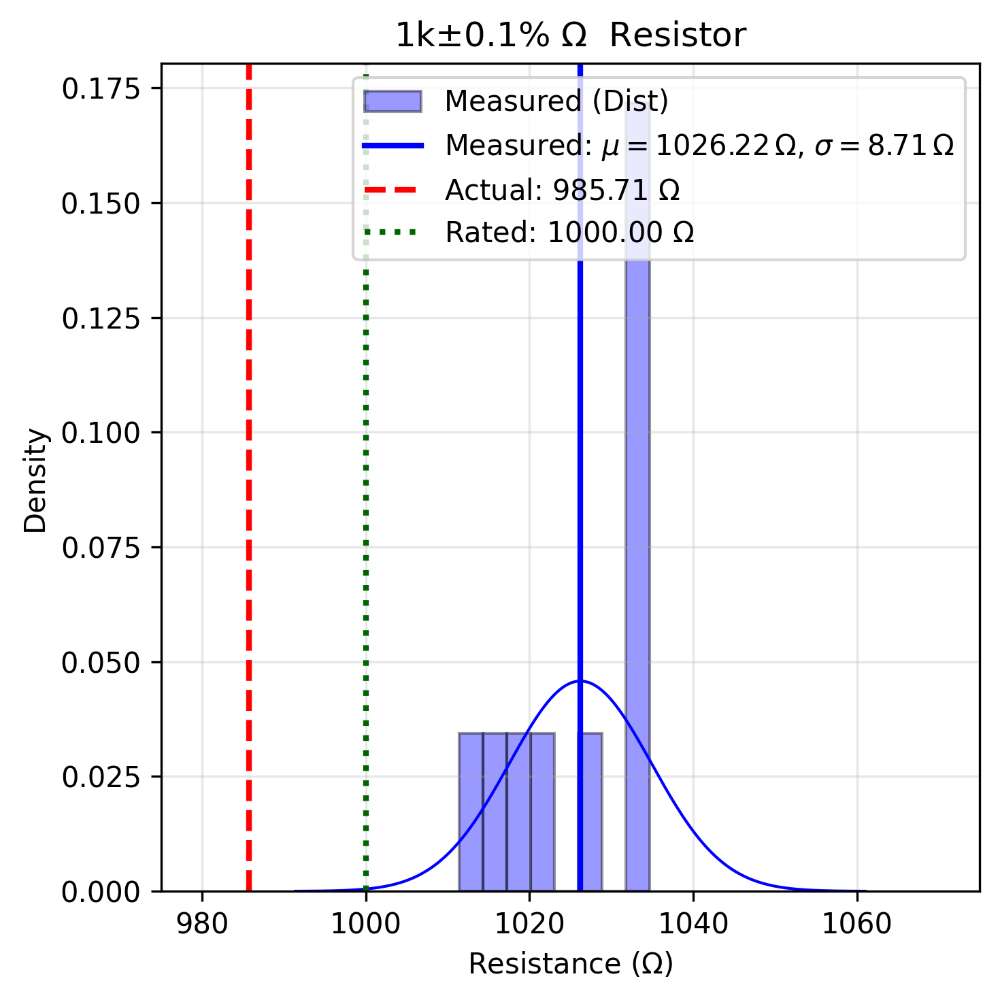

In [198]:
# 1. Statistics
mean_m = np.mean(r1k_measured)
std_m = np.std(r1k_measured, ddof=1)
mean_a = np.mean(r1k_actual)
r_rated = 1000

# 2. Plot
plt.figure(figsize=(5, 5), dpi=300)

# Measured: Histogram + Vertical Mean Line with mean & std dev in legend
plt.hist(r1k_measured, bins=8, density=True, alpha=0.4, color="blue", edgecolor="black", label="Measured (Dist)")
plt.axvline(mean_m, color="blue", linestyle="-", linewidth=2, label=rf"Measured: $\mu={mean_m:.2f}\,\Omega$, $\sigma={std_m:.2f}\,\Omega$")

# Measured: Bellcurve
x = np.linspace(mean_m - 4 * std_m, mean_m + 4 * std_m, 200)
y = stats.norm.pdf(x, mean_m, std_m)
plt.plot(x, y,color="blue", linestyle="-", linewidth=1)

# Actual: Vertical Reference Line
plt.axvline(mean_a, color="red", linestyle="--", linewidth=2, label=rf"Actual: {mean_a:.2f} $\Omega$")

# Rated / Nominal Benchmark Line
plt.axvline(r_rated, color="darkgreen", linestyle=":", linewidth=2, label=rf"Rated: {r_rated:.2f} $\Omega$")

# 3. Canvas formatting
plt.title(r"1k$\pm$0.1% $\Omega$  Resistor")
plt.xlabel(r"Resistance ($\Omega$)")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.xlim(975, 1075)
plt.show()

In [199]:
# Statistical Result
print("--- STATISTICAL VALIDATION RESULTS ---")
print(f"Total Measurements (N): {len(r1k_measured)}")
print(f"Mean Bulk Resistivity:  {mean_m:.3e} Ω/sq")
print(f"Standard Deviation (σ): {std_m:.3e} Ω/sq")
print(f"Relative Standard Error:{((std_m / mean_m) * 100):.3e}%")

# 1-sigma range
one_sigma_lower = mean_m - std_m
one_sigma_upper = mean_m + std_m
points_in_one_sigma = r1k_measured[(r1k_measured >= one_sigma_lower) & (r1k_measured <= one_sigma_upper)]
print(f"\n1-Sigma Range: [{one_sigma_lower:.3e} to {one_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 1-sigma: {len(points_in_one_sigma)} ({(len(points_in_one_sigma) / len(r1k_measured)) * 100:.2f}%) ")

# 2-sigma range
two_sigma_lower = mean_m - (2 * std_m)
two_sigma_upper = mean_m + (2 * std_m)
points_in_two_sigma = r1k_measured[(r1k_measured >= two_sigma_lower) & (r1k_measured <= two_sigma_upper)]
print(f"2-Sigma Range: [{two_sigma_lower:.3e} to {two_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 2-sigma: {len(points_in_two_sigma)} ({(len(points_in_two_sigma) / len(r1k_measured)) * 100:.2f}%) ")

# 3-sigma range
three_sigma_lower = mean_m - (3 * std_m)
three_sigma_upper = mean_m + (3 * std_m)
points_in_three_sigma = r1k_measured[(r1k_measured >= three_sigma_lower) & (r1k_measured <= three_sigma_upper)]
print(f"3-Sigma Range: [{three_sigma_lower:.3e} to {three_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 3-sigma: {len(points_in_three_sigma)} ({(len(points_in_three_sigma) / len(r1k_measured)) * 100:.2f}%) ")

--- STATISTICAL VALIDATION RESULTS ---
Total Measurements (N): 10
Mean Bulk Resistivity:  1.026e+03 Ω/sq
Standard Deviation (σ): 8.710e+00 Ω/sq
Relative Standard Error:8.488e-01%

1-Sigma Range: [1.018e+03 to 1.035e+03] Ω/sq
Number of points within 1-sigma: 8 (80.00%) 
2-Sigma Range: [1.009e+03 to 1.044e+03] Ω/sq
Number of points within 2-sigma: 10 (100.00%) 
3-Sigma Range: [1.000e+03 to 1.052e+03] Ω/sq
Number of points within 3-sigma: 10 (100.00%) 


####R=10k

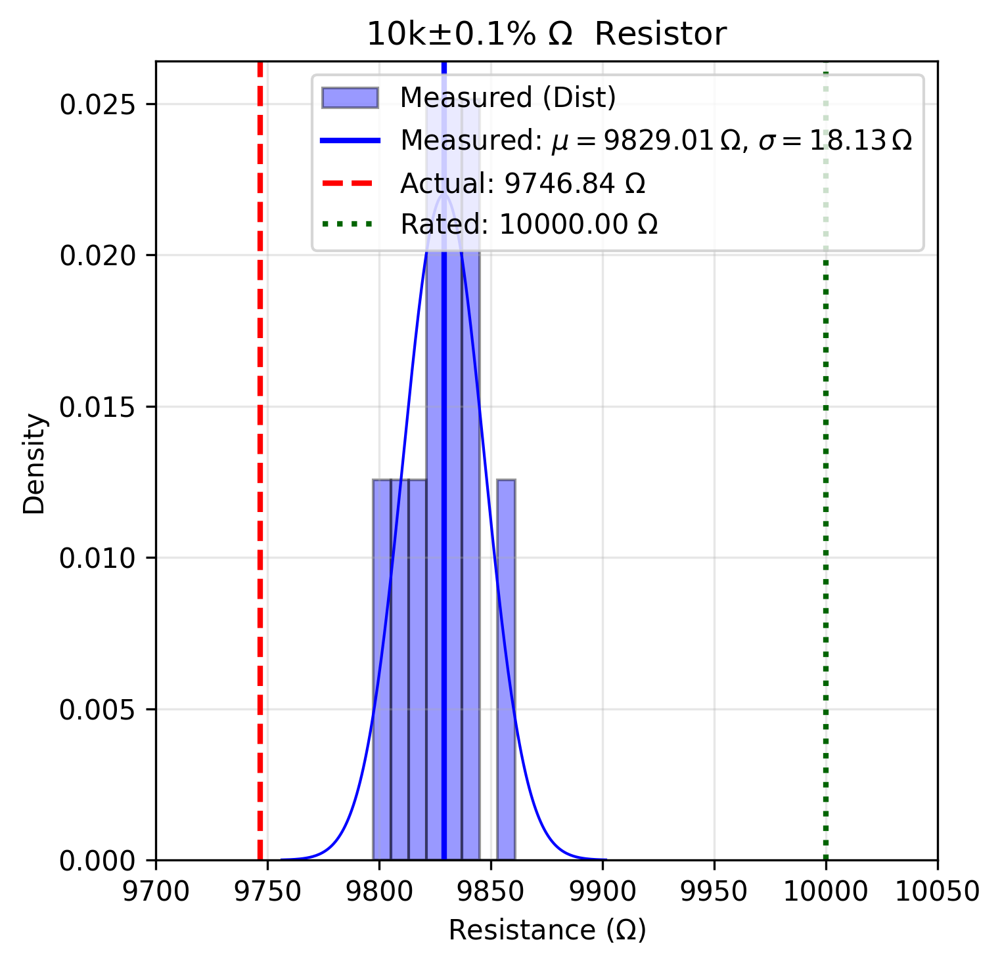

In [200]:
# 1. Statistics
mean_m = np.mean(r10k_measured)
std_m = np.std(r10k_measured, ddof=1)
mean_a = np.mean(r10k_actual)
r_rated = 10000
# Calculate Coefficient of Variation (CV)
cv_m = std_m / mean_m * 100

# 2. Plot
plt.figure(figsize=(5, 5), dpi=300)

# Measured: Histogram + Vertical Mean Line with mean & std dev in legend
plt.hist(r10k_measured, bins=8, density=True, alpha=0.4, color="blue", edgecolor="black", label="Measured (Dist)")
plt.axvline(mean_m, color="blue", linestyle="-", linewidth=2, label=rf"Measured: $\mu={mean_m:.2f}\,\Omega$, $\sigma={std_m:.2f}\,\Omega$")

# Measured: Bellcurve
x = np.linspace(mean_m - 4 * std_m, mean_m + 4 * std_m, 200)
y = stats.norm.pdf(x, mean_m, std_m)
plt.plot(x, y,color="blue", linestyle="-", linewidth=1)

# Actual: Vertical Reference Line
plt.axvline(mean_a, color="red", linestyle="--", linewidth=2, label=rf"Actual: {mean_a:.2f} $\Omega$")

# Rated / Nominal Benchmark Line
plt.axvline(r_rated, color="darkgreen", linestyle=":", linewidth=2, label=rf"Rated: {r_rated:.2f} $\Omega$")

# 3. Canvas formatting
plt.title(r"10k$\pm$0.1% $\Omega$  Resistor")
plt.xlabel(r"Resistance ($\Omega$)")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.xlim(9700, 10050)
plt.show()

In [201]:
# Statistical Result
print("--- STATISTICAL VALIDATION RESULTS ---")
print(f"Total Measurements (N): {len(r10k_measured)}")
print(f"Mean Bulk Resistivity:  {mean_m:.3e} Ω/sq")
print(f"Standard Deviation (σ): {std_m:.3e} Ω/sq")
print(f"Relative Standard Error:{((std_m / mean_m) * 100):.3e}%")

# 1-sigma range
one_sigma_lower = mean_m - std_m
one_sigma_upper = mean_m + std_m
points_in_one_sigma = r10k_measured[(r10k_measured >= one_sigma_lower) & (r10k_measured <= one_sigma_upper)]
print(f"\n1-Sigma Range: [{one_sigma_lower:.3e} to {one_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 1-sigma: {len(points_in_one_sigma)} ({(len(points_in_one_sigma) / len(r10k_measured)) * 100:.2f}%) ")

# 2-sigma range
two_sigma_lower = mean_m - (2 * std_m)
two_sigma_upper = mean_m + (2 * std_m)
points_in_two_sigma = r10k_measured[(r10k_measured >= two_sigma_lower) & (r10k_measured <= two_sigma_upper)]
print(f"2-Sigma Range: [{two_sigma_lower:.3e} to {two_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 2-sigma: {len(points_in_two_sigma)} ({(len(points_in_two_sigma) / len(r10k_measured)) * 100:.2f}%) ")

# 3-sigma range
three_sigma_lower = mean_m - (3 * std_m)
three_sigma_upper = mean_m + (3 * std_m)
points_in_three_sigma = r10k_measured[(r10k_measured >= three_sigma_lower) & (r10k_measured <= three_sigma_upper)]
print(f"3-Sigma Range: [{three_sigma_lower:.3e} to {three_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 3-sigma: {len(points_in_three_sigma)} ({(len(points_in_three_sigma) / len(r10k_measured)) * 100:.2f}%) ")

--- STATISTICAL VALIDATION RESULTS ---
Total Measurements (N): 10
Mean Bulk Resistivity:  9.829e+03 Ω/sq
Standard Deviation (σ): 1.813e+01 Ω/sq
Relative Standard Error:1.845e-01%

1-Sigma Range: [9.811e+03 to 9.847e+03] Ω/sq
Number of points within 1-sigma: 7 (70.00%) 
2-Sigma Range: [9.793e+03 to 9.865e+03] Ω/sq
Number of points within 2-sigma: 10 (100.00%) 
3-Sigma Range: [9.775e+03 to 9.883e+03] Ω/sq
Number of points within 3-sigma: 10 (100.00%) 


### Aluminium

In [202]:
#aluminium
#Load the CSV files into pandas DataFrames
df_4pp = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/4pp_al_20260814.csv')
df_tlm = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/tlm_al_20260726.csv')
# print(df_4pp.head())
# print(df_tlm.head())

In [203]:
#raw resistance data
al_resist_4pp = df_4pp['Delta_mV']/ 100.0  #resistance of aluminium with 4pp
al_resist_keithley = df_tlm['Keithley Net']  #resistance of aluminium with Keithly 193 DMM
al_resist_318 = df_tlm['Rapid 318 Net']  #resistance of aluminium with the Rapid 318 DMM

In [204]:
#sheet resistance 4pp
al_sh_resist_4pp = al_resist_4pp * math.pi/math.log(2)
# print(f"Sheet Resistance: {al_sh_resist_4pp}")

TLM METHOD

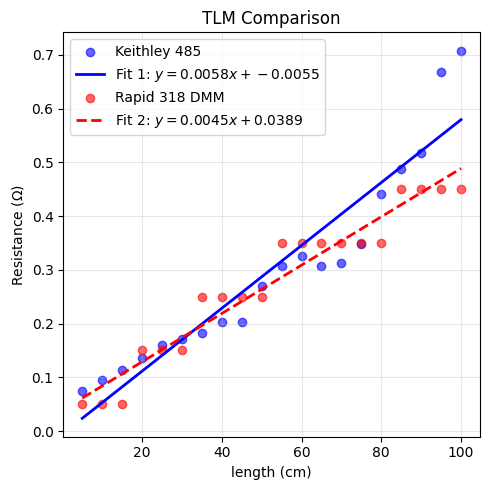

In [205]:
#getting the sheet resistance from TLM
x = df_tlm['Distance (d)']
y1 = al_resist_keithley
y2 = al_resist_318

# Fit a line (degree 1)
m1, c1 = np.polyfit(x, y1, 1)
m2, c2 = np.polyfit(x, y2, 1)

# Plot
plt.figure(figsize=(5, 5))

# keithley data
plt.scatter(x, y1, color="blue", alpha=0.6, label="Keithley 485")
plt.plot(x,m1 * x+ c1,"b-",linewidth=2,label=rf"Fit 1: $y = {m1:.4f}x + {c1:.4f}$",)

# rapid dmm data
plt.scatter(x, y2, color="red", alpha=0.6, label="Rapid 318 DMM")
plt.plot(x, m2 * x + c2,  "r--",linewidth=2, label=rf"Fit 2: $y = {m2:.4f}x + {c2:.4f}$",)

plt.xlabel("length (cm)")
plt.ylabel(rf"Resistance $(\Omega$)")
plt.title("TLM Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [206]:
# multiply m by 0.5cm (5mm width of the TLM)
al_sh_resist_keithley = m1*0.5
al_sh_resist_318 = m2*0.5
print(f"Sheet Resistance Keithley: {al_sh_resist_keithley:.2e}")
print(f"Sheet Resistance Rapid 318: {al_sh_resist_318:.2e}")

# assumed the thickness of foil is 12 microns (12*10^-6)m for Ohm m (12*10^-4)cm for Ohm cm
al_thickness = 12*pow(10,-4)

# multiply Rs by t
al_bulk_resist_keithley = al_sh_resist_keithley*al_thickness
al_bulk_resist_318 = al_sh_resist_318*al_thickness
al_bulk_resist_ref = 2.655*pow(10,-6) # aluminium 99% (ref:	CSNDT)
al_bulk_resist_4pp = al_sh_resist_4pp*al_thickness

print(f"Bulk Resistivity Keithley: {al_bulk_resist_keithley:.2e}")
print(f"Bulk Resistivity Rapid 318: {al_bulk_resist_318:.2e}")
print(f"Bulk Resistivity Al 99.99% (CSNDT): {al_bulk_resist_ref:.2e}")

Sheet Resistance Keithley: 2.92e-03
Sheet Resistance Rapid 318: 2.25e-03
Bulk Resistivity Keithley: 3.51e-06
Bulk Resistivity Rapid 318: 2.70e-06
Bulk Resistivity Al 99.99% (CSNDT): 2.65e-06


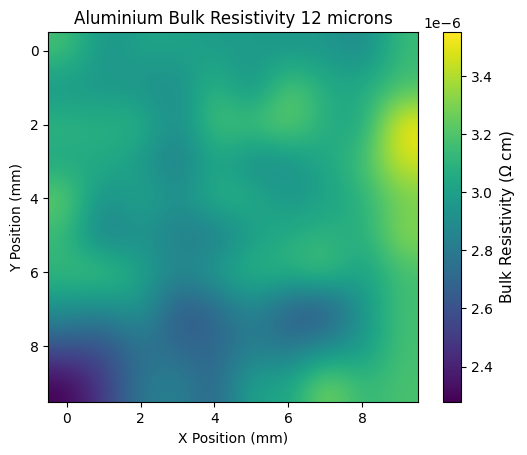

In [207]:
# Add al_sh_resist_4pp to df_4pp for easier pivoting
df_4pp['al_bulk_resist_4pp'] = al_bulk_resist_4pp

# Pivot the DataFrame to get the sheet resistance in a grid format
heatmap_data = df_4pp.pivot(index='Row', columns='Col', values='al_bulk_resist_4pp')
heatmap_flipped = heatmap_data.iloc[::-1].reset_index(drop=True)

# Define physical bounding box for coordinates
x_min, x_max = heatmap_flipped.columns.min(), heatmap_flipped.columns.max()
y_min, y_max = heatmap_flipped.index.min(), heatmap_flipped.index.max()

# Create the heatmap
im = plt.imshow(heatmap_flipped, cmap='viridis', interpolation='bicubic')
cbar = plt.colorbar(im)
cbar.set_label(rf'Bulk Resistivity ($\Omega$ cm)', fontsize=11)
plt.title("Aluminium Bulk Resistivity 12 microns")
plt.xlabel('X Position (mm)')
plt.ylabel('Y Position (mm)')
plt.grid(False)
plt.show()

In [208]:
# Bulk Resistivity
# Calculate the core statistics
n = len(al_bulk_resist_4pp)
mean_al = np.mean(al_bulk_resist_4pp)
std_dev_al = np.std(al_bulk_resist_4pp, ddof=1)  # Sample standard deviation

# Calculate 95% Confidence Interval
confidence_level = 0.95
sem = stats.sem(al_bulk_resist_4pp)
margin_of_error = sem * stats.t.ppf((1 + confidence_level) / 2., n-1)
ci_lower = mean_al - margin_of_error
ci_upper = mean_al + margin_of_error

In [209]:
# Statistical Result
print("--- STATISTICAL VALIDATION RESULTS ---")
print(f"Total Measurements (N): {n}")
print(f"Mean Bulk Resistivity:  {mean_al:.3e} Ω/sq")
print(f"Standard Deviation (σ): {std_dev_al:.3e} Ω/sq")
print(f"95% Confidence Range:   [{ci_lower:.3e} to {ci_upper:.3e}] Ω/sq")
print(f"Relative Standard Error:{((std_dev_al / mean_al) * 100):.3e}%")

# 1-sigma range
one_sigma_lower = mean_al - std_dev_al
one_sigma_upper = mean_al + std_dev_al
points_in_one_sigma = al_bulk_resist_4pp[(al_bulk_resist_4pp >= one_sigma_lower) & (al_bulk_resist_4pp <= one_sigma_upper)]
print(f"\n1-Sigma Range: [{one_sigma_lower:.3e} to {one_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 1-sigma: {len(points_in_one_sigma)} ({(len(points_in_one_sigma) / len(al_bulk_resist_4pp)) * 100:.2f}%) ")

# 2-sigma range
two_sigma_lower = mean_al - (2 * std_dev_al)
two_sigma_upper = mean_al + (2 * std_dev_al)
points_in_two_sigma = al_bulk_resist_4pp[(al_bulk_resist_4pp >= two_sigma_lower) & (al_bulk_resist_4pp <= two_sigma_upper)]
print(f"2-Sigma Range: [{two_sigma_lower:.3e} to {two_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 2-sigma: {len(points_in_two_sigma)} ({(len(points_in_two_sigma) / len(al_bulk_resist_4pp)) * 100:.2f}%) ")

# 3-sigma range
three_sigma_lower = mean_al - (3 * std_dev_al)
three_sigma_upper = mean_al + (3 * std_dev_al)
points_in_three_sigma = al_bulk_resist_4pp[(al_bulk_resist_4pp >= three_sigma_lower) & (al_bulk_resist_4pp <= three_sigma_upper)]
print(f"3-Sigma Range: [{three_sigma_lower:.3e} to {three_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 3-sigma: {len(points_in_three_sigma)} ({(len(points_in_three_sigma) / len(al_bulk_resist_4pp)) * 100:.2f}%) ")

--- STATISTICAL VALIDATION RESULTS ---
Total Measurements (N): 100
Mean Bulk Resistivity:  2.985e-06 Ω/sq
Standard Deviation (σ): 2.030e-07 Ω/sq
95% Confidence Range:   [2.945e-06 to 3.025e-06] Ω/sq
Relative Standard Error:6.802e+00%

1-Sigma Range: [2.782e-06 to 3.188e-06] Ω/sq
Number of points within 1-sigma: 76 (76.00%) 
2-Sigma Range: [2.579e-06 to 3.391e-06] Ω/sq
Number of points within 2-sigma: 96 (96.00%) 
3-Sigma Range: [2.376e-06 to 3.594e-06] Ω/sq
Number of points within 3-sigma: 99 (99.00%) 


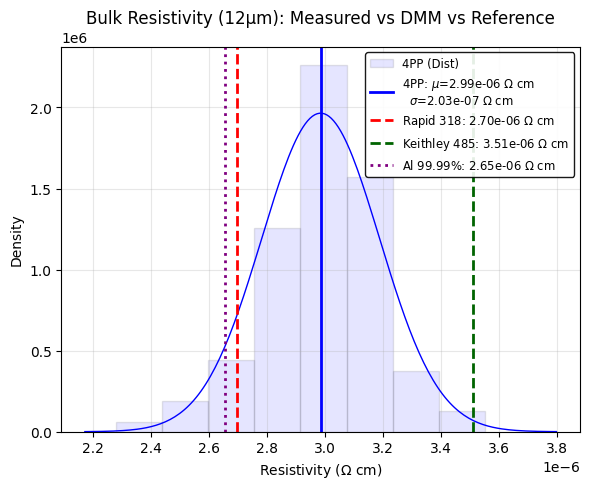

In [210]:
# Plot
plt.figure(figsize=(6, 5))

# Measured: Histogram + Vertical Mean Line with mean & std dev in legend
plt.hist(al_bulk_resist_4pp, bins=8, density=True, alpha=0.1, color="blue", edgecolor="black", label="4PP (Dist)")
plt.axvline(mean_al, color="blue", linestyle="-", linewidth=2, label=rf"4PP: $\mu$={mean_al:.2e} $\Omega$ cm" + "\n" + rf"  $\sigma$={std_dev_al:.2e} $\Omega$ cm")

# Measured: Bellcurve
x = np.linspace(mean_al - 4 * std_dev_al, mean_al + 4 * std_dev_al, 200)
y = stats.norm.pdf(x, mean_al, std_dev_al)
plt.plot(x, y,color="blue", linestyle="-", linewidth=1)

# Actual: Vertical Reference Line
plt.axvline(al_bulk_resist_318, color="red", linestyle="--", linewidth=2, label=rf"Rapid 318: {al_bulk_resist_318:.2e} $\Omega$ cm")

# Rated / Nominal Benchmark Line
plt.axvline(al_bulk_resist_keithley, color="darkgreen", linestyle="--", linewidth=2, label=rf"Keithley 485: {al_bulk_resist_keithley:.2e} $\Omega$ cm")

# Rated / Nominal Benchmark Line
plt.axvline(al_bulk_resist_ref, color="purple", linestyle=":", linewidth=2, label=rf"Al 99.99%: {al_bulk_resist_ref:.2e} $\Omega$ cm")

# 3. Canvas formatting
plt.title("Bulk Resistivity (12µm): Measured vs DMM vs Reference")
plt.xlabel(rf"Resistivity ($\Omega$ cm)")
plt.ylabel("Density")
plt.legend(loc='best',frameon=True,fontsize='small', facecolor='white',edgecolor='black',framealpha=0.9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

###Graphite

In [211]:
#Graphite
df_4pp_graphite1 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/4pp_graphite_1side_20260813.csv')
df_4pp_graphite2 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/4pp_graphite_2side_20260813.csv')
df_4pp_mrsmiley = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/4pp_graphite_mrsmiley_20260813.csv')

In [212]:
#the range was 2mA max, therefore the a3 corresponds to 0.177mA at node 1..
df_4pp_graphite1['R_Ohms'] = (df_4pp_graphite1['Delta_mV'] / -df_4pp_graphite1['A3_mV'])*1e2
df_4pp_graphite1['Rs_Ohm_sq'] = df_4pp_graphite1['R_Ohms'] * math.pi/math.log(2)

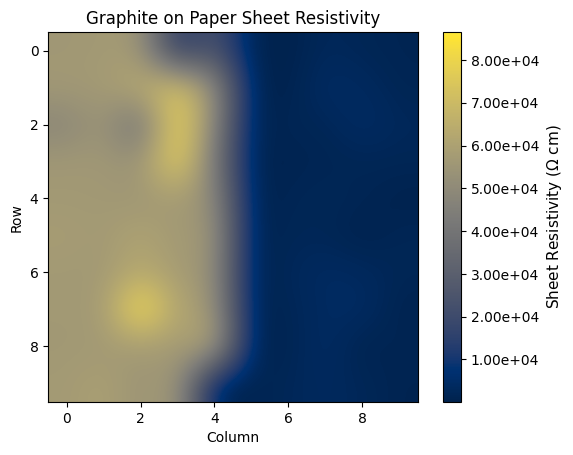

In [213]:
# Pivot the DataFrame to get the sheet resistance in a grid format
heatmap_data = df_4pp_graphite2.pivot(index='Row', columns='Col', values='Rs_Ohm_sq')
heatmap_flipped = heatmap_data.iloc[::-1].reset_index(drop=True)

# Create the heatmap
im = plt.imshow(heatmap_flipped, cmap='cividis', interpolation='bicubic')
cbar = plt.colorbar(im, format='%.2e')
cbar.set_label(rf'Sheet Resistivity ($\Omega$ cm)', fontsize=11)
plt.title("Graphite on Paper Sheet Resistivity")
plt.xlabel('Column')
plt.ylabel('Row')
plt.grid(False)
plt.show()

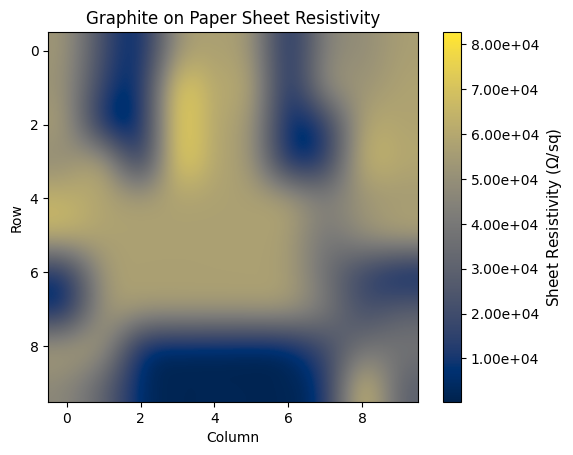

In [214]:
# Pivot the DataFrame to get the sheet resistance in a grid format
heatmap_data = df_4pp_mrsmiley.pivot(index='Row', columns='Col', values='Rs_Ohm_sq')
heatmap_flipped = heatmap_data.iloc[::-1].reset_index(drop=True)

# Create the heatmap
im = plt.imshow(heatmap_flipped, cmap='cividis', interpolation='bicubic')
cbar = plt.colorbar(im, format='%.2e')
cbar.set_label(rf'Sheet Resistivity ($\Omega$/sq)', fontsize=11)
plt.title("Graphite on Paper Sheet Resistivity")
plt.xlabel('Column')
plt.ylabel('Row')
plt.grid(False)
plt.show()

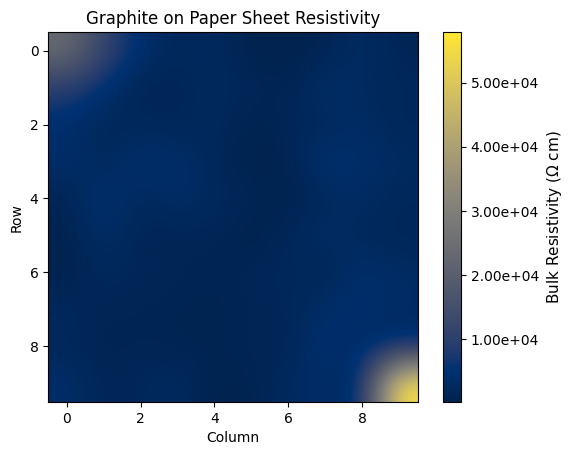

In [215]:
# Pivot the DataFrame to get the sheet resistance in a grid format
heatmap_data = df_4pp_graphite1.pivot(index='Row', columns='Col', values='Rs_Ohm_sq')
heatmap_flipped = heatmap_data.iloc[::-1].reset_index(drop=True)

# Create the heatmap
im = plt.imshow(heatmap_flipped, cmap='cividis', interpolation='bicubic')
cbar = plt.colorbar(im, format='%.2e')
cbar.set_label(rf'Bulk Resistivity ($\Omega$ cm)', fontsize=11)
plt.title("Graphite on Paper Sheet Resistivity")
plt.xlabel('Column')
plt.ylabel('Row')
plt.grid(False)
plt.show()

In [216]:
#bulkresist of graphite?
#assuming a 6b pencil on paper is about 6 microns,
thickness = 6*pow(10,-4)
df_4pp_graphite1['Ohm cm'] = df_4pp_graphite1['Rs_Ohm_sq'] * thickness

# Bulk Resistivity
graphite_bulk_resist_4pp = df_4pp_graphite1['Ohm cm']

#eliminate outlier >10 ohm
graphite_bulk_resist_4pp = graphite_bulk_resist_4pp[graphite_bulk_resist_4pp < 5]

# Calculate the core statistics
n = len(graphite_bulk_resist_4pp)
mean_gr = np.mean(graphite_bulk_resist_4pp)
std_dev_gr = np.std(graphite_bulk_resist_4pp, ddof=1)  # Sample standard deviation

# Calculate 95% Confidence Interval
confidence_level = 0.95
sem = stats.sem(graphite_bulk_resist_4pp)
margin_of_error = sem * stats.t.ppf((1 + confidence_level) / 2., n-1)
ci_lower = mean_gr - margin_of_error
ci_upper = mean_gr + margin_of_error

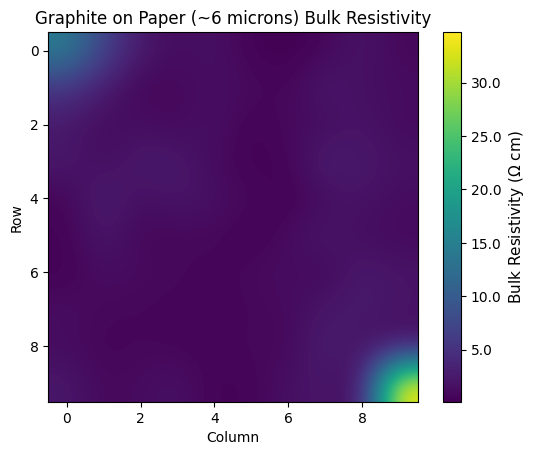

In [217]:
# Pivot the DataFrame to get the sheet resistance in a grid format
heatmap_data = df_4pp_graphite1.pivot(index='Row', columns='Col', values='Ohm cm')
heatmap_flipped = heatmap_data.iloc[::-1].reset_index(drop=True)

# Create the heatmap
im = plt.imshow(heatmap_flipped, cmap='viridis', interpolation='bicubic')
cbar = plt.colorbar(im, format='%.1f')
cbar.set_label(rf'Bulk Resistivity ($\Omega$ cm)', fontsize=11)
plt.title("Graphite on Paper (~6 microns) Bulk Resistivity")
plt.xlabel('Column')
plt.ylabel('Row')
plt.grid(False)
plt.show()

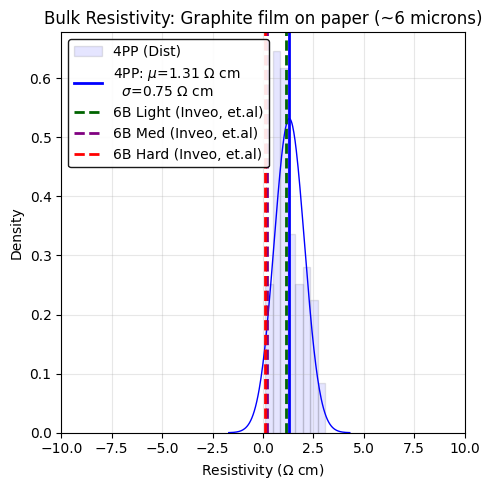

In [218]:
ref_6blight = 1.157
ref_6bmed = 0.224
ref_6bhard = 0.106

# Plot
plt.figure(figsize=(5, 5))

# Measured: Histogram + Vertical Mean Line with mean & std dev in legend
plt.hist(graphite_bulk_resist_4pp, bins=8, density=True, alpha=0.1, color="blue", edgecolor="black", label="4PP (Dist)")
plt.axvline(mean_gr, color="blue", linestyle="-", linewidth=2, label=rf"4PP: $\mu$={mean_gr:.2f} $\Omega$ cm" + "\n" + rf"  $\sigma$={std_dev_gr:.2f} $\Omega$ cm")

# Measured: Bellcurve
x = np.linspace(mean_gr - 4 * std_dev_gr, mean_gr + 4 * std_dev_gr, 200)
y = stats.norm.pdf(x, mean_gr, std_dev_gr)
plt.plot(x, y,color="blue", linestyle="-", linewidth=1)

# Ref1
plt.axvline(ref_6blight, color="darkgreen", linestyle="--", linewidth=2, label=rf"6B Light (Inveo, et.al)")

# Ref2
plt.axvline(ref_6bmed, color="purple", linestyle="--", linewidth=2, label=rf"6B Med (Inveo, et.al)")

# Ref2
plt.axvline(ref_6bhard, color="red", linestyle="--", linewidth=2, label=rf"6B Hard (Inveo, et.al)")

# Canvas formatting
plt.title("Bulk Resistivity: Graphite film on paper (~6 microns)")
plt.xlabel(rf"Resistivity ($\Omega$ cm)")
plt.ylabel("Density")
plt.legend(loc='best',frameon=True,facecolor='white',edgecolor='black',framealpha=0.9)
plt.grid(True, alpha=0.3)
plt.xlim(-10, 10)
plt.tight_layout()
plt.show()

In [219]:
# Statistical Result
print("--- STATISTICAL VALIDATION RESULTS ---")
print(f"Total Measurements (N): {n}")
print(f"Mean Bulk Resistivity:  {mean_gr:.3e} Ω/sq")
print(f"Standard Deviation (σ): {std_dev_gr:.3e} Ω/sq")
print(f"95% Confidence Range:   [{ci_lower:.3e} to {ci_upper:.3e}] Ω/sq")
print(f"Relative Standard Error:{((std_dev_gr / mean_gr) * 100):.3e}%")

# 1-sigma range
one_sigma_lower = mean_gr - std_dev_gr
one_sigma_upper = mean_gr + std_dev_gr
points_in_one_sigma = graphite_bulk_resist_4pp[(graphite_bulk_resist_4pp >= one_sigma_lower) & (graphite_bulk_resist_4pp <= one_sigma_upper)]
print(f"\n1-Sigma Range: [{one_sigma_lower:.3e} to {one_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 1-sigma: {len(points_in_one_sigma)} ({(len(points_in_one_sigma) / len(graphite_bulk_resist_4pp)) * 100:.2f}%) ")

# 2-sigma range
two_sigma_lower = mean_gr - (2 * std_dev_gr)
two_sigma_upper = mean_gr + (2 * std_dev_gr)
points_in_two_sigma = graphite_bulk_resist_4pp[(graphite_bulk_resist_4pp >= two_sigma_lower) & (graphite_bulk_resist_4pp <= two_sigma_upper)]
print(f"2-Sigma Range: [{two_sigma_lower:.3e} to {two_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 2-sigma: {len(points_in_two_sigma)} ({(len(points_in_two_sigma) / len(graphite_bulk_resist_4pp)) * 100:.2f}%) ")

# 3-sigma range
three_sigma_lower = mean_gr - (3 * std_dev_gr)
three_sigma_upper = mean_gr + (3 * std_dev_gr)
points_in_three_sigma = graphite_bulk_resist_4pp[(graphite_bulk_resist_4pp >= three_sigma_lower) & (graphite_bulk_resist_4pp <= three_sigma_upper)]
print(f"3-Sigma Range: [{three_sigma_lower:.3e} to {three_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 3-sigma: {len(points_in_three_sigma)} ({(len(points_in_three_sigma) / len(graphite_bulk_resist_4pp)) * 100:.2f}%) ")

--- STATISTICAL VALIDATION RESULTS ---
Total Measurements (N): 96
Mean Bulk Resistivity:  1.305e+00 Ω/sq
Standard Deviation (σ): 7.503e-01 Ω/sq
95% Confidence Range:   [1.153e+00 to 1.458e+00] Ω/sq
Relative Standard Error:5.747e+01%

1-Sigma Range: [5.552e-01 to 2.056e+00] Ω/sq
Number of points within 1-sigma: 62 (64.58%) 
2-Sigma Range: [-1.952e-01 to 2.806e+00] Ω/sq
Number of points within 2-sigma: 93 (96.88%) 
3-Sigma Range: [-9.455e-01 to 3.556e+00] Ω/sq
Number of points within 3-sigma: 96 (100.00%) 


###GST Repeatability test amorphous

In [220]:
#gst repeatability 3 times measure
df_gst_test1 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_combined_coords_merged.csv')
df_gst_test2 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_combined_coords_merged2.csv')
# df_gst_test3 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_combined_coords_merged3.csv')
df_gst_test3 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/4pp_gst_amorphous_calibrated2_20260826.csv')

dataframes = [
    (df_gst_test1, 'Run 1 (df_gst_test1)'),
    (df_gst_test2, 'Run 2 (df_gst_test2)'),
    (df_gst_test3, 'Run 3 (df_gst_test3)')]

#fill in missing values (where delta_mV is 2047)
for i, (df, title) in enumerate(dataframes):
  fill_ohm = df['Delta_mV'] / (df['A2_mV'] / 1000000)
  df['R_Ohms'] = df['R_Ohms'].fillna(fill_ohm)
  df['Rs_Ohm_sq'] = df['Rs_Ohm_sq'].fillna(df['R_Ohms'] * math.pi/math.log(2))

In [221]:
df_gst_test1.head(10)

,Node_ID,Row,Col,X_mm,Y_mm,Delta_mV,A2_mV,R_Ohms,Rs_Ohm_sq,Rs_MOhm_sq
0,1,1,1,-162,-110,1000.0938,858.0112,1.165595e+06,5.282898e+06,NaN
1,2,1,2,-156,-110,1140.8113,2028.5725,5.623715e+05,2.548870e+06,NaN
2,3,1,3,-150,-110,1117.6425,1555.4750,7.185217e+05,3.256599e+06,NaN
3,4,1,4,-144,-110,1085.0062,1504.0400,7.213945e+05,3.269620e+06,NaN
4,5,1,5,-138,-110,1039.9825,1698.9537,6.121312e+05,2.774399e+06,NaN
5,6,2,1,-174,-104,409.4887,1375.3538,2.977334e+05,1.349435e+06,NaN
6,7,2,2,-168,-104,512.2075,239.8087,2.135900e+06,9.680670e+06,NaN
7,8,2,3,-162,-104,797.5500,533.8362,1.493998e+06,6.771335e+06,NaN
8,9,2,4,-156,-104,1061.4237,979.6700,1.083450e+06,4.910587e+06,NaN
9,10,2,5,-150,-104,984.1113,847.3287,1.161428e+06,5.264010e+06,NaN


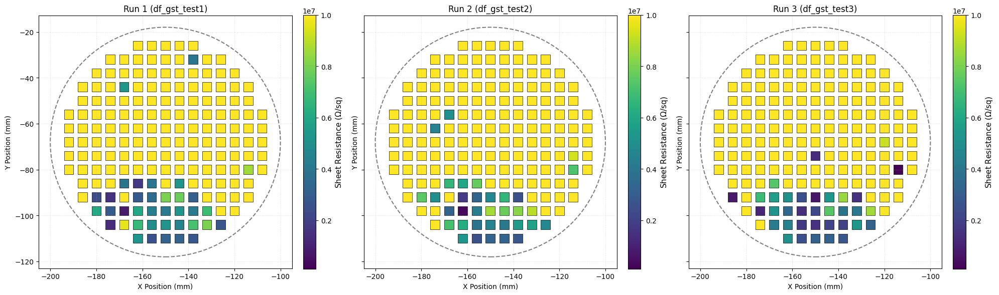

In [222]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10), sharex=True, sharey=True)
axes = axes.flatten() # Flatten the 2x3 array of axes for easier iteration

wafer_radius = 50  # mm

for i, (df, title) in enumerate(dataframes):
    ax = axes[i]

    fill_ohm = abs(df['Delta_mV'] / (df['A2_mV'] / 1000000))
    df['R_Ohms'] = df['R_Ohms'].fillna(fill_ohm)
    df['Rs_Ohm_sq'] = df['Rs_Ohm_sq'].fillna(df['R_Ohms'] * math.pi/math.log(2))
    df['Rs_MOhm_sq'] = df['Rs_Ohm_sq']/1e6
    # Drop rows with NaN in 'Rs_Ohm_sq' and filter out negative Rs_Ohm_sq values
    df_cleaned = df.dropna(subset=['Rs_Ohm_sq'])
    df_cleaned = df_cleaned[df_cleaned['Rs_Ohm_sq'] >= 0]

    sc = ax.scatter(
        df_cleaned['X_mm'],
        df_cleaned['Y_mm'],
        c=df_cleaned['Rs_Ohm_sq'],
        cmap='viridis',
        marker='s',  # Square markers
        s=180,  # Marker size (points^2)
        edgecolors='black',  # Border around each cell
        linewidth=0.5,
        vmin=1e5, # Set minimum for color scale to better visualize values around 1e6
        vmax=1e7  # Set maximum for color scale, values above this will use the max color
    )

    # Add wafer circular outline with new center
    wafer_outline = plt.Circle(
        (-150, -68), wafer_radius, color='gray', fill=False, linestyle='--', linewidth=1.5
    )
    ax.add_patch(wafer_outline)

    # Enforce strictly square aspect ratio and set bounds
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(-wafer_radius - 5 - 150, wafer_radius + 5 - 150) # Adjust x-limits for new center
    ax.set_ylim(-wafer_radius - 5 - 68, wafer_radius + 5 - 68)   # Adjust y-limits for new center

    # Labels and colorbar
    cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(r'Sheet Resistance ($\Omega$/sq)', fontsize=11)

    ax.set_title(title, fontsize=12)
    ax.set_xlabel('X Position (mm)', fontsize=10)
    ax.set_ylabel('Y Position (mm)', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.4)

# Turn off any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

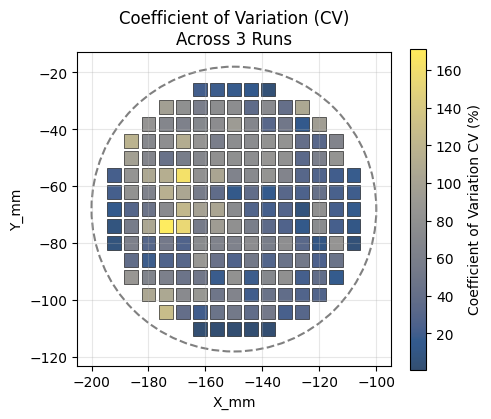

In [223]:
df1_prep = df_gst_test1[['X_mm', 'Y_mm', 'Rs_Ohm_sq']].dropna(subset=['Rs_Ohm_sq']).rename(columns={'Rs_Ohm_sq': 'Rs_Ohm_sq_run1'})
df2_prep = df_gst_test2[['X_mm', 'Y_mm', 'Rs_Ohm_sq']].dropna(subset=['Rs_Ohm_sq']).rename(columns={'Rs_Ohm_sq': 'Rs_Ohm_sq_run2'})
df3_prep = df_gst_test3[['X_mm', 'Y_mm', 'Rs_Ohm_sq']].dropna(subset=['Rs_Ohm_sq']).rename(columns={'Rs_Ohm_sq': 'Rs_Ohm_sq_run3'})

# Merge the dataframes based on X_mm and Y_mm. Use 'inner' to ensure all three runs have data for a point.
df_combined = pd.merge(df1_prep, df2_prep, on=['X_mm', 'Y_mm'], how='inner')
df_combined = pd.merge(df_combined, df3_prep, on=['X_mm', 'Y_mm'], how='inner')


# Calculate mean and standard deviation of Rs_Ohm_sq across the three runs for each point
rs_cols = ['Rs_Ohm_sq_run1', 'Rs_Ohm_sq_run2', 'Rs_Ohm_sq_run3']
df_combined['Rs_mean'] = df_combined[rs_cols].mean(axis=1)
df_combined['Rs_std'] = df_combined[rs_cols].std(axis=1)

# Calculate Coefficient of Variation (CV)
df_combined['CV (%)'] = (df_combined['Rs_std'] / df_combined['Rs_mean']) * 100

# Drop rows where CV is NaN (e.g., if Rs_mean was 0 or std was NaN for any point)
df_combined = df_combined.dropna(subset=['CV (%)'])

# The final data for plotting
cv_plot_data = df_combined
plt.figure(figsize=(5, 5))
wafer_radius = 50
scatter = plt.scatter(cv_plot_data['X_mm'], cv_plot_data['Y_mm'],
                      c=cv_plot_data['CV (%)'], cmap='cividis', marker= 's', s=100, edgecolor='black', alpha=0.8, linewidth=0.5,)

plt.colorbar(scatter, label='Coefficient of Variation CV (%)', shrink=0.7)

# Add wafer circular outline with new center
wafer_outline = plt.Circle(
    (-150, -68), wafer_radius, color='gray', fill=False, linestyle='--', linewidth=1.5
)
plt.gca().add_patch(wafer_outline)

# Enforce strictly square aspect ratio and set bounds
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 - 150, wafer_radius + 5 - 150) # Adjust x-limits for new center
plt.gca().set_ylim(-wafer_radius - 5 - 68, wafer_radius + 5 - 68)   # Adjust y-limits for new center

plt.title('Coefficient of Variation (CV)\nAcross 3 Runs')
plt.xlabel('X_mm')
plt.ylabel('Y_mm')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2653/214986182.py:20: SyntaxWarning: invalid escape sequence '\m'
  label=f'Normal Fit: $\mu$={mu:.2f}%, $\sigma$={std:.2f}%',
/tmp/ipykernel_2653/214986182.py:20: SyntaxWarning: invalid escape sequence '\s'
  label=f'Normal Fit: $\mu$={mu:.2f}%, $\sigma$={std:.2f}%',


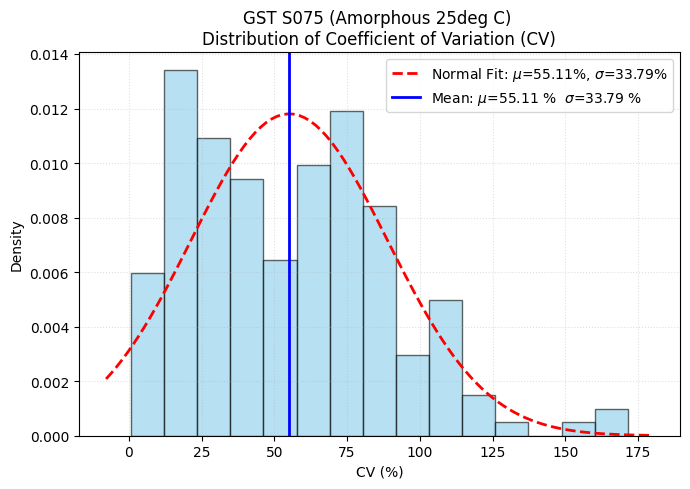

In [224]:
plt.figure(figsize=(7, 5))
count, bins, ignored = plt.hist(
    cv_plot_data['CV (%)'],
    bins=15,
    density=True,
    alpha=0.6,
    color='skyblue',
    edgecolor='black',
)

mu, std = stats.norm.fit(cv_plot_data['CV (%)'])
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, mu, std)
plt.plot(
    x,
    p,
    'r--',
    linewidth=2,
    label=f'Normal Fit: $\mu$={mu:.2f}%, $\sigma$={std:.2f}%',
)

plt.axvline(mu, color="blue", linestyle="-", linewidth=2, label=rf"Mean: $\mu$={mu:.2f} %" + rf"  $\sigma$={std:.2f} %")

plt.title('GST S075 (Amorphous 25deg C) \nDistribution of Coefficient of Variation (CV)')
plt.xlabel('CV (%)')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()

In [225]:
# Statistical Result
print("--- STATISTICAL VALIDATION RESULTS ---")
print(f"Total Measurements (N): {n}")
print(f"Mean Bulk Resistivity:  {mu:.3e} Ω/sq")
print(f"Standard Deviation (σ): {std:.3e} Ω/sq")
print(f"95% Confidence Range:   [{ci_lower:.3e} to {ci_upper:.3e}] Ω/sq")
print(f"Relative Standard Error:{((std / mu) * 100):.3e}%")

# 1-sigma range
one_sigma_lower = mu - std
one_sigma_upper = mu + std
points_in_one_sigma = cv_plot_data['CV (%)'][(cv_plot_data['CV (%)'] >= one_sigma_lower) & (cv_plot_data['CV (%)'] <= one_sigma_upper)]
print(f"\n1-Sigma Range: [{one_sigma_lower:.3e} to {one_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 1-sigma: {len(points_in_one_sigma)} ({(len(points_in_one_sigma) / len(cv_plot_data['CV (%)'])) * 100:.2f}%) ")

# 2-sigma range
two_sigma_lower = mu - (2 * std)
two_sigma_upper = mu + (2 * std)
points_in_two_sigma = cv_plot_data['CV (%)'][(cv_plot_data['CV (%)'] >= two_sigma_lower) & (cv_plot_data['CV (%)'] <= two_sigma_upper)]
print(f"2-Sigma Range: [{two_sigma_lower:.3e} to {two_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 2-sigma: {len(points_in_two_sigma)} ({(len(points_in_two_sigma) / len(cv_plot_data['CV (%)'])) * 100:.2f}%) ")

# 3-sigma range
three_sigma_lower = mu - (3 * std)
three_sigma_upper = mu + (3 * std)
points_in_three_sigma = cv_plot_data['CV (%)'][(cv_plot_data['CV (%)'] >= three_sigma_lower) & (cv_plot_data['CV (%)'] <= three_sigma_upper)]
print(f"3-Sigma Range: [{three_sigma_lower:.3e} to {three_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 3-sigma: {len(points_in_three_sigma)} ({(len(points_in_three_sigma) / len(cv_plot_data['CV (%)'])) * 100:.2f}%) ")

--- STATISTICAL VALIDATION RESULTS ---
Total Measurements (N): 96
Mean Bulk Resistivity:  5.511e+01 Ω/sq
Standard Deviation (σ): 3.379e+01 Ω/sq
95% Confidence Range:   [1.153e+00 to 1.458e+00] Ω/sq
Relative Standard Error:6.132e+01%

1-Sigma Range: [2.132e+01 to 8.891e+01] Ω/sq
Number of points within 1-sigma: 120 (67.80%) 
2-Sigma Range: [-1.247e+01 to 1.227e+02] Ω/sq
Number of points within 2-sigma: 172 (97.18%) 
3-Sigma Range: [-4.627e+01 to 1.565e+02] Ω/sq
Number of points within 3-sigma: 175 (98.87%) 


###GST Repeatability 200c



In [226]:
#gst repeatability 3 times measure
df_gst_test1 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_full_scan_200c_1.csv')
df_gst_test2 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_full_scan_200c_2.csv')
df_gst_test3 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_full_scan_200c_3.csv')

dataframes = [
    (df_gst_test1, 'Run 1 (df_gst_test1)'),
    (df_gst_test2, 'Run 2 (df_gst_test2)'),
    (df_gst_test3, 'Run 3 (df_gst_test3)')]

#fill in missing values (where delta_mV is 2047)
for i, (df, title) in enumerate(dataframes):
  fill_ohm = df['Delta_mV'] / (df['A2_mV'] / 1000)
  df['R_Ohms'] = df['R_Ohms'].fillna(fill_ohm)
  df['Rs_Ohm_sq'] = df['Rs_Ohm_sq'].fillna(df['R_Ohms'] * math.pi/math.log(2))

In [227]:
df_gst_test1.head(10)

,Node_ID,Row,Col,X_mm,Y_mm,Delta_mV,A2_mV,R_Ohms,Rs_Ohm_sq,Rs_MOhm_sq
0,1,1,1,-162,-110,797.1700,11.3213,70413.291760,319138.397027,NaN
1,2,1,2,-156,-110,929.9000,14.4138,64514.562433,292403.231340,NaN
2,3,1,3,-150,-110,1134.0850,10.1775,111430.606731,505043.640525,NaN
3,4,1,4,-144,-110,495.0025,428.5013,1155.194862,5235.759147,NaN
4,5,1,5,-138,-110,149.6475,759.3013,197.085795,893.263800,NaN
5,6,2,9,-126,-104,56.2125,727.7888,77.237380,350.067622,NaN
6,7,2,8,-132,-104,130.9500,726.1625,180.331537,817.327472,NaN
7,8,2,7,-138,-104,434.3475,695.0862,624.882928,2832.194477,NaN
8,9,2,6,-144,-104,408.7125,243.3275,1679.680677,7612.917753,NaN
9,10,2,5,-150,-104,967.9050,4.4413,217932.812465,987749.992812,NaN


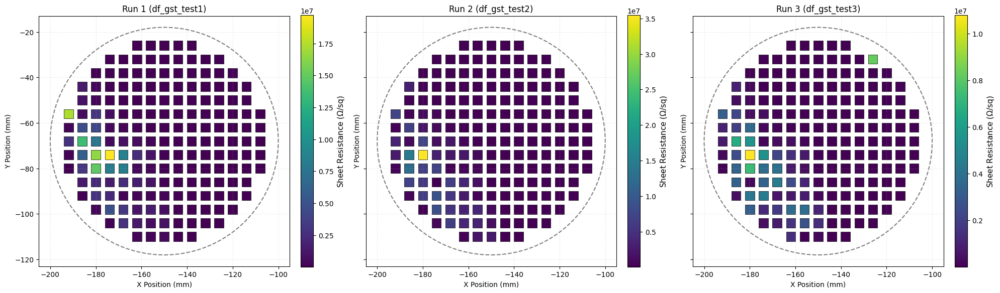

In [228]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10), sharex=True, sharey=True)
axes = axes.flatten() # Flatten the 2x3 array of axes for easier iteration

wafer_radius = 50  # mm

for i, (df, title) in enumerate(dataframes):
    ax = axes[i]
    # Drop rows with NaN in 'Rs_Ohm_sq' and filter out negative Rs_Ohm_sq values
    df_cleaned = df.dropna(subset=['Rs_Ohm_sq'])
    df_cleaned = df_cleaned[df_cleaned['Rs_Ohm_sq'] >= 0]

    sc = ax.scatter(
        df_cleaned['X_mm'],
        df_cleaned['Y_mm'],
        c=df_cleaned['Rs_Ohm_sq'],
        cmap='viridis',
        marker='s',  # Square markers
        s=180,  # Marker size (points^2)
        edgecolors='black',  # Border around each cell
        linewidth=0.5,
    )

    # Add wafer circular outline with new center
    wafer_outline = plt.Circle(
        (-150, -68), wafer_radius, color='gray', fill=False, linestyle='--', linewidth=1.5
    )
    ax.add_patch(wafer_outline)

    # Enforce strictly square aspect ratio and set bounds
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(-wafer_radius - 5 - 150, wafer_radius + 5 - 150) # Adjust x-limits for new center
    ax.set_ylim(-wafer_radius - 5 - 68, wafer_radius + 5 - 68)   # Adjust y-limits for new center

    # Labels and colorbar
    cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(r'Sheet Resistance ($\Omega$/sq)', fontsize=11)

    ax.set_title(title, fontsize=12)
    ax.set_xlabel('X Position (mm)', fontsize=10)
    ax.set_ylabel('Y Position (mm)', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.4)

# Turn off any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

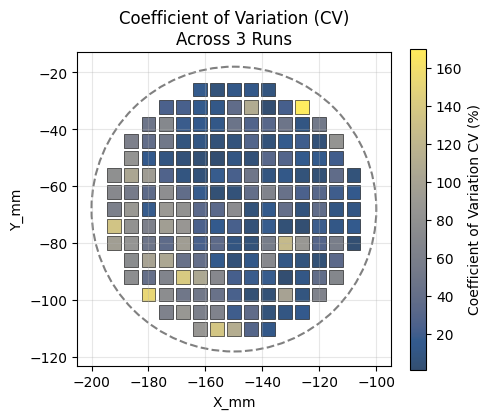

In [229]:
df1_prep = df_gst_test1[['X_mm', 'Y_mm', 'Rs_Ohm_sq']].dropna(subset=['Rs_Ohm_sq']).rename(columns={'Rs_Ohm_sq': 'Rs_Ohm_sq_run1'})
df2_prep = df_gst_test2[['X_mm', 'Y_mm', 'Rs_Ohm_sq']].dropna(subset=['Rs_Ohm_sq']).rename(columns={'Rs_Ohm_sq': 'Rs_Ohm_sq_run2'})
df3_prep = df_gst_test3[['X_mm', 'Y_mm', 'Rs_Ohm_sq']].dropna(subset=['Rs_Ohm_sq']).rename(columns={'Rs_Ohm_sq': 'Rs_Ohm_sq_run3'})

# Merge the dataframes based on X_mm and Y_mm. Use 'inner' to ensure all three runs have data for a point.
df_combined = pd.merge(df1_prep, df2_prep, on=['X_mm', 'Y_mm'], how='inner')
df_combined = pd.merge(df_combined, df3_prep, on=['X_mm', 'Y_mm'], how='inner')


# Calculate mean and standard deviation of Rs_Ohm_sq across the three runs for each point
rs_cols = ['Rs_Ohm_sq_run1', 'Rs_Ohm_sq_run2', 'Rs_Ohm_sq_run3']
df_combined['Rs_mean'] = df_combined[rs_cols].mean(axis=1)
df_combined['Rs_std'] = df_combined[rs_cols].std(axis=1)

# Calculate Coefficient of Variation (CV)
df_combined['CV (%)'] = (df_combined['Rs_std'] / df_combined['Rs_mean']) * 100

# Drop rows where CV is NaN (e.g., if Rs_mean was 0 or std was NaN for any point)
df_combined = df_combined.dropna(subset=['CV (%)'])

# The final data for plotting
cv_plot_data = df_combined
plt.figure(figsize=(5, 5))
wafer_radius = 50
scatter = plt.scatter(cv_plot_data['X_mm'], cv_plot_data['Y_mm'],
                      c=cv_plot_data['CV (%)'], cmap='cividis', marker= 's', s=100, edgecolor='black', alpha=0.8, linewidth=0.5,)

plt.colorbar(scatter, label='Coefficient of Variation CV (%)', shrink=0.7)

# Add wafer circular outline with new center
wafer_outline = plt.Circle(
    (-150, -68), wafer_radius, color='gray', fill=False, linestyle='--', linewidth=1.5
)
plt.gca().add_patch(wafer_outline)

# Enforce strictly square aspect ratio and set bounds
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 - 150, wafer_radius + 5 - 150) # Adjust x-limits for new center
plt.gca().set_ylim(-wafer_radius - 5 - 68, wafer_radius + 5 - 68)   # Adjust y-limits for new center

plt.title('Coefficient of Variation (CV)\nAcross 3 Runs')
plt.xlabel('X_mm')
plt.ylabel('Y_mm')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2653/481337962.py:20: SyntaxWarning: invalid escape sequence '\m'
  label=f'Normal Fit: $\mu$={mu:.2f}%, $\sigma$={std:.2f}%',
/tmp/ipykernel_2653/481337962.py:20: SyntaxWarning: invalid escape sequence '\s'
  label=f'Normal Fit: $\mu$={mu:.2f}%, $\sigma$={std:.2f}%',


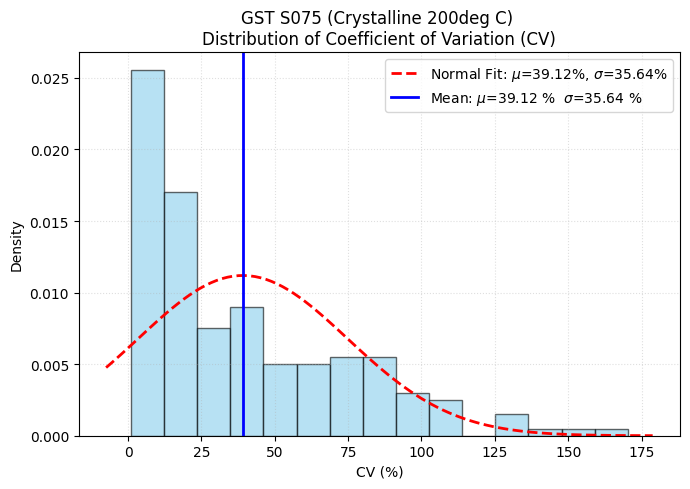

In [230]:
plt.figure(figsize=(7, 5))
count, bins, ignored = plt.hist(
    cv_plot_data['CV (%)'],
    bins=15,
    density=True,
    alpha=0.6,
    color='skyblue',
    edgecolor='black',
)

mu, std = stats.norm.fit(cv_plot_data['CV (%)'])
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, mu, std)
plt.plot(
    x,
    p,
    'r--',
    linewidth=2,
    label=f'Normal Fit: $\mu$={mu:.2f}%, $\sigma$={std:.2f}%',
)

plt.axvline(mu, color="blue", linestyle="-", linewidth=2, label=rf"Mean: $\mu$={mu:.2f} %" + rf"  $\sigma$={std:.2f} %")

plt.title('GST S075 (Crystalline 200deg C) \nDistribution of Coefficient of Variation (CV)')
plt.xlabel('CV (%)')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()

In [231]:
# Statistical Result
print("--- STATISTICAL VALIDATION RESULTS ---")
print(f"Total Measurements (N): {n}")
print(f"Mean Bulk Resistivity:  {mu:.3e} Ω/sq")
print(f"Standard Deviation (σ): {std:.3e} Ω/sq")
print(f"95% Confidence Range:   [{ci_lower:.3e} to {ci_upper:.3e}] Ω/sq")
print(f"Relative Standard Error:{((std / mu) * 100):.3e}%")

# 1-sigma range
one_sigma_lower = mu - std
one_sigma_upper = mu + std
points_in_one_sigma = cv_plot_data['CV (%)'][(cv_plot_data['CV (%)'] >= one_sigma_lower) & (cv_plot_data['CV (%)'] <= one_sigma_upper)]
print(f"\n1-Sigma Range: [{one_sigma_lower:.3e} to {one_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 1-sigma: {len(points_in_one_sigma)} ({(len(points_in_one_sigma) / len(cv_plot_data['CV (%)'])) * 100:.2f}%) ")

# 2-sigma range
two_sigma_lower = mu - (2 * std)
two_sigma_upper = mu + (2 * std)
points_in_two_sigma = cv_plot_data['CV (%)'][(cv_plot_data['CV (%)'] >= two_sigma_lower) & (cv_plot_data['CV (%)'] <= two_sigma_upper)]
print(f"2-Sigma Range: [{two_sigma_lower:.3e} to {two_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 2-sigma: {len(points_in_two_sigma)} ({(len(points_in_two_sigma) / len(cv_plot_data['CV (%)'])) * 100:.2f}%) ")

# 3-sigma range
three_sigma_lower = mu - (3 * std)
three_sigma_upper = mu + (3 * std)
points_in_three_sigma = cv_plot_data['CV (%)'][(cv_plot_data['CV (%)'] >= three_sigma_lower) & (cv_plot_data['CV (%)'] <= three_sigma_upper)]
print(f"3-Sigma Range: [{three_sigma_lower:.3e} to {three_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 3-sigma: {len(points_in_three_sigma)} ({(len(points_in_three_sigma) / len(cv_plot_data['CV (%)'])) * 100:.2f}%) ")

--- STATISTICAL VALIDATION RESULTS ---
Total Measurements (N): 96
Mean Bulk Resistivity:  3.912e+01 Ω/sq
Standard Deviation (σ): 3.564e+01 Ω/sq
95% Confidence Range:   [1.153e+00 to 1.458e+00] Ω/sq
Relative Standard Error:9.109e+01%

1-Sigma Range: [3.484e+00 to 7.476e+01] Ω/sq
Number of points within 1-sigma: 138 (77.97%) 
2-Sigma Range: [-3.215e+01 to 1.104e+02] Ω/sq
Number of points within 2-sigma: 170 (96.05%) 
3-Sigma Range: [-6.779e+01 to 1.460e+02] Ω/sq
Number of points within 3-sigma: 175 (98.87%) 


###GST Repeatability 300c



In [232]:
#gst repeatability 3 times measure
df_gst_test1 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_full_scan_300c_1.csv')
df_gst_test2 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_full_scan_300c_2.csv')
df_gst_test3 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_full_scan_300c_3.csv')

dataframes = [
    (df_gst_test1, 'Run 1 (df_gst_test1)'),
    (df_gst_test2, 'Run 2 (df_gst_test2)'),
    (df_gst_test3, 'Run 3 (df_gst_test3)')]

#fill in missing values (where delta_mV is 2047)
for i, (df, title) in enumerate(dataframes):
  fill_ohm = df['Delta_mV'] / (df['A2_mV'] / 1000)
  df['R_Ohms'] = df['R_Ohms'].fillna(fill_ohm)
  df['Rs_Ohm_sq'] = df['Rs_Ohm_sq'].fillna(df['R_Ohms'] * math.pi/math.log(2))

In [233]:
df_gst_test1.head(100)

,Node_ID,Row,Col,X_mm,Y_mm,Delta_mV,A2_mV,R_Ohms,Rs_Ohm_sq,Rs_MOhm_sq
0,1,1,1,-162,-110,67.6425,717.0837,94.329992,427.537498,NaN
1,2,1,2,-156,-110,48.7825,736.6013,66.226465,300.162189,NaN
2,3,1,3,-150,-110,21.6150,767.8300,28.150763,127.589394,NaN
3,4,1,4,-144,-110,7.8700,743.2562,10.588543,47.991089,NaN
4,5,1,5,-138,-110,4.8125,731.5075,6.578880,29.817853,NaN
...,...,...,...,...,...,...,...,...,...,...
95,96,8,1,-192,-68,1986.9250,20.0225,99234.611063,449766.995870,NaN
96,97,9,1,-192,-62,2058.8826,20.5675,100103.687857,453705.964893,NaN
97,98,9,2,-186,-62,1421.0000,23.2725,61059.190031,276742.239189,NaN
98,99,9,3,-180,-62,583.4200,24.6562,23662.202610,107245.623979,NaN


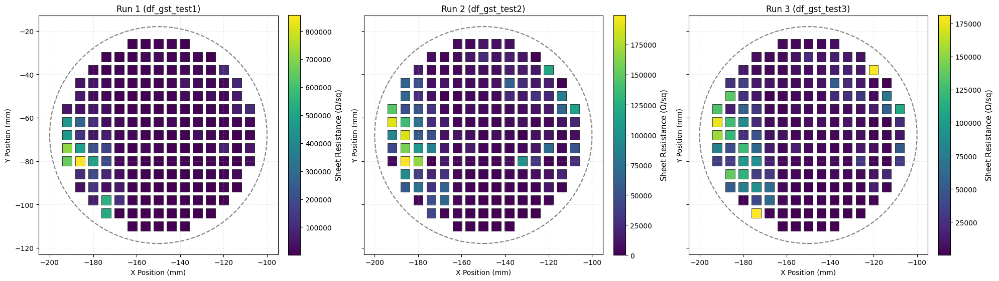

In [234]:
fig, axes = plt.subplots(1, 3, figsize=(20, 10), sharex=True, sharey=True)
axes = axes.flatten() # Flatten the 2x3 array of axes for easier iteration

wafer_radius = 50  # mm

for i, (df, title) in enumerate(dataframes):
    ax = axes[i]
    # Drop rows with NaN in 'Rs_Ohm_sq' and filter out negative Rs_Ohm_sq values
    df_cleaned = df.dropna(subset=['Rs_Ohm_sq'])
    df_cleaned = df_cleaned[df_cleaned['Rs_Ohm_sq'] >= 0]

    sc = ax.scatter(
        df_cleaned['X_mm'],
        df_cleaned['Y_mm'],
        c=df_cleaned['Rs_Ohm_sq'],
        cmap='viridis',
        marker='s',  # Square markers
        s=180,  # Marker size (points^2)
        edgecolors='black',  # Border around each cell
        linewidth=0.5,
    )

    # Add wafer circular outline with new center
    wafer_outline = plt.Circle(
        (-150, -68), wafer_radius, color='gray', fill=False, linestyle='--', linewidth=1.5
    )
    ax.add_patch(wafer_outline)

    # Enforce strictly square aspect ratio and set bounds
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlim(-wafer_radius - 5 - 150, wafer_radius + 5 - 150) # Adjust x-limits for new center
    ax.set_ylim(-wafer_radius - 5 - 68, wafer_radius + 5 - 68)   # Adjust y-limits for new center

    # Labels and colorbar
    cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(r'Sheet Resistance ($\Omega$/sq)', fontsize=11)

    ax.set_title(title, fontsize=12)
    ax.set_xlabel('X Position (mm)', fontsize=10)
    ax.set_ylabel('Y Position (mm)', fontsize=10)
    ax.grid(True, linestyle=':', alpha=0.4)

# Turn off any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

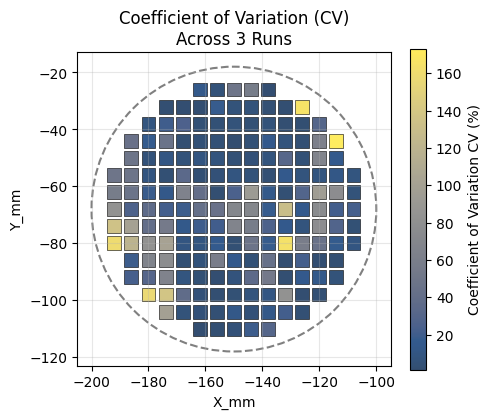

In [235]:
df1_prep = df_gst_test1[['X_mm', 'Y_mm', 'Rs_Ohm_sq']].dropna(subset=['Rs_Ohm_sq']).rename(columns={'Rs_Ohm_sq': 'Rs_Ohm_sq_run1'})
df2_prep = df_gst_test2[['X_mm', 'Y_mm', 'Rs_Ohm_sq']].dropna(subset=['Rs_Ohm_sq']).rename(columns={'Rs_Ohm_sq': 'Rs_Ohm_sq_run2'})
df3_prep = df_gst_test3[['X_mm', 'Y_mm', 'Rs_Ohm_sq']].dropna(subset=['Rs_Ohm_sq']).rename(columns={'Rs_Ohm_sq': 'Rs_Ohm_sq_run3'})

# Merge the dataframes based on X_mm and Y_mm. Use 'inner' to ensure all three runs have data for a point.
df_combined = pd.merge(df1_prep, df2_prep, on=['X_mm', 'Y_mm'], how='inner')
df_combined = pd.merge(df_combined, df3_prep, on=['X_mm', 'Y_mm'], how='inner')


# Calculate mean and standard deviation of Rs_Ohm_sq across the three runs for each point
rs_cols = ['Rs_Ohm_sq_run1', 'Rs_Ohm_sq_run2', 'Rs_Ohm_sq_run3']
df_combined['Rs_mean'] = df_combined[rs_cols].mean(axis=1)
df_combined['Rs_std'] = df_combined[rs_cols].std(axis=1)

# Calculate Coefficient of Variation (CV)
df_combined['CV (%)'] = (df_combined['Rs_std'] / df_combined['Rs_mean']) * 100

# Drop rows where CV is NaN (e.g., if Rs_mean was 0 or std was NaN for any point)
df_combined = df_combined.dropna(subset=['CV (%)'])

# The final data for plotting
cv_plot_data = df_combined
plt.figure(figsize=(5, 5))
wafer_radius = 50
scatter = plt.scatter(cv_plot_data['X_mm'], cv_plot_data['Y_mm'],
                      c=cv_plot_data['CV (%)'], cmap='cividis', marker= 's', s=100, edgecolor='black', alpha=0.8, linewidth=0.5,)

plt.colorbar(scatter, label='Coefficient of Variation CV (%)', shrink=0.7)

# Add wafer circular outline with new center
wafer_outline = plt.Circle(
    (-150, -68), wafer_radius, color='gray', fill=False, linestyle='--', linewidth=1.5
)
plt.gca().add_patch(wafer_outline)

# Enforce strictly square aspect ratio and set bounds
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 - 150, wafer_radius + 5 - 150) # Adjust x-limits for new center
plt.gca().set_ylim(-wafer_radius - 5 - 68, wafer_radius + 5 - 68)   # Adjust y-limits for new center

plt.title('Coefficient of Variation (CV)\nAcross 3 Runs')
plt.xlabel('X_mm')
plt.ylabel('Y_mm')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\m'
<>:20: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2653/3683091695.py:20: SyntaxWarning: invalid escape sequence '\m'
  label=f'Normal Fit: $\mu$={mu:.2f}%, $\sigma$={std:.2f}%',
/tmp/ipykernel_2653/3683091695.py:20: SyntaxWarning: invalid escape sequence '\s'
  label=f'Normal Fit: $\mu$={mu:.2f}%, $\sigma$={std:.2f}%',


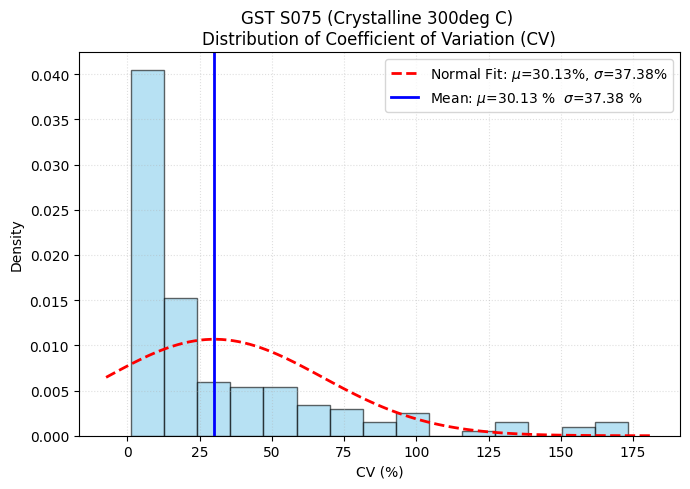

In [236]:
plt.figure(figsize=(7, 5))
count, bins, ignored = plt.hist(
    cv_plot_data['CV (%)'],
    bins=15,
    density=True,
    alpha=0.6,
    color='skyblue',
    edgecolor='black',
)

mu, std = stats.norm.fit(cv_plot_data['CV (%)'])
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, mu, std)
plt.plot(
    x,
    p,
    'r--',
    linewidth=2,
    label=f'Normal Fit: $\mu$={mu:.2f}%, $\sigma$={std:.2f}%',
)

plt.axvline(mu, color="blue", linestyle="-", linewidth=2, label=rf"Mean: $\mu$={mu:.2f} %" + rf"  $\sigma$={std:.2f} %")

plt.title('GST S075 (Crystalline 300deg C) \nDistribution of Coefficient of Variation (CV)')
plt.xlabel('CV (%)')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()

In [237]:
# Statistical Result
print("--- STATISTICAL VALIDATION RESULTS ---")
print(f"Total Measurements (N): {n}")
print(f"Mean Bulk Resistivity:  {mu:.3e} Ω/sq")
print(f"Standard Deviation (σ): {std:.3e} Ω/sq")
print(f"95% Confidence Range:   [{ci_lower:.3e} to {ci_upper:.3e}] Ω/sq")
print(f"Relative Standard Error:{((std / mu) * 100):.3e}%")

# 1-sigma range
one_sigma_lower = mu - std
one_sigma_upper = mu + std
points_in_one_sigma = cv_plot_data['CV (%)'][(cv_plot_data['CV (%)'] >= one_sigma_lower) & (cv_plot_data['CV (%)'] <= one_sigma_upper)]
print(f"\n1-Sigma Range: [{one_sigma_lower:.3e} to {one_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 1-sigma: {len(points_in_one_sigma)} ({(len(points_in_one_sigma) / len(cv_plot_data['CV (%)'])) * 100:.2f}%) ")

# 2-sigma range
two_sigma_lower = mu - (2 * std)
two_sigma_upper = mu + (2 * std)
points_in_two_sigma = cv_plot_data['CV (%)'][(cv_plot_data['CV (%)'] >= two_sigma_lower) & (cv_plot_data['CV (%)'] <= two_sigma_upper)]
print(f"2-Sigma Range: [{two_sigma_lower:.3e} to {two_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 2-sigma: {len(points_in_two_sigma)} ({(len(points_in_two_sigma) / len(cv_plot_data['CV (%)'])) * 100:.2f}%) ")

# 3-sigma range
three_sigma_lower = mu - (3 * std)
three_sigma_upper = mu + (3 * std)
points_in_three_sigma = cv_plot_data['CV (%)'][(cv_plot_data['CV (%)'] >= three_sigma_lower) & (cv_plot_data['CV (%)'] <= three_sigma_upper)]
print(f"3-Sigma Range: [{three_sigma_lower:.3e} to {three_sigma_upper:.3e}] Ω/sq")
print(f"Number of points within 3-sigma: {len(points_in_three_sigma)} ({(len(points_in_three_sigma) / len(cv_plot_data['CV (%)'])) * 100:.2f}%) ")

--- STATISTICAL VALIDATION RESULTS ---
Total Measurements (N): 96
Mean Bulk Resistivity:  3.013e+01 Ω/sq
Standard Deviation (σ): 3.738e+01 Ω/sq
95% Confidence Range:   [1.153e+00 to 1.458e+00] Ω/sq
Relative Standard Error:1.241e+02%

1-Sigma Range: [-7.249e+00 to 6.752e+01] Ω/sq
Number of points within 1-sigma: 154 (87.01%) 
2-Sigma Range: [-4.463e+01 to 1.049e+02] Ω/sq
Number of points within 2-sigma: 168 (94.92%) 
3-Sigma Range: [-8.202e+01 to 1.423e+02] Ω/sq
Number of points within 3-sigma: 172 (97.18%) 


## Reflectance Measurement


###Parameters and Channel Order

In [239]:
DARK_REF = {
    'F1_405nm': 0, 'F2_425nm': 0, 'FZ_450nm': 0, 'F3_475nm': 0,
    'F4_515nm': 0, 'F5_550nm': 0, 'FY_555nm': 0, 'FXL_600nm': 0,
    'F6_640nm': 0, 'F7_690nm': 0, 'F8_745nm': 0, 'NIR_855nm': 0,
    'VIS_1': 0
}

In [240]:
WHITE_REF_15MM_12MA = {
    'F1_405nm': 227,
    'F2_425nm': 258,
    'FZ_450nm': 227,
    'F3_475nm': 263,
    'F4_515nm': 389,
    'F5_550nm': 326,
    'FY_555nm': 815,
    'FXL_600nm': 928,
    'F6_640nm': 907,
    'F7_690nm': 494,
    'F8_745nm': 213,
    'NIR_855nm': 263,
    'VIS_1': 881
}

In [241]:
# channel_order = [
#     ('F1_405nm', '405 nm (F1)'),
#     ('F2_425nm', '425 nm (F2)'),
#     ('FZ_450nm', '450 nm (FZ)'),
#     ('F3_475nm', '475 nm (F3)'),
#     ('F4_515nm', '515 nm (F4)'),
#     ('F5_550nm', '550 nm (F5)'),
#     ('FY_555nm', '555 nm (FY)'),
#     ('FXL_600nm', '600 nm (FXL)'),
#     ('F6_640nm', '640 nm (F6)'),
#     ('F7_690nm', '690 nm (F7)'),
#     ('F8_745nm', '745 nm (F8)'),
#     ('NIR_855nm', '855 nm (NIR)'),
#     ('VIS_1', 'Broadband (VIS_1)'),
# ]

channel_order = [
    ('F1_405nm', '405 nm (F1)'),
    ('F6_640nm', '640 nm (F6)'),
    ('NIR_855nm', '855 nm (NIR)'),
]

### Aluminium

In [242]:
#aluminium Load the CSV files into pandas DataFrames
df_al_spectral = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/spectral_scan_full_18ch_alumfoil.csv')

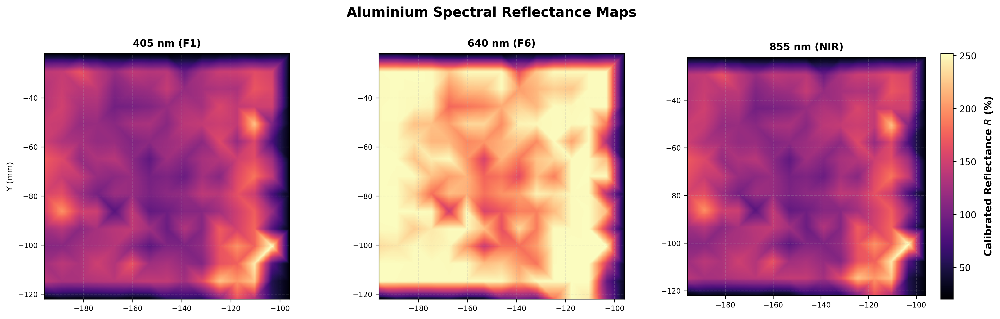

In [243]:
for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_al_spectral[f'{ch}_Refl_pct'] = ((df_al_spectral[ch] - d) / (w - d)) * 100.0

# 3. Geometry setup for 10 cm wafer circle
center_x = (df_al_spectral['X_mm'].min() + df_al_spectral['X_mm'].max()) / 2.0  # -146.0 mm
center_y = (df_al_spectral['Y_mm'].min() + df_al_spectral['Y_mm'].max()) / 2.0  #  -72.0 mm
radius_mm = 50.0  # 100 mm diameter

grid_x, grid_y = np.meshgrid(
    np.linspace(df_al_spectral['X_mm'].min(), df_al_spectral['X_mm'].max(), 300),
    np.linspace(df_al_spectral['Y_mm'].min(), df_al_spectral['Y_mm'].max(), 300),
)
mask_circle = (grid_x - center_x) ** 2 + (grid_y - center_y) ** 2 <= (
    radius_mm
) ** 2

theta = np.linspace(0, 2 * np.pi, 200)
circ_x = center_x + radius_mm * np.cos(theta)
circ_y = center_y + radius_mm * np.sin(theta)

# 4. Plot 4x4 Grid
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)
axes = axes.flatten()

for idx, (ch_key, label) in enumerate(channel_order):
  ax = axes[idx]
  col_name = f'{ch_key}_Refl_pct'

  # Interpolate onto regular grid & apply circular mask
  grid_z = griddata(
      (df_al_spectral['X_mm'], df_al_spectral['Y_mm']),
      df_al_spectral[col_name],
      (grid_x, grid_y),
      method='linear',
  )
  # grid_z[~mask_circle] = np.nan # Removed circular mask

  im = ax.imshow(
      grid_z,
      extent=(
          df_al_spectral['X_mm'].min(),
          df_al_spectral['X_mm'].max(),
          df_al_spectral['Y_mm'].min(),
          df_al_spectral['Y_mm'].max(),
      ),
      origin='lower',
      cmap='magma',
  )

  # ax.plot(circ_x, circ_y, 'k-', lw=1.2, alpha=0.9) # Removed circular outline
  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_aspect('equal')
  ax.grid(True, linestyle='--', alpha=0.25)
  ax.tick_params(labelsize=8)

  if idx % 4 == 0:
    ax.set_ylabel('Y (mm)', fontsize=9)
  if idx >= 9:
    ax.set_xlabel('X (mm)', fontsize=9)

for extra_idx in range(len(channel_order), len(axes)):
  fig.delaxes(axes[extra_idx])

# Shared colorbar
cbar = fig.colorbar(im, orientation='vertical')
cbar.set_label(
    'Calibrated Reflectance $R$ (%)', fontsize=11, fontweight='bold', labelpad=8
)

fig.suptitle(
    'Aluminium Spectral Reflectance Maps',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

### Graphite

In [244]:
#aluminium Load the CSV files into pandas DataFrames
df_graphite_smiley = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/spectral_scan_full_18ch_mistersmiley.csv')
df_graphite_2side = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/spectral_scan_full_18ch_graphite.csv')

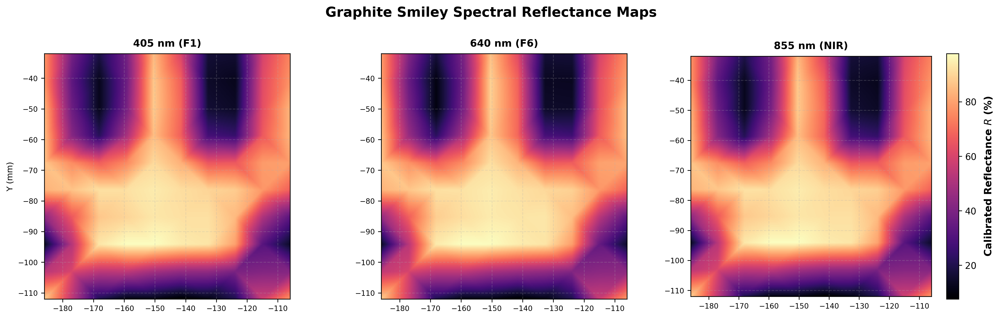

--- Reflectance Cluster Analysis for Graphite Smiley ---

Cluster: Dark (N=23)
  F1_405nm_Refl_pct:
    Mean: 17.18%
    Std Dev: 7.40
    CV%: 43.07%
  F6_640nm_Refl_pct:
    Mean: 28.56%
    Std Dev: 7.24
    CV%: 25.36%
  NIR_855nm_Refl_pct:
    Mean: 18.14%
    Std Dev: 7.35
    CV%: 40.52%

Cluster: Intermediary (N=35)
  F1_405nm_Refl_pct:
    Mean: 52.72%
    Std Dev: 11.08
    CV%: 21.02%
  F6_640nm_Refl_pct:
    Mean: 60.56%
    Std Dev: 9.28
    CV%: 15.32%
  NIR_855nm_Refl_pct:
    Mean: 53.72%
    Std Dev: 11.00
    CV%: 20.47%

Cluster: Light (N=42)
  F1_405nm_Refl_pct:
    Mean: 85.56%
    Std Dev: 6.46
    CV%: 7.55%
  F6_640nm_Refl_pct:
    Mean: 89.09%
    Std Dev: 5.44
    CV%: 6.10%
  NIR_855nm_Refl_pct:
    Mean: 86.21%
    Std Dev: 6.33
    CV%: 7.35%


In [245]:
for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_graphite_smiley[f'{ch}_Refl_pct'] = ((df_graphite_smiley[ch] - d) / (w - d)) * 100.0

# 3. Geometry setup for 10 cm wafer circle
center_x = (df_graphite_smiley['X_mm'].min() + df_graphite_smiley['X_mm'].max()) / 2.0  # -146.0 mm
center_y = (df_graphite_smiley['Y_mm'].min() + df_graphite_smiley['Y_mm'].max()) / 2.0  #  -72.0 mm
radius_mm = 50.0  # 100 mm diameter

grid_x, grid_y = np.meshgrid(
    np.linspace(df_graphite_smiley['X_mm'].min(), df_graphite_smiley['X_mm'].max(), 300),
    np.linspace(df_graphite_smiley['Y_mm'].min(), df_graphite_smiley['Y_mm'].max(), 300),
)
mask_circle = (grid_x - center_x) ** 2 + (grid_y - center_y) ** 2 <= (
    radius_mm
) ** 2

theta = np.linspace(0, 2 * np.pi, 200)
circ_x = center_x + radius_mm * np.cos(theta)
circ_y = center_y + radius_mm * np.sin(theta)

# 4. Plot 4x4 Grid
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)
axes = axes.flatten()

for idx, (ch_key, label) in enumerate(channel_order):
  ax = axes[idx]
  col_name = f'{ch_key}_Refl_pct'

  # Interpolate onto regular grid & apply circular mask
  grid_z = griddata(
      (df_graphite_smiley['X_mm'], df_graphite_smiley['Y_mm']),
      df_graphite_smiley[col_name],
      (grid_x, grid_y),
      method='linear',
  )
  # grid_z[~mask_circle] = np.nan # Removed circular mask

  im = ax.imshow(
      grid_z,
      extent=(
          df_graphite_smiley['X_mm'].min(),
          df_graphite_smiley['X_mm'].max(),
          df_graphite_smiley['Y_mm'].min(),
          df_graphite_smiley['Y_mm'].max(),
      ),
      origin='lower',
      cmap='magma',
  )

  # ax.plot(circ_x, circ_y, 'k-', lw=1.2, alpha=0.9) # Removed circular outline
  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_aspect('equal')
  ax.grid(True, linestyle='--', alpha=0.25)
  ax.tick_params(labelsize=8)

  if idx % 4 == 0:
    ax.set_ylabel('Y (mm)', fontsize=9)
  if idx >= 9:
    ax.set_xlabel('X (mm)', fontsize=9)

for extra_idx in range(len(channel_order), len(axes)):
  fig.delaxes(axes[extra_idx])

# Shared colorbar
cbar = fig.colorbar(im, orientation='vertical')
cbar.set_label(
    'Calibrated Reflectance $R$ (%)', fontsize=11, fontweight='bold', labelpad=8
)

fig.suptitle(
    'Graphite Smiley Spectral Reflectance Maps',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

# Clustering for dark, light and intermediary parts
from sklearn.cluster import KMeans

reflectance_cols = [f'{ch_key}_Refl_pct' for ch_key, _ in channel_order]

df_clustering = df_graphite_smiley[reflectance_cols].dropna()

if len(df_clustering) > 0:
  kmeans = KMeans(n_clusters=3, random_state=0, n_init=10) # Set n_init to suppress warning
  df_clustering['cluster'] = kmeans.fit_predict(df_clustering)

  # Sort clusters by their mean reflectance to identify dark, intermediary, light
  cluster_means = df_clustering.groupby('cluster')[reflectance_cols].mean().mean(axis=1)
  sorted_clusters = cluster_means.sort_values().index

  cluster_labels = {
      sorted_clusters[0]: 'Dark',
      sorted_clusters[1]: 'Intermediary',
      sorted_clusters[2]: 'Light',
  }

  print('--- Reflectance Cluster Analysis for Graphite Smiley ---')
  for cluster_id, label in cluster_labels.items():
    cluster_data = df_clustering[df_clustering['cluster'] == cluster_id]
    mean_vals = cluster_data[reflectance_cols].mean()
    std_vals = cluster_data[reflectance_cols].std()
    cv_vals = (std_vals / mean_vals) * 100

    print(f'\nCluster: {label} (N={len(cluster_data)})')
    for col in reflectance_cols:
      print(f'  {col}:')
      print(f'    Mean: {mean_vals[col]:.2f}%')
      print(f'    Std Dev: {std_vals[col]:.2f}')
      print(f'    CV%: {cv_vals[col]:.2f}%')
else:
  print('Insufficient data for clustering after dropping NaNs.')

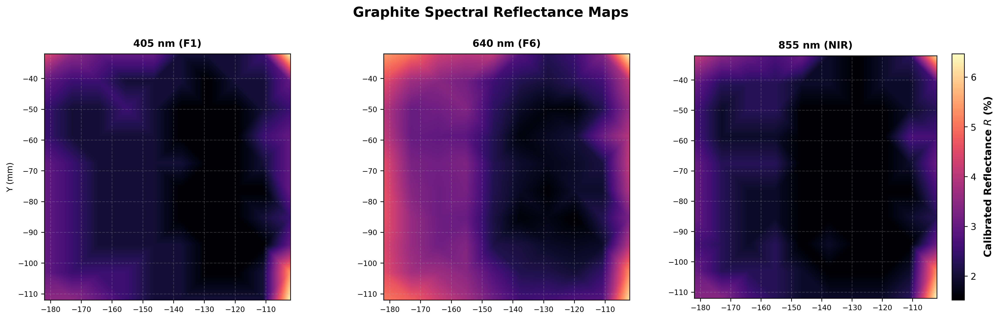

In [246]:
for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_graphite_2side[f'{ch}_Refl_pct'] = ((df_graphite_2side[ch] - d) / (w - d)) * 100.0

# 3. Geometry setup for 10 cm wafer circle
center_x = (df_graphite_2side['X_mm'].min() + df_graphite_2side['X_mm'].max()) / 2.0  # -146.0 mm
center_y = (df_graphite_2side['Y_mm'].min() + df_graphite_2side['Y_mm'].max()) / 2.0  #  -72.0 mm
radius_mm = 50.0  # 100 mm diameter

grid_x, grid_y = np.meshgrid(
    np.linspace(df_graphite_2side['X_mm'].min(), df_graphite_2side['X_mm'].max(), 300),
    np.linspace(df_graphite_2side['Y_mm'].min(), df_graphite_2side['Y_mm'].max(), 300),
)
mask_circle = (grid_x - center_x) ** 2 + (grid_y - center_y) ** 2 <= (
    radius_mm
) ** 2

theta = np.linspace(0, 2 * np.pi, 200)
circ_x = center_x + radius_mm * np.cos(theta)
circ_y = center_y + radius_mm * np.sin(theta)

# 4. Plot 4x4 Grid
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)
axes = axes.flatten()

for idx, (ch_key, label) in enumerate(channel_order):
  ax = axes[idx]
  col_name = f'{ch_key}_Refl_pct'

  # Interpolate onto regular grid & apply circular mask
  grid_z = griddata(
      (df_graphite_2side['X_mm'], df_graphite_2side['Y_mm']),
      df_graphite_2side[col_name],
      (grid_x, grid_y),
      method='linear',
  )
  # grid_z[~mask_circle] = np.nan # Removed circular mask

  im = ax.imshow(
      grid_z,
      extent=(
          df_graphite_2side['X_mm'].min(),
          df_graphite_2side['X_mm'].max(),
          df_graphite_2side['Y_mm'].min(),
          df_graphite_2side['Y_mm'].max(),
      ),
      origin='lower',
      cmap='magma',

  )

  # ax.plot(circ_x, circ_y, 'k-', lw=1.2, alpha=0.9) # Removed circular outline
  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_aspect('equal')
  ax.grid(True, linestyle='--', alpha=0.25)
  ax.tick_params(labelsize=8)

  if idx % 4 == 0:
    ax.set_ylabel('Y (mm)', fontsize=9)
  if idx >= 9:
    ax.set_xlabel('X (mm)', fontsize=9)

for extra_idx in range(len(channel_order), len(axes)):
  fig.delaxes(axes[extra_idx])

# Shared colorbar
cbar = fig.colorbar(im, orientation='vertical')
cbar.set_label(
    'Calibrated Reflectance $R$ (%)', fontsize=11, fontweight='bold', labelpad=8
)

fig.suptitle(
    'Graphite Spectral Reflectance Maps',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

### GST

In [247]:
#gst Load the CSV files into pandas DataFrames
df_gst_spectral = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/spectral_scan_full_18ch_wafer3.csv')
df_gst_spectral2 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/crystalline_refle2.csv')
df_gst_spectral3 = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/300_refle2.csv')

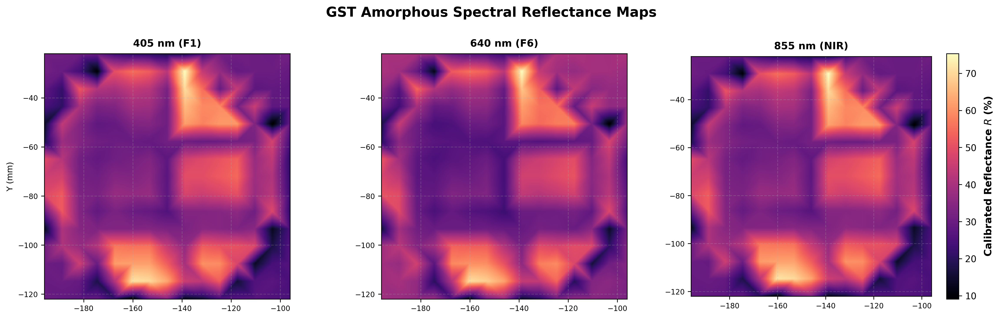

In [248]:
for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_gst_spectral[f'{ch}_Refl_pct'] = ((df_gst_spectral[ch] - d) / (w - d)) * 100.0

# 3. Geometry setup for 10 cm wafer circle
center_x = (df_gst_spectral['X_mm'].min() + df_gst_spectral['X_mm'].max()) / 2.0  # -146.0 mm
center_y = (df_gst_spectral['Y_mm'].min() + df_gst_spectral['Y_mm'].max()) / 2.0  #  -72.0 mm
radius_mm = 50.0  # 100 mm diameter

grid_x, grid_y = np.meshgrid(
    np.linspace(df_gst_spectral['X_mm'].min(), df_gst_spectral['X_mm'].max(), 300),
    np.linspace(df_gst_spectral['Y_mm'].min(), df_gst_spectral['Y_mm'].max(), 300),
)
mask_circle = (grid_x - center_x) ** 2 + (grid_y - center_y) ** 2 <= (
    radius_mm
) ** 2

theta = np.linspace(0, 2 * np.pi, 200)
circ_x = center_x + radius_mm * np.cos(theta)
circ_y = center_y + radius_mm * np.sin(theta)

# 4. Plot 4x4 Grid
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)
axes = axes.flatten()

for idx, (ch_key, label) in enumerate(channel_order):
  ax = axes[idx]
  col_name = f'{ch_key}_Refl_pct'

  # Interpolate onto regular grid & apply circular mask
  grid_z = griddata(
      (df_gst_spectral['X_mm'], df_gst_spectral['Y_mm']),
      df_gst_spectral[col_name],
      (grid_x, grid_y),
      method='linear',
  )
  # grid_z[~mask_circle] = np.nan # Removed circular mask

  im = ax.imshow(
      grid_z,
      extent=(
          df_gst_spectral['X_mm'].min(),
          df_gst_spectral['X_mm'].max(),
          df_gst_spectral['Y_mm'].min(),
          df_gst_spectral['Y_mm'].max(),
      ),
      origin='lower',
      cmap='magma',
  )

  # ax.plot(circ_x, circ_y, 'k-', lw=1.2, alpha=0.9) # Removed circular outline
  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_aspect('equal')
  ax.grid(True, linestyle='--', alpha=0.25)
  ax.tick_params(labelsize=8)

  if idx % 4 == 0:
    ax.set_ylabel('Y (mm)', fontsize=9)
  if idx >= 9:
    ax.set_xlabel('X (mm)', fontsize=9)

for extra_idx in range(len(channel_order), len(axes)):
  fig.delaxes(axes[extra_idx])

# Shared colorbar
cbar = fig.colorbar(im, orientation='vertical')
cbar.set_label(
    'Calibrated Reflectance $R$ (%)', fontsize=11, fontweight='bold', labelpad=8
)

fig.suptitle(
    'GST Amorphous Spectral Reflectance Maps',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

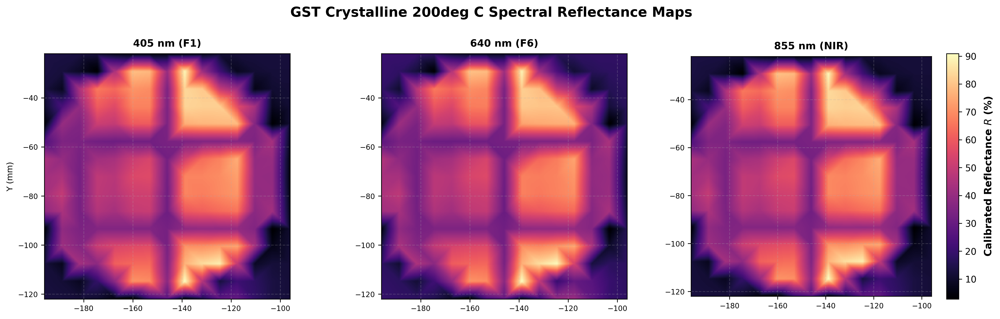

In [249]:
for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_gst_spectral2[f'{ch}_Refl_pct'] = ((df_gst_spectral2[ch] - d) / (w - d)) * 100.0

# 3. Geometry setup for 10 cm wafer circle
center_x = (df_gst_spectral2['X_mm'].min() + df_gst_spectral2['X_mm'].max()) / 2.0  # -146.0 mm
center_y = (df_gst_spectral2['Y_mm'].min() + df_gst_spectral2['Y_mm'].max()) / 2.0  #  -72.0 mm
radius_mm = 50.0  # 100 mm diameter

grid_x, grid_y = np.meshgrid(
    np.linspace(df_gst_spectral2['X_mm'].min(), df_gst_spectral2['X_mm'].max(), 300),
    np.linspace(df_gst_spectral2['Y_mm'].min(), df_gst_spectral2['Y_mm'].max(), 300),
)
mask_circle = (grid_x - center_x) ** 2 + (grid_y - center_y) ** 2 <= (
    radius_mm
) ** 2

theta = np.linspace(0, 2 * np.pi, 200)
circ_x = center_x + radius_mm * np.cos(theta)
circ_y = center_y + radius_mm * np.sin(theta)

# 4. Plot 4x4 Grid
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)
axes = axes.flatten()

for idx, (ch_key, label) in enumerate(channel_order):
  ax = axes[idx]
  col_name = f'{ch_key}_Refl_pct'

  # Interpolate onto regular grid & apply circular mask
  grid_z = griddata(
      (df_gst_spectral2['X_mm'], df_gst_spectral2['Y_mm']),
      df_gst_spectral2[col_name],
      (grid_x, grid_y),
      method='linear',
  )
  # grid_z[~mask_circle] = np.nan # Removed circular mask

  im = ax.imshow(
      grid_z,
      extent=(
          df_gst_spectral2['X_mm'].min(),
          df_gst_spectral2['X_mm'].max(),
          df_gst_spectral2['Y_mm'].min(),
          df_gst_spectral2['Y_mm'].max(),
      ),
      origin='lower',
      cmap='magma',
  )

  # ax.plot(circ_x, circ_y, 'k-', lw=1.2, alpha=0.9) # Removed circular outline
  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_aspect('equal')
  ax.grid(True, linestyle='--', alpha=0.25)
  ax.tick_params(labelsize=8)

  if idx % 4 == 0:
    ax.set_ylabel('Y (mm)', fontsize=9)
  if idx >= 9:
    ax.set_xlabel('X (mm)', fontsize=9)

for extra_idx in range(len(channel_order), len(axes)):
  fig.delaxes(axes[extra_idx])

# Shared colorbar
cbar = fig.colorbar(im, orientation='vertical')
cbar.set_label(
    'Calibrated Reflectance $R$ (%)', fontsize=11, fontweight='bold', labelpad=8
)

fig.suptitle(
    'GST Crystalline 200deg C Spectral Reflectance Maps',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

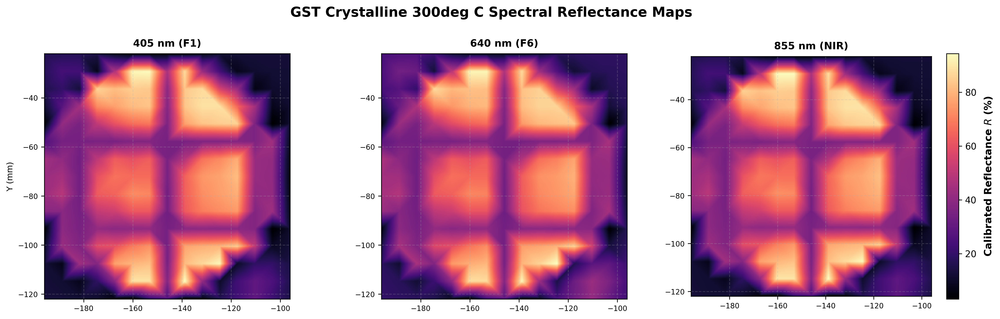

In [250]:
for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_gst_spectral3[f'{ch}_Refl_pct'] = ((df_gst_spectral3[ch] - d) / (w - d)) * 100.0

# 3. Geometry setup for 10 cm wafer circle
center_x = (df_gst_spectral3['X_mm'].min() + df_gst_spectral3['X_mm'].max()) / 2.0  # -146.0 mm
center_y = (df_gst_spectral3['Y_mm'].min() + df_gst_spectral3['Y_mm'].max()) / 2.0  #  -72.0 mm
radius_mm = 50.0  # 100 mm diameter

grid_x, grid_y = np.meshgrid(
    np.linspace(df_gst_spectral3['X_mm'].min(), df_gst_spectral3['X_mm'].max(), 300),
    np.linspace(df_gst_spectral3['Y_mm'].min(), df_gst_spectral3['Y_mm'].max(), 300),
)
mask_circle = (grid_x - center_x) ** 2 + (grid_y - center_y) ** 2 <= (
    radius_mm
) ** 2

theta = np.linspace(0, 2 * np.pi, 200)
circ_x = center_x + radius_mm * np.cos(theta)
circ_y = center_y + radius_mm * np.sin(theta)

# 4. Plot 4x4 Grid
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)
axes = axes.flatten()

for idx, (ch_key, label) in enumerate(channel_order):
  ax = axes[idx]
  col_name = f'{ch_key}_Refl_pct'

  # Interpolate onto regular grid & apply circular mask
  grid_z = griddata(
      (df_gst_spectral3['X_mm'], df_gst_spectral3['Y_mm']),
      df_gst_spectral3[col_name],
      (grid_x, grid_y),
      method='linear',
  )
  # grid_z[~mask_circle] = np.nan # Removed circular mask

  im = ax.imshow(
      grid_z,
      extent=(
          df_gst_spectral3['X_mm'].min(),
          df_gst_spectral3['X_mm'].max(),
          df_gst_spectral3['Y_mm'].min(),
          df_gst_spectral3['Y_mm'].max(),
      ),
      origin='lower',
      cmap='magma',
  )

  # ax.plot(circ_x, circ_y, 'k-', lw=1.2, alpha=0.9) # Removed circular outline
  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_aspect('equal')
  ax.grid(True, linestyle='--', alpha=0.25)
  ax.tick_params(labelsize=8)

  if idx % 4 == 0:
    ax.set_ylabel('Y (mm)', fontsize=9)
  if idx >= 9:
    ax.set_xlabel('X (mm)', fontsize=9)

for extra_idx in range(len(channel_order), len(axes)):
  fig.delaxes(axes[extra_idx])

# Shared colorbar
cbar = fig.colorbar(im, orientation='vertical')
cbar.set_label(
    'Calibrated Reflectance $R$ (%)', fontsize=11, fontweight='bold', labelpad=8
)

fig.suptitle(
    'GST Crystalline 300deg C Spectral Reflectance Maps',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

#Chapter 6: Result

###Import Ref Data

In [251]:
gst_composition = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/S075_xrf_composition.csv')

## GST Resistivity

In [353]:
gst_scan = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/4pp_gst_amorphous_calibrated2_20260826.csv')
fill_ohm = abs(gst_scan['Delta_mV'] / (gst_scan['A2_mV'] / 1000000))
gst_scan['R_Ohms'] = gst_scan['R_Ohms'].fillna(fill_ohm)
gst_scan['Rs_Ohm_sq'] = gst_scan['Rs_Ohm_sq'].fillna(gst_scan['R_Ohms'] * math.pi/math.log(2))
gst_scan['Rs_MOhm_sq'] = gst_scan['Rs_Ohm_sq']/1e6

In [354]:
gst_scan.head(5)

,Node_ID,Row,Col,X_mm,Y_mm,Delta_mV,A2_mV,R_Ohms,Rs_Ohm_sq,Rs_MOhm_sq
0,1,1,1,-162,-110,1000.0938,883.0112,1.132595e+06,5.133327e+06,5.133327
1,2,1,2,-156,-110,1140.8113,2053.5725,5.555252e+05,2.517840e+06,2.517840
2,3,1,3,-150,-110,1117.6425,1580.4750,7.071561e+05,3.205086e+06,3.205086
3,4,1,4,-144,-110,1085.0062,1529.0400,7.095996e+05,3.216161e+06,3.216161
4,5,1,5,-138,-110,1039.9825,1723.9537,6.032543e+05,2.734166e+06,2.734166


###Scan Map

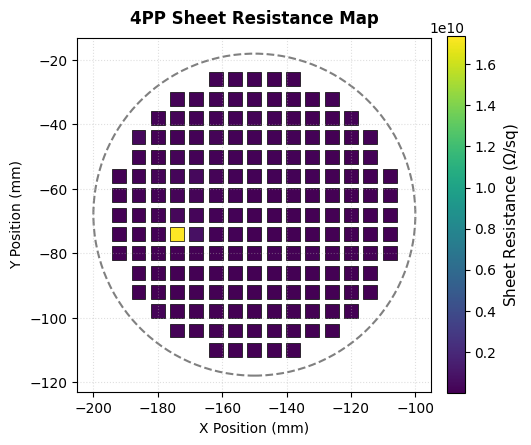

In [355]:
# 1. Create a separate DataFrame for book coordinates from your original gst_scan
gst_scan_book = gst_scan.copy()
gst_scan_book['Row_Book'] = 16 - gst_scan_book['Row']

# 2. Notebook Plotting Code in Book Coordinates
wafer_radius = 50  # mm
center_x, center_y = -150, -68

plt.figure(figsize=(5, 5))

sc = plt.scatter(
    gst_scan_book['X_mm'],
    gst_scan_book['Y_mm'],
    c=gst_scan_book['Rs_Ohm_sq'],
    cmap='viridis',
    marker='s',  # Square markers
    s=100,  # Marker size (points^2)
    edgecolors='black',  # Border around each cell
    linewidth=0.5,
)

# Add wafer circular outline with new center
wafer_outline = plt.Circle(
    (center_x, center_y),
    wafer_radius,
    color='gray',
    fill=False,
    linestyle='--',
    linewidth=1.5,
)
plt.gca().add_patch(wafer_outline)

# Enforce strictly square aspect ratio and set bounds
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
plt.gca().set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

# Labels and colorbar
cbar = plt.colorbar(sc, ax=plt.gca(), fraction=0.046, pad=0.04)
cbar.set_label(r'Sheet Resistance ($\Omega$/sq)', fontsize=11)

plt.gca().set_title(
    '4PP Sheet Resistance Map',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
plt.gca().set_xlabel('X Position (mm)', fontsize=10)
plt.gca().set_ylabel('Y Position (mm)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.4)

plt.show()

###Data Merging Scan and Composition to get Bulk Resistivity

Merge the raw gst scan data and the composition data

In [356]:
# Get XRF composition data
df_xrf = gst_composition.iloc[:177].copy()

# Reconstruct top-down book indexing for XRF
counts_top_to_bottom = [5, 9, 11, 13, 13, 15, 15, 15, 15, 15, 13, 13, 11, 9, 5]
xrf_mapped = []
pt_idx = 0
for r_top_idx, count in enumerate(counts_top_to_bottom):
  row_book_num = r_top_idx + 1
  for col_num in range(1, count + 1):
    row_dict = df_xrf.iloc[pt_idx].to_dict()
    row_dict['Row_Book'] = row_book_num
    row_dict['Col'] = col_num
    xrf_mapped.append(row_dict)
    pt_idx += 1

df_xrf_book = pd.DataFrame(xrf_mapped)

# 3. Merge directly into your existing gst_scan_book DataFrame
gst_scan_book_merged = pd.merge(
    gst_scan_book, df_xrf_book, on=['Row_Book', 'Col']
)

Map Thickness

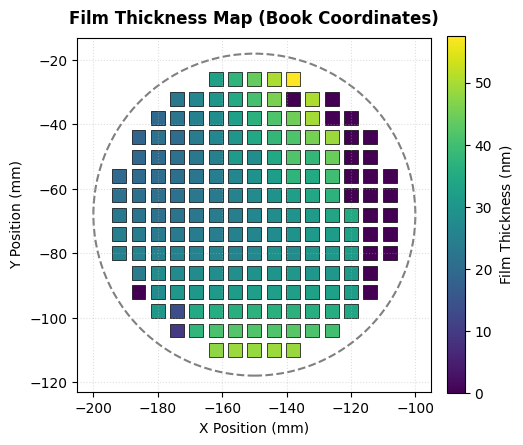

In [357]:
wafer_radius = 50  # mm
center_x, center_y = -150, -68

plt.figure(figsize=(5, 5))

sc = plt.scatter(
    gst_scan_book_merged['X_mm'],
    gst_scan_book_merged['Y_mm'],
    c=gst_scan_book_merged['Thickness (nm)'],
    cmap='viridis',
    marker='s',  # Square markers
    s=100,  # Marker size (points^2)
    edgecolors='black',  # Border around each cell
    linewidth=0.5,
)

# Add wafer circular outline with new center
wafer_outline = plt.Circle(
    (center_x, center_y),
    wafer_radius,
    color='gray',
    fill=False,
    linestyle='--',
    linewidth=1.5,
)
plt.gca().add_patch(wafer_outline)

# Enforce strictly square aspect ratio and set bounds
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
plt.gca().set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

# Labels and colorbar
cbar = plt.colorbar(sc, ax=plt.gca(), fraction=0.046, pad=0.04)
cbar.set_label(r'Film Thickness ($\mathrm{nm}$)', fontsize=10)

plt.gca().set_title(
    'Film Thickness Map (Book Coordinates)',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
plt.gca().set_xlabel('X Position (mm)', fontsize=10)
plt.gca().set_ylabel('Y Position (mm)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.4)

plt.show()

Get Bulk Resistivity

In [358]:
# Calculate bulk resistivity (rho = Rs * thickness)
# Thickness is in nm -> convert to cm by multiplying by 1e-7

gst_scan_book_merged['rho_Ohm_cm'] = gst_scan_book_merged[
    'Rs_Ohm_sq'
] * (gst_scan_book_merged['Thickness (nm)'] * 1e-7)

print(
    'Successfully calculated bulk resistivity for'
    f' {len(gst_scan_book_merged)} nodes!'
)

Successfully calculated bulk resistivity for 177 nodes!


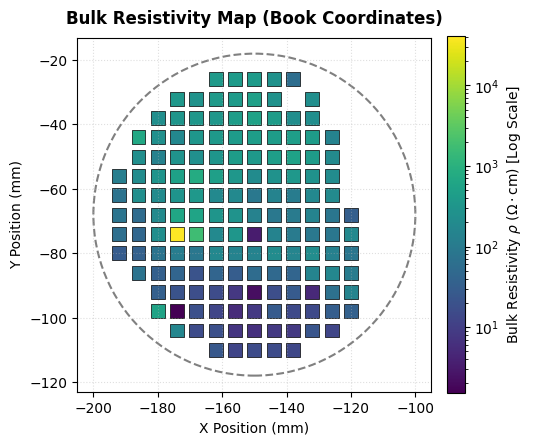

In [359]:
# Filter out non-positive values for log scaling
valid_rho = gst_scan_book_merged[gst_scan_book_merged['rho_Ohm_cm'] > 0].copy()

# 3. Plotting bulk resistivity spatial map
wafer_radius = 50  # mm
center_x, center_y = -150, -68

plt.figure(figsize=(5, 5))

sc = plt.scatter(
    valid_rho['X_mm'],
    valid_rho['Y_mm'],
    c=valid_rho['rho_Ohm_cm'],
    cmap='viridis',
    norm=plt.matplotlib.colors.LogNorm(
        vmin=max(1.0, valid_rho['rho_Ohm_cm'].min()),
        vmax=valid_rho['rho_Ohm_cm'].max(),
    ),
    marker='s',
    s=100,
    edgecolors='black',
    linewidth=0.5,
)

wafer_outline = plt.Circle(
    (center_x, center_y),
    wafer_radius,
    color='gray',
    fill=False,
    linestyle='--',
    linewidth=1.5,
)
plt.gca().add_patch(wafer_outline)

plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
plt.gca().set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

cbar = plt.colorbar(sc, ax=plt.gca(), fraction=0.046, pad=0.04)
cbar.set_label(
    r'Bulk Resistivity $\rho$ ($\Omega \cdot \mathrm{cm}$) [Log Scale]',
    fontsize=10,
)

plt.gca().set_title(
    'Bulk Resistivity Map (Book Coordinates)',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
plt.gca().set_xlabel('X Position (mm)', fontsize=10)
plt.gca().set_ylabel('Y Position (mm)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.4)

plt.show()

### Composition Map

Plot the composition data

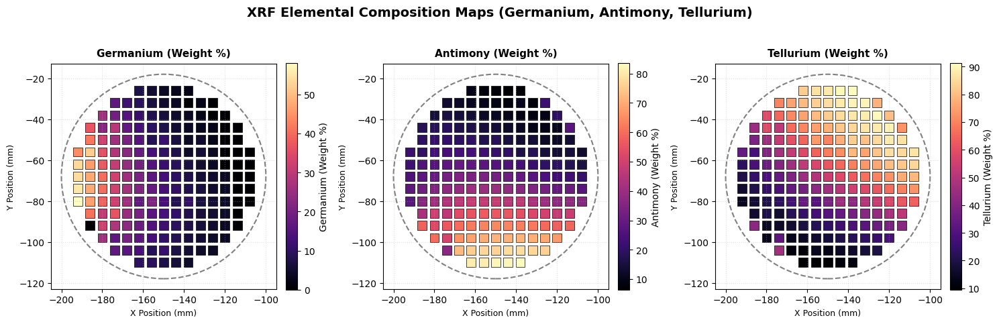

In [360]:
# 3-Subplot Figure Setup (Ge, Sb, Te)
wafer_radius = 50  # mm
center_x, center_y = -150, -68

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

compositions = [
    ('Ge (Weight %)', 'Germanium (Weight %)', 'plasma'),
    ('Sb (Weight %)', 'Antimony (Weight %)', 'coolwarm'),
    ('Te (Weight %)', 'Tellurium (Weight %)', 'cividis'),
]

for idx, (col_name, label, cmap) in enumerate(compositions):
  ax = axes[idx]

  sc = ax.scatter(
      gst_scan_book_merged['X_mm'],
      gst_scan_book_merged['Y_mm'],
      c=gst_scan_book_merged[col_name],
      cmap='magma',
      marker='s',  # Square markers
      s=100,  # Marker size (points^2)
      edgecolors='black',  # Border around each cell
      linewidth=0.5,
  )

  # Add wafer circular outline with new center
  wafer_outline = plt.Circle(
      (center_x, center_y),
      wafer_radius,
      color='gray',
      fill=False,
      linestyle='--',
      linewidth=1.5,
  )
  ax.add_patch(wafer_outline)

  # Enforce strictly square aspect ratio and set bounds
  ax.set_aspect('equal', adjustable='box')
  ax.set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
  ax.set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

  # Labels and colorbar
  cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
  cbar.set_label(label, fontsize=10)

  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_xlabel('X Position (mm)', fontsize=9)
  ax.set_ylabel('Y Position (mm)', fontsize=9)
  ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle(
    'XRF Elemental Composition Maps (Germanium, Antimony, Tellurium)',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

###Ternary Space Mapping

In [361]:
# 1. Convert weight percent to atomic percent
M_Ge, M_Sb, M_Te = 72.64, 121.76, 127.60
gst_scan_book_merged['Ge_mol'] = (
    gst_scan_book_merged['Ge (Weight %)'] / M_Ge
)
gst_scan_book_merged['Sb_mol'] = (
    gst_scan_book_merged['Sb (Weight %)'] / M_Sb
)
gst_scan_book_merged['Te_mol'] = (
    gst_scan_book_merged['Te (Weight %)'] / M_Te
)
tot_mol = (
    gst_scan_book_merged['Ge_mol']
    + gst_scan_book_merged['Sb_mol']
    + gst_scan_book_merged['Te_mol']
)

gst_scan_book_merged['Ge_at'] = (
    gst_scan_book_merged['Ge_mol'] / tot_mol
) * 100.0
gst_scan_book_merged['Sb_at'] = (
    gst_scan_book_merged['Sb_mol'] / tot_mol
) * 100.0
gst_scan_book_merged['Te_at'] = (
    gst_scan_book_merged['Te_mol'] / tot_mol
) * 100.0

# 2. Compute ternary Cartesian coordinates
ge_frac = gst_scan_book_merged['Ge_at'] / 100.0
te_frac = gst_scan_book_merged['Te_at'] / 100.0

gst_scan_book_merged['ternary_x_at'] = te_frac + 0.5 * ge_frac
gst_scan_book_merged['ternary_y_at'] = ge_frac * (np.sqrt(3) / 2.0)

print('Ternary coordinates successfully added to gst_scan_book_merged!')

Ternary coordinates successfully added to gst_scan_book_merged!


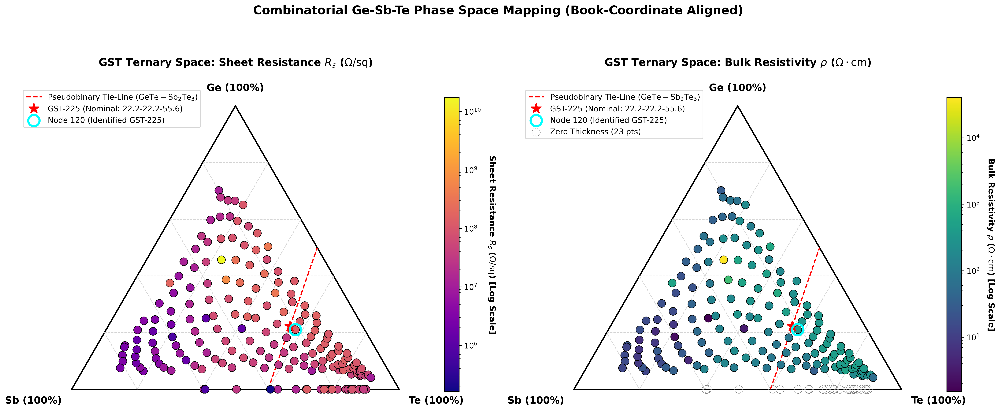

In [362]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np

# 1. Ensure gst_scan_book_merged is fully prepared with atomic percentages and rho
# (gst_scan_book merged with df_xrf_book on ['Row_Book', 'Col'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9.5), dpi=300)
sqrt3_2 = np.sqrt(3) / 2.0


def setup_gst_ternary(ax, title):
  ax.plot([0, 1, 0.5, 0], [0, 0, sqrt3_2, 0], "k-", lw=2.0)

  for p in [0.2, 0.4, 0.6, 0.8]:
    ax.plot(
        [0.5 * p, 1 - 0.5 * p],
        [sqrt3_2 * p, sqrt3_2 * p],
        color="lightgray",
        linestyle="--",
        lw=0.9,
    )
    ax.plot(
        [p, 0.5 * p + 0.5],
        [0, sqrt3_2 * (1 - p)],
        color="lightgray",
        linestyle="--",
        lw=0.9,
    )
    ax.plot(
        [1 - p, 0.5 * (1 - p)],
        [0, sqrt3_2 * (1 - p)],
        color="lightgray",
        linestyle="--",
        lw=0.9,
    )

  ax.text(
      0.5,
      sqrt3_2 + 0.04,
      "Ge (100%)",
      ha="center",
      va="bottom",
      fontsize=14,
      fontweight="bold",
  )
  ax.text(
      -0.03,
      -0.02,
      "Sb (100%)",
      ha="right",
      va="top",
      fontsize=14,
      fontweight="bold",
  )
  ax.text(
      1.03,
      -0.02,
      "Te (100%)",
      ha="left",
      va="top",
      fontsize=14,
      fontweight="bold",
  )

  # Pseudobinary tie-line (GeTe - Sb2Te3)
  ax.plot(
      [0.60, 0.75],
      [0, sqrt3_2 * 0.5],
      "r--",
      lw=1.8,
      label=r"Pseudobinary Tie-Line ($\mathrm{GeTe - Sb_2Te_3}$)",
  )

  # Nominal GST-225 Star marker
  gx = 5 / 9 + 0.5 * (2 / 9)
  gy = sqrt3_2 * (2 / 9)
  ax.plot(
      gx,
      gy,
      "r*",
      markersize=16,
      zorder=10,
      label="GST-225 (Nominal: 22.2-22.2-55.6)",
  )

  # Highlight Node 120
  node120 = gst_scan_book_merged[gst_scan_book_merged["Node_ID"] == 120].iloc[0]
  ax.scatter(
      node120["ternary_x_at"],
      node120["ternary_y_at"],
      s=260,
      facecolors="none",
      edgecolors="cyan",
      linewidths=3.0,
      zorder=11,
      label="Node 120 (Identified GST-225)",
  )

  ax.set_title(title, fontsize=15, fontweight="bold", pad=20)
  ax.legend(
      loc="upper left",
      bbox_to_anchor=(-0.05, 0.98),
      fontsize=11,
      frameon=True,
  )
  ax.set_xlim(-0.10, 1.10)
  ax.set_ylim(-0.06, sqrt3_2 + 0.08)
  ax.set_aspect("equal")
  ax.axis("off")


# Left Ternary: Sheet Resistance Rs (Unlocked dynamic LogNorm)
setup_gst_ternary(
    ax1, r"GST Ternary Space: Sheet Resistance $R_s$ ($\Omega/\mathrm{sq}$)"
)
sc1 = ax1.scatter(
    gst_scan_book_merged["ternary_x_at"],
    gst_scan_book_merged["ternary_y_at"],
    c=gst_scan_book_merged["Rs_Ohm_sq"],
    cmap="plasma",
    norm=mcolors.LogNorm(),  # Unlocked to scale automatically with smaller data points
    s=130,
    edgecolors="black",
    linewidths=0.7,
    zorder=5,
)
cbar1 = fig.colorbar(sc1, ax=ax1, fraction=0.035, pad=0.03)
cbar1.set_label(
    r"Sheet Resistance $R_s$ ($\Omega/\mathrm{sq}$) [Log Scale]",
    rotation=270,
    labelpad=22,
    fontsize=12,
    fontweight="bold",
)
cbar1.ax.tick_params(labelsize=11)

# Right Ternary: Bulk Resistivity rho (Unlocked dynamic LogNorm)
valid_rho = gst_scan_book_merged[gst_scan_book_merged["rho_Ohm_cm"] > 0].copy()
zero_rho = gst_scan_book_merged[gst_scan_book_merged["rho_Ohm_cm"] <= 0].copy()

setup_gst_ternary(
    ax2, r"GST Ternary Space: Bulk Resistivity $\rho$ ($\Omega\cdot\mathrm{cm}$)"
)
sc2 = ax2.scatter(
    valid_rho["ternary_x_at"],
    valid_rho["ternary_y_at"],
    c=valid_rho["rho_Ohm_cm"],
    cmap="viridis",
    norm=mcolors.LogNorm(),  # Unlocked to scale automatically with smaller data points
    s=130,
    edgecolors="black",
    linewidths=0.7,
    zorder=5,
)

if len(zero_rho) > 0:
  ax2.scatter(
      zero_rho["ternary_x_at"],
      zero_rho["ternary_y_at"],
      s=130,
      facecolors="none",
      edgecolors="gray",
      linewidths=1.0,
      linestyle=":",
      zorder=4,
      label=f"Zero Thickness ({len(zero_rho)} pts)",
  )
  ax2.legend(
      loc="upper left",
      bbox_to_anchor=(-0.05, 0.98),
      fontsize=11,
      frameon=True,
  )

cbar2 = fig.colorbar(sc2, ax=ax2, fraction=0.035, pad=0.03)
cbar2.set_label(
    r"Bulk Resistivity $\rho$ ($\Omega\cdot\mathrm{cm}$) [Log Scale]",
    rotation=270,
    labelpad=22,
    fontsize=12,
    fontweight="bold",
)
cbar2.ax.tick_params(labelsize=11)

plt.suptitle(
    "Combinatorial Ge-Sb-Te Phase Space Mapping (Book-Coordinate Aligned)",
    fontsize=17,
    fontweight="bold",
    y=0.98,
)
plt.tight_layout()
plt.show()

In [363]:
# Node 120's bulk resistivity
node120 = gst_scan_book_merged[gst_scan_book_merged['Node_ID'] == 120].iloc[0]
print(f"Node 120 Bulk Resistivity: {node120['rho_Ohm_cm']:.4f} Ohm·cm")

Node 120 Bulk Resistivity: 331.4814 Ohm·cm


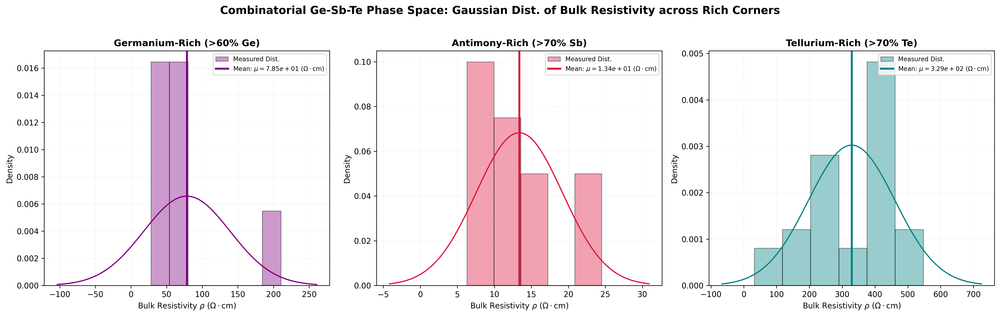

In [364]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# ==============================================================================
# TROUBLESHOOTING & PLOTTING BLOCK
# ==============================================================================

# Define compositional corners and plotting properties
# Ensure data is filtered before assignment to avoid chained assignment warnings
# It is assumed 'gst_scan_book_merged' is already calculated with 'rho_Ohm_cm'
ge_rich_subset = gst_scan_book_merged[gst_scan_book_merged['Ge_at'] > 60.0].copy()
sb_rich_subset = gst_scan_book_merged[gst_scan_book_merged['Sb_at'] > 70.0].copy()
te_rich_subset = gst_scan_book_merged[gst_scan_book_merged['Te_at'] > 70.0].copy()

corners_analysis = [
    ('Germanium-Rich (>60% Ge)', ge_rich_subset, 'purple'),
    ('Antimony-Rich (>70% Sb)', sb_rich_subset, 'crimson'),
    ('Tellurium-Rich (>70% Te)', te_rich_subset, 'teal'),
]

# Initialize the 3-subplot figure (1x3 format)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=300)

for idx, (title, subset, color) in enumerate(corners_analysis):
  ax = axes[idx]

  # a. Extract and transform target data: bulk resistivity
  # Filter out non-positive resistivity values
  # Use .loc to avoid SettingWithCopyWarning and ensure only positive rho values are used
  valid_rho = subset.loc[subset['rho_Ohm_cm'] > 0, 'rho_Ohm_cm']

  # Specific outlier removal for Te-Rich corner
  if title == 'Tellurium-Rich (>70% Te)':
    valid_rho = valid_rho[valid_rho <= 10000] # Filter out values > 10000

  rho_vals = valid_rho # Use raw resistivity values

  if len(rho_vals) < 3: # Handle sparse data corners
      ax.text(0.5, 0.5, "Insufficient Data", ha='center', va='center')
      ax.set_title(title, fontsize=12, fontweight='bold')
      continue

  # b. Standard Data Standardization (Gaussian Parameters Calculation)
  mean_rho = rho_vals.mean()
  std_rho = rho_vals.std()

  # c. Plot Histogram (Density distribution)
  # Check for NaNs/Infs which might cause issues during histogram calculation
  clean_rho = rho_vals.replace([np.inf, -np.inf], np.nan).dropna()

  if len(clean_rho) > 0:
      ax.hist(
          clean_rho,
          bins='auto', # Use 'auto' for dynamic binning with raw values
          density=True,
          alpha=0.4,
          color=color,
          edgecolor='black',
          label='Measured Dist.',
      )

      # d. Add Vertical reference line for the mean
      # Ensure raw string literal (r'') is used for LaTeX rendering to avoid escape errors
      ax.axvline(
          mean_rho,
          color=color,
          linestyle='-',
          linewidth=2.5,
          label=rf'Mean: $\mu={mean_rho:.2e}$ ($\Omega\cdot\mathrm{{cm}}$)', # Update label
      )

      # e. Generate and Plot the Bellcurve (Normal PDF fit)
      # Create a continuous range spanning \u00b13 standard deviations
      x_range = np.linspace(mean_rho - 3 * std_rho, mean_rho + 3 * std_rho, 200)
      bellcurve_y = stats.norm.pdf(x_range, mean_rho, std_rho)

      ax.plot(x_range, bellcurve_y, color=color, linestyle='-', linewidth=1.5)

  # f. Formatting Subplot Canvas
  ax.set_title(title, fontsize=12, fontweight='bold')
  # Correctly formatted raw string literal with proper LaTeX syntax for label rendering
  ax.set_xlabel(r'Bulk Resistivity $\rho$ ($\Omega\cdot\mathrm{{cm}}$)', fontsize=10) # Update label
  ax.set_ylabel('Density', fontsize=10)
  ax.legend(fontsize=8.0, frameon=True, loc='upper right')
  ax.grid(True, linestyle=':', alpha=0.3)

# 3. Final Canvas Formatting and Output
plt.suptitle(
    'Combinatorial Ge-Sb-Te Phase Space: Gaussian Dist. of Bulk Resistivity'
    ' across Rich Corners',
    fontsize=14,
    fontweight='bold',
    y=1.02,
)
plt.tight_layout()
plt.show()

## GST Resistivity 200deg

In [365]:
gst_scan = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_full_scan_200c_3.csv')
fill_ohm = gst_scan['Delta_mV'] / (gst_scan['A2_mV'] / 1000)
gst_scan['R_Ohms'] = gst_scan['R_Ohms'].fillna(fill_ohm)
gst_scan['Rs_Ohm_sq'] = gst_scan['Rs_Ohm_sq'].fillna(gst_scan['R_Ohms'] * math.pi/math.log(2))

In [366]:
gst_scan.head(5)

,Node_ID,Row,Col,X_mm,Y_mm,Delta_mV,A2_mV,R_Ohms,Rs_Ohm_sq,Rs_MOhm_sq
0,1,1,1,-162,-110,440.5625,1.3875,317522.522523,1.439126e+06,NaN
1,2,1,2,-156,-110,989.5075,86.0838,11494.700513,5.209812e+04,NaN
2,3,1,3,-150,-110,1294.6500,21.7962,59397.968453,2.692130e+05,NaN
3,4,1,4,-144,-110,1007.6975,515.3287,1955.446107,8.862786e+03,NaN
4,5,1,5,-138,-110,169.9125,767.6588,221.338569,1.003186e+03,NaN


###Scan Map

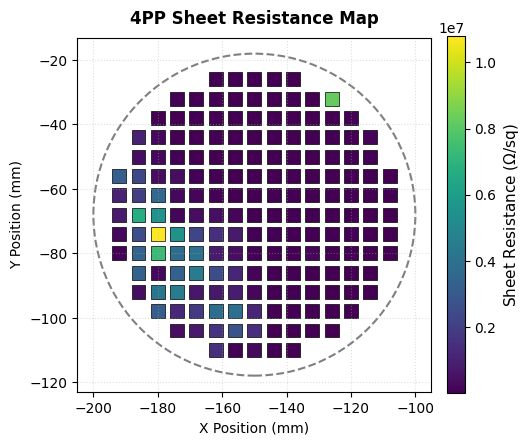

In [367]:
# 1. Create a separate DataFrame for book coordinates from your original gst_scan
gst_scan_book = gst_scan.copy()
gst_scan_book['Row_Book'] = 16 - gst_scan_book['Row']

# 2. Notebook Plotting Code in Book Coordinates
wafer_radius = 50  # mm
center_x, center_y = -150, -68

plt.figure(figsize=(5, 5))

sc = plt.scatter(
    gst_scan_book['X_mm'],
    gst_scan_book['Y_mm'],
    c=gst_scan_book['Rs_Ohm_sq'],
    cmap='viridis',
    marker='s',  # Square markers
    s=100,  # Marker size (points^2)
    edgecolors='black',  # Border around each cell
    linewidth=0.5,
)

# Add wafer circular outline with new center
wafer_outline = plt.Circle(
    (center_x, center_y),
    wafer_radius,
    color='gray',
    fill=False,
    linestyle='--',
    linewidth=1.5,
)
plt.gca().add_patch(wafer_outline)

# Enforce strictly square aspect ratio and set bounds
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
plt.gca().set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

# Labels and colorbar
cbar = plt.colorbar(sc, ax=plt.gca(), fraction=0.046, pad=0.04)
cbar.set_label(r'Sheet Resistance ($\Omega$/sq)', fontsize=11)

plt.gca().set_title(
    '4PP Sheet Resistance Map',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
plt.gca().set_xlabel('X Position (mm)', fontsize=10)
plt.gca().set_ylabel('Y Position (mm)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.4)

plt.show()

###Data Merging Scan and Composition to get Bulk Resistivity

Merge the raw gst scan data and the composition data

In [368]:
# Get XRF composition data
df_xrf = gst_composition.iloc[:177].copy()

# Reconstruct top-down book indexing for XRF
counts_top_to_bottom = [5, 9, 11, 13, 13, 15, 15, 15, 15, 15, 13, 13, 11, 9, 5]
xrf_mapped = []
pt_idx = 0
for r_top_idx, count in enumerate(counts_top_to_bottom):
  row_book_num = r_top_idx + 1
  for col_num in range(1, count + 1):
    row_dict = df_xrf.iloc[pt_idx].to_dict()
    row_dict['Row_Book'] = row_book_num
    row_dict['Col'] = col_num
    xrf_mapped.append(row_dict)
    pt_idx += 1

df_xrf_book = pd.DataFrame(xrf_mapped)

# 3. Merge directly into your existing gst_scan_book DataFrame
gst_scan_book_merged = pd.merge(
    gst_scan_book, df_xrf_book, on=['Row_Book', 'Col']
)

Map Thickness

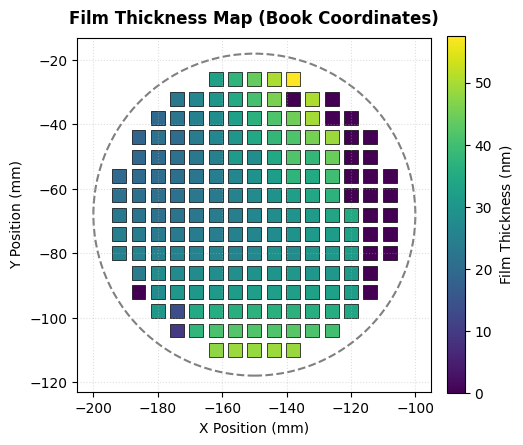

In [369]:
wafer_radius = 50  # mm
center_x, center_y = -150, -68

plt.figure(figsize=(5, 5))

sc = plt.scatter(
    gst_scan_book_merged['X_mm'],
    gst_scan_book_merged['Y_mm'],
    c=gst_scan_book_merged['Thickness (nm)'],
    cmap='viridis',
    marker='s',  # Square markers
    s=100,  # Marker size (points^2)
    edgecolors='black',  # Border around each cell
    linewidth=0.5,
)

# Add wafer circular outline with new center
wafer_outline = plt.Circle(
    (center_x, center_y),
    wafer_radius,
    color='gray',
    fill=False,
    linestyle='--',
    linewidth=1.5,
)
plt.gca().add_patch(wafer_outline)

# Enforce strictly square aspect ratio and set bounds
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
plt.gca().set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

# Labels and colorbar
cbar = plt.colorbar(sc, ax=plt.gca(), fraction=0.046, pad=0.04)
cbar.set_label(r'Film Thickness ($\mathrm{nm}$)', fontsize=10)

plt.gca().set_title(
    'Film Thickness Map (Book Coordinates)',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
plt.gca().set_xlabel('X Position (mm)', fontsize=10)
plt.gca().set_ylabel('Y Position (mm)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.4)

plt.show()

Get Bulk Resistivity

In [370]:
# Calculate bulk resistivity (rho = Rs * thickness)
# Thickness is in nm -> convert to cm by multiplying by 1e-7

gst_scan_book_merged['rho_Ohm_cm'] = gst_scan_book_merged[
    'Rs_Ohm_sq'
] * (gst_scan_book_merged['Thickness (nm)'] * 1e-7)

print(
    'Successfully calculated bulk resistivity for'
    f' {len(gst_scan_book_merged)} nodes!'
)

Successfully calculated bulk resistivity for 177 nodes!


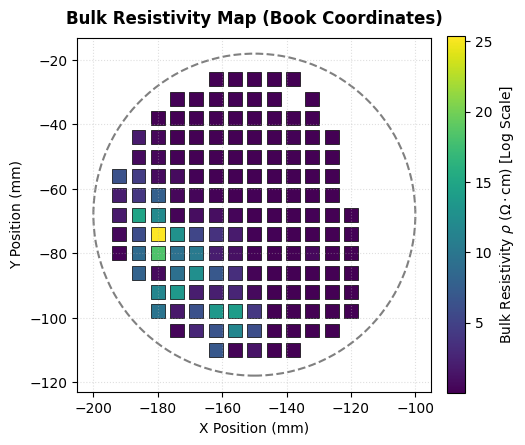

In [371]:
# Filter out non-positive values for log scaling
valid_rho = gst_scan_book_merged[gst_scan_book_merged['rho_Ohm_cm'] > 0].copy()

# 3. Plotting bulk resistivity spatial map
wafer_radius = 50  # mm
center_x, center_y = -150, -68

plt.figure(figsize=(5, 5))

sc = plt.scatter(
    valid_rho['X_mm'],
    valid_rho['Y_mm'],
    c=valid_rho['rho_Ohm_cm'],
    cmap='viridis',
    # norm=plt.matplotlib.colors.LogNorm(
    #     vmin=max(1.0, valid_rho['rho_Ohm_cm'].min()),
    #     vmax=valid_rho['rho_Ohm_cm'].max(),
    # ),
    marker='s',
    s=100,
    edgecolors='black',
    linewidth=0.5,
)

wafer_outline = plt.Circle(
    (center_x, center_y),
    wafer_radius,
    color='gray',
    fill=False,
    linestyle='--',
    linewidth=1.5,
)
plt.gca().add_patch(wafer_outline)

plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
plt.gca().set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

cbar = plt.colorbar(sc, ax=plt.gca(), fraction=0.046, pad=0.04)
cbar.set_label(
    r'Bulk Resistivity $\rho$ ($\Omega \cdot \mathrm{cm}$) [Log Scale]',
    fontsize=10,
)

plt.gca().set_title(
    'Bulk Resistivity Map (Book Coordinates)',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
plt.gca().set_xlabel('X Position (mm)', fontsize=10)
plt.gca().set_ylabel('Y Position (mm)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.4)

plt.show()

### Composition Map

Plot the composition data

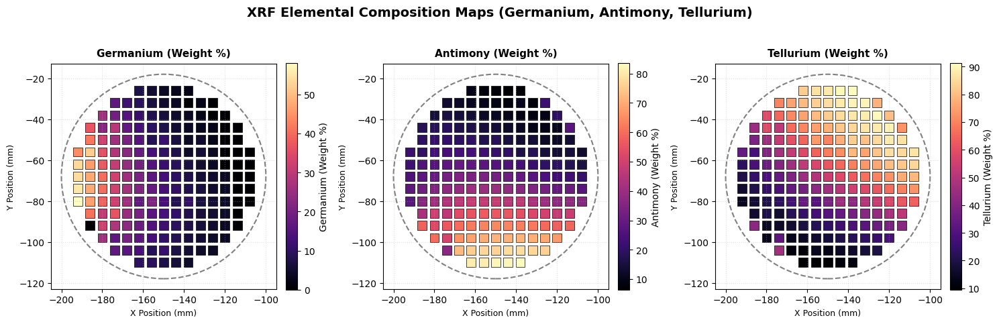

In [372]:
# 3-Subplot Figure Setup (Ge, Sb, Te)
wafer_radius = 50  # mm
center_x, center_y = -150, -68

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

compositions = [
    ('Ge (Weight %)', 'Germanium (Weight %)', 'plasma'),
    ('Sb (Weight %)', 'Antimony (Weight %)', 'coolwarm'),
    ('Te (Weight %)', 'Tellurium (Weight %)', 'cividis'),
]

for idx, (col_name, label, cmap) in enumerate(compositions):
  ax = axes[idx]

  sc = ax.scatter(
      gst_scan_book_merged['X_mm'],
      gst_scan_book_merged['Y_mm'],
      c=gst_scan_book_merged[col_name],
      cmap='magma',
      marker='s',  # Square markers
      s=100,  # Marker size (points^2)
      edgecolors='black',  # Border around each cell
      linewidth=0.5,
  )

  # Add wafer circular outline with new center
  wafer_outline = plt.Circle(
      (center_x, center_y),
      wafer_radius,
      color='gray',
      fill=False,
      linestyle='--',
      linewidth=1.5,
  )
  ax.add_patch(wafer_outline)

  # Enforce strictly square aspect ratio and set bounds
  ax.set_aspect('equal', adjustable='box')
  ax.set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
  ax.set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

  # Labels and colorbar
  cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
  cbar.set_label(label, fontsize=10)

  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_xlabel('X Position (mm)', fontsize=9)
  ax.set_ylabel('Y Position (mm)', fontsize=9)
  ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle(
    'XRF Elemental Composition Maps (Germanium, Antimony, Tellurium)',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

###Ternary Space Mapping

In [373]:
# 1. Convert weight percent to atomic percent
M_Ge, M_Sb, M_Te = 72.64, 121.76, 127.60
gst_scan_book_merged['Ge_mol'] = (
    gst_scan_book_merged['Ge (Weight %)'] / M_Ge
)
gst_scan_book_merged['Sb_mol'] = (
    gst_scan_book_merged['Sb (Weight %)'] / M_Sb
)
gst_scan_book_merged['Te_mol'] = (
    gst_scan_book_merged['Te (Weight %)'] / M_Te
)
tot_mol = (
    gst_scan_book_merged['Ge_mol']
    + gst_scan_book_merged['Sb_mol']
    + gst_scan_book_merged['Te_mol']
)

gst_scan_book_merged['Ge_at'] = (
    gst_scan_book_merged['Ge_mol'] / tot_mol
) * 100.0
gst_scan_book_merged['Sb_at'] = (
    gst_scan_book_merged['Sb_mol'] / tot_mol
) * 100.0
gst_scan_book_merged['Te_at'] = (
    gst_scan_book_merged['Te_mol'] / tot_mol
) * 100.0

# 2. Compute ternary Cartesian coordinates
ge_frac = gst_scan_book_merged['Ge_at'] / 100.0
te_frac = gst_scan_book_merged['Te_at'] / 100.0

gst_scan_book_merged['ternary_x_at'] = te_frac + 0.5 * ge_frac
gst_scan_book_merged['ternary_y_at'] = ge_frac * (np.sqrt(3) / 2.0)

print('Ternary coordinates successfully added to gst_scan_book_merged!')

Ternary coordinates successfully added to gst_scan_book_merged!


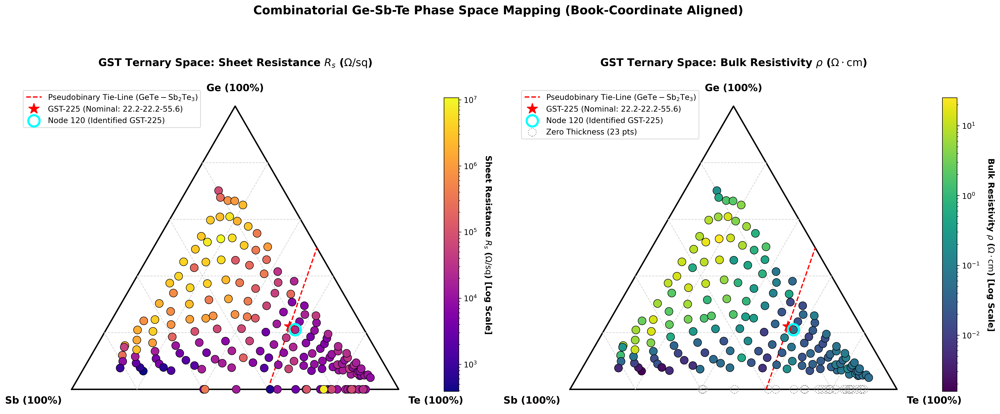

In [374]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np

# 1. Ensure gst_scan_book_merged is fully prepared with atomic percentages and rho
# (gst_scan_book merged with df_xrf_book on ['Row_Book', 'Col'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9.5), dpi=300)
sqrt3_2 = np.sqrt(3) / 2.0


def setup_gst_ternary(ax, title):
  ax.plot([0, 1, 0.5, 0], [0, 0, sqrt3_2, 0], "k-", lw=2.0)

  for p in [0.2, 0.4, 0.6, 0.8]:
    ax.plot(
        [0.5 * p, 1 - 0.5 * p],
        [sqrt3_2 * p, sqrt3_2 * p],
        color="lightgray",
        linestyle="--",
        lw=0.9,
    )
    ax.plot(
        [p, 0.5 * p + 0.5],
        [0, sqrt3_2 * (1 - p)],
        color="lightgray",
        linestyle="--",
        lw=0.9,
    )
    ax.plot(
        [1 - p, 0.5 * (1 - p)],
        [0, sqrt3_2 * (1 - p)],
        color="lightgray",
        linestyle="--",
        lw=0.9,
    )

  ax.text(
      0.5,
      sqrt3_2 + 0.04,
      "Ge (100%)",
      ha="center",
      va="bottom",
      fontsize=14,
      fontweight="bold",
  )
  ax.text(
      -0.03,
      -0.02,
      "Sb (100%)",
      ha="right",
      va="top",
      fontsize=14,
      fontweight="bold",
  )
  ax.text(
      1.03,
      -0.02,
      "Te (100%)",
      ha="left",
      va="top",
      fontsize=14,
      fontweight="bold",
  )

  # Pseudobinary tie-line (GeTe - Sb2Te3)
  ax.plot(
      [0.60, 0.75],
      [0, sqrt3_2 * 0.5],
      "r--",
      lw=1.8,
      label=r"Pseudobinary Tie-Line ($\mathrm{GeTe - Sb_2Te_3}$)",
  )

  # Nominal GST-225 Star marker
  gx = 5 / 9 + 0.5 * (2 / 9)
  gy = sqrt3_2 * (2 / 9)
  ax.plot(
      gx,
      gy,
      "r*",
      markersize=16,
      zorder=10,
      label="GST-225 (Nominal: 22.2-22.2-55.6)",
  )

  # Highlight Node 120
  node120 = gst_scan_book_merged[gst_scan_book_merged["Node_ID"] == 120].iloc[0]
  ax.scatter(
      node120["ternary_x_at"],
      node120["ternary_y_at"],
      s=260,
      facecolors="none",
      edgecolors="cyan",
      linewidths=3.0,
      zorder=11,
      label="Node 120 (Identified GST-225)",
  )

  ax.set_title(title, fontsize=15, fontweight="bold", pad=20)
  ax.legend(
      loc="upper left",
      bbox_to_anchor=(-0.05, 0.98),
      fontsize=11,
      frameon=True,
  )
  ax.set_xlim(-0.10, 1.10)
  ax.set_ylim(-0.06, sqrt3_2 + 0.08)
  ax.set_aspect("equal")
  ax.axis("off")


# Left Ternary: Sheet Resistance Rs (Unlocked dynamic LogNorm)
setup_gst_ternary(
    ax1, r"GST Ternary Space: Sheet Resistance $R_s$ ($\Omega/\mathrm{sq}$)"
)
sc1 = ax1.scatter(
    gst_scan_book_merged["ternary_x_at"],
    gst_scan_book_merged["ternary_y_at"],
    c=gst_scan_book_merged["Rs_Ohm_sq"],
    cmap="plasma",
    norm=mcolors.LogNorm(),  # Unlocked to scale automatically with smaller data points
    s=130,
    edgecolors="black",
    linewidths=0.7,
    zorder=5,
)
cbar1 = fig.colorbar(sc1, ax=ax1, fraction=0.035, pad=0.03)
cbar1.set_label(
    r"Sheet Resistance $R_s$ ($\Omega/\mathrm{sq}$) [Log Scale]",
    rotation=270,
    labelpad=22,
    fontsize=12,
    fontweight="bold",
)
cbar1.ax.tick_params(labelsize=11)

# Right Ternary: Bulk Resistivity rho (Unlocked dynamic LogNorm)
valid_rho = gst_scan_book_merged[gst_scan_book_merged["rho_Ohm_cm"] > 0].copy()
zero_rho = gst_scan_book_merged[gst_scan_book_merged["rho_Ohm_cm"] <= 0].copy()

setup_gst_ternary(
    ax2, r"GST Ternary Space: Bulk Resistivity $\rho$ ($\Omega\cdot\mathrm{cm}$)"
)
sc2 = ax2.scatter(
    valid_rho["ternary_x_at"],
    valid_rho["ternary_y_at"],
    c=valid_rho["rho_Ohm_cm"],
    cmap="viridis",
    norm=mcolors.LogNorm(),  # Unlocked to scale automatically with smaller data points
    s=130,
    edgecolors="black",
    linewidths=0.7,
    zorder=5,
)

if len(zero_rho) > 0:
  ax2.scatter(
      zero_rho["ternary_x_at"],
      zero_rho["ternary_y_at"],
      s=130,
      facecolors="none",
      edgecolors="gray",
      linewidths=1.0,
      linestyle=":",
      zorder=4,
      label=f"Zero Thickness ({len(zero_rho)} pts)",
  )
  ax2.legend(
      loc="upper left",
      bbox_to_anchor=(-0.05, 0.98),
      fontsize=11,
      frameon=True,
  )

cbar2 = fig.colorbar(sc2, ax=ax2, fraction=0.035, pad=0.03)
cbar2.set_label(
    r"Bulk Resistivity $\rho$ ($\Omega\cdot\mathrm{cm}$) [Log Scale]",
    rotation=270,
    labelpad=22,
    fontsize=12,
    fontweight="bold",
)
cbar2.ax.tick_params(labelsize=11)

plt.suptitle(
    "Combinatorial Ge-Sb-Te Phase Space Mapping (Book-Coordinate Aligned)",
    fontsize=17,
    fontweight="bold",
    y=0.98,
)
plt.tight_layout()
plt.show()

In [375]:
# Node 120's bulk resistivity
node120 = gst_scan_book_merged[gst_scan_book_merged['Node_ID'] == 120].iloc[0]
print(f"Node 120 Bulk Resistivity: {node120['rho_Ohm_cm']:.4f} Ohm·cm")

Node 120 Bulk Resistivity: 0.0548 Ohm·cm


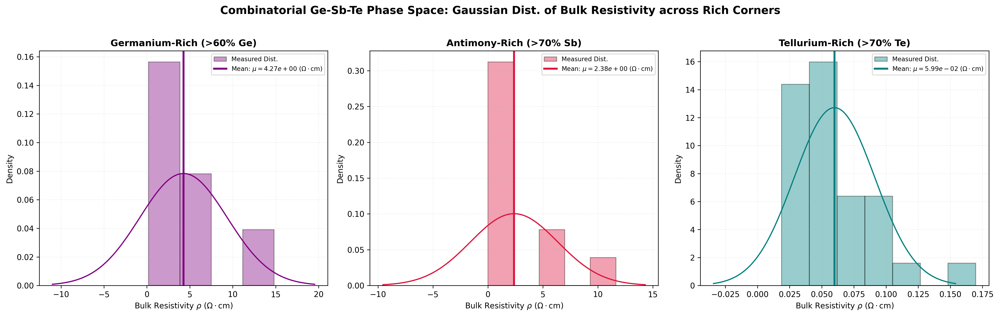

In [376]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# ==============================================================================
# TROUBLESHOOTING & PLOTTING BLOCK
# ==============================================================================

# Define compositional corners and plotting properties
# Ensure data is filtered before assignment to avoid chained assignment warnings
# It is assumed 'gst_scan_book_merged' is already calculated with 'rho_Ohm_cm'
ge_rich_subset = gst_scan_book_merged[gst_scan_book_merged['Ge_at'] > 60.0].copy()
sb_rich_subset = gst_scan_book_merged[gst_scan_book_merged['Sb_at'] > 70.0].copy()
te_rich_subset = gst_scan_book_merged[gst_scan_book_merged['Te_at'] > 70.0].copy()

corners_analysis = [
    ('Germanium-Rich (>60% Ge)', ge_rich_subset, 'purple'),
    ('Antimony-Rich (>70% Sb)', sb_rich_subset, 'crimson'),
    ('Tellurium-Rich (>70% Te)', te_rich_subset, 'teal'),
]

# Initialize the 3-subplot figure (1x3 format)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=300)

for idx, (title, subset, color) in enumerate(corners_analysis):
  ax = axes[idx]

  # a. Extract and transform target data: bulk resistivity
  # Filter out non-positive resistivity values
  # Use .loc to avoid SettingWithCopyWarning and ensure only positive rho values are used
  valid_rho = subset.loc[subset['rho_Ohm_cm'] > 0, 'rho_Ohm_cm']

  # Specific outlier removal for Te-Rich corner
  if title == 'Tellurium-Rich (>70% Te)':
    valid_rho = valid_rho[valid_rho <= 10000] # Filter out values > 10000

  rho_vals = valid_rho # Use raw resistivity values

  if len(rho_vals) < 3: # Handle sparse data corners
      ax.text(0.5, 0.5, "Insufficient Data", ha='center', va='center')
      ax.set_title(title, fontsize=12, fontweight='bold')
      continue

  # b. Standard Data Standardization (Gaussian Parameters Calculation)
  mean_rho = rho_vals.mean()
  std_rho = rho_vals.std()

  # c. Plot Histogram (Density distribution)
  # Check for NaNs/Infs which might cause issues during histogram calculation
  clean_rho = rho_vals.replace([np.inf, -np.inf], np.nan).dropna()

  if len(clean_rho) > 0:
      ax.hist(
          clean_rho,
          bins='auto', # Use 'auto' for dynamic binning with raw values
          density=True,
          alpha=0.4,
          color=color,
          edgecolor='black',
          label='Measured Dist.',
      )

      # d. Add Vertical reference line for the mean
      # Ensure raw string literal (r'') is used for LaTeX rendering to avoid escape errors
      ax.axvline(
          mean_rho,
          color=color,
          linestyle='-',
          linewidth=2.5,
          label=rf'Mean: $\mu={mean_rho:.2e}$ ($\Omega\cdot\mathrm{{cm}}$)', # Update label
      )

      # e. Generate and Plot the Bellcurve (Normal PDF fit)
      # Create a continuous range spanning \u00b13 standard deviations
      x_range = np.linspace(mean_rho - 3 * std_rho, mean_rho + 3 * std_rho, 200)
      bellcurve_y = stats.norm.pdf(x_range, mean_rho, std_rho)

      ax.plot(x_range, bellcurve_y, color=color, linestyle='-', linewidth=1.5)

  # f. Formatting Subplot Canvas
  ax.set_title(title, fontsize=12, fontweight='bold')
  # Correctly formatted raw string literal with proper LaTeX syntax for label rendering
  ax.set_xlabel(r'Bulk Resistivity $\rho$ ($\Omega\cdot\mathrm{{cm}}$)', fontsize=10) # Update label
  ax.set_ylabel('Density', fontsize=10)
  ax.legend(fontsize=8.0, frameon=True, loc='upper right')
  ax.grid(True, linestyle=':', alpha=0.3)

# 3. Final Canvas Formatting and Output
plt.suptitle(
    'Combinatorial Ge-Sb-Te Phase Space: Gaussian Dist. of Bulk Resistivity'
    ' across Rich Corners',
    fontsize=14,
    fontweight='bold',
    y=1.02,
)
plt.tight_layout()
plt.show()

## GST Resistivity 300deg

In [377]:
gst_scan = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/100mm_wafer_177sq_full_scan_300c_3.csv')
fill_ohm = gst_scan['Delta_mV'] / (gst_scan['A2_mV'] / 1000)
gst_scan['R_Ohms'] = gst_scan['R_Ohms'].fillna(fill_ohm)
gst_scan['Rs_Ohm_sq'] = gst_scan['Rs_Ohm_sq'].fillna(gst_scan['R_Ohms'] * math.pi/math.log(2))

In [378]:
gst_scan.head(5)

,Node_ID,Row,Col,X_mm,Y_mm,Delta_mV,A2_mV,R_Ohms,Rs_Ohm_sq,Rs_MOhm_sq
0,1,1,1,-162,-110,69.4225,753.2562,92.163198,417.716803,NaN
1,2,1,2,-156,-110,46.4475,731.0237,63.537612,287.975339,NaN
2,3,1,3,-150,-110,23.9400,771.4275,31.033376,140.654438,NaN
3,4,1,4,-144,-110,12.4375,795.4512,15.635780,70.866986,NaN
4,5,1,5,-138,-110,6.8125,756.2400,9.008384,40.829239,NaN


###Scan Map

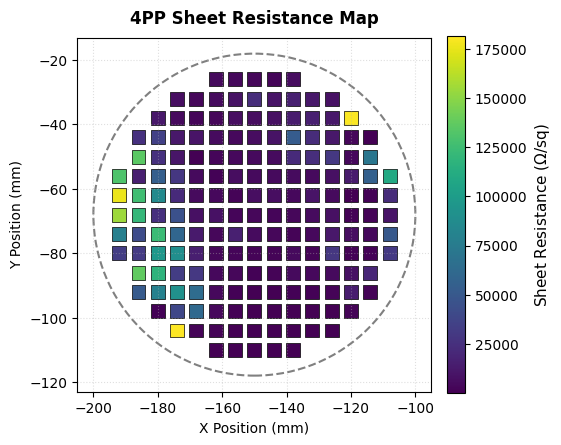

In [379]:
# 1. Create a separate DataFrame for book coordinates from your original gst_scan
gst_scan_book = gst_scan.copy()
gst_scan_book['Row_Book'] = 16 - gst_scan_book['Row']

# 2. Notebook Plotting Code in Book Coordinates
wafer_radius = 50  # mm
center_x, center_y = -150, -68

plt.figure(figsize=(5, 5))

sc = plt.scatter(
    gst_scan_book['X_mm'],
    gst_scan_book['Y_mm'],
    c=gst_scan_book['Rs_Ohm_sq'],
    cmap='viridis',
    marker='s',  # Square markers
    s=100,  # Marker size (points^2)
    edgecolors='black',  # Border around each cell
    linewidth=0.5,
)

# Add wafer circular outline with new center
wafer_outline = plt.Circle(
    (center_x, center_y),
    wafer_radius,
    color='gray',
    fill=False,
    linestyle='--',
    linewidth=1.5,
)
plt.gca().add_patch(wafer_outline)

# Enforce strictly square aspect ratio and set bounds
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
plt.gca().set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

# Labels and colorbar
cbar = plt.colorbar(sc, ax=plt.gca(), fraction=0.046, pad=0.04)
cbar.set_label(r'Sheet Resistance ($\Omega$/sq)', fontsize=11)

plt.gca().set_title(
    '4PP Sheet Resistance Map',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
plt.gca().set_xlabel('X Position (mm)', fontsize=10)
plt.gca().set_ylabel('Y Position (mm)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.4)

plt.show()

###Data Merging Scan and Composition to get Bulk Resistivity

Merge the raw gst scan data and the composition data

In [380]:
# Get XRF composition data
df_xrf = gst_composition.iloc[:177].copy()

# Reconstruct top-down book indexing for XRF
counts_top_to_bottom = [5, 9, 11, 13, 13, 15, 15, 15, 15, 15, 13, 13, 11, 9, 5]
xrf_mapped = []
pt_idx = 0
for r_top_idx, count in enumerate(counts_top_to_bottom):
  row_book_num = r_top_idx + 1
  for col_num in range(1, count + 1):
    row_dict = df_xrf.iloc[pt_idx].to_dict()
    row_dict['Row_Book'] = row_book_num
    row_dict['Col'] = col_num
    xrf_mapped.append(row_dict)
    pt_idx += 1

df_xrf_book = pd.DataFrame(xrf_mapped)

# 3. Merge directly into your existing gst_scan_book DataFrame
gst_scan_book_merged = pd.merge(
    gst_scan_book, df_xrf_book, on=['Row_Book', 'Col']
)

Map Thickness

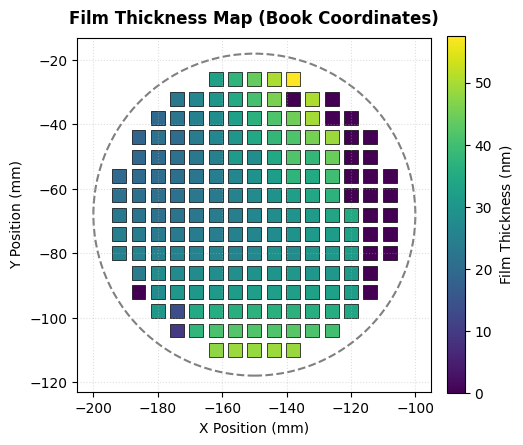

In [381]:
wafer_radius = 50  # mm
center_x, center_y = -150, -68

plt.figure(figsize=(5, 5))

sc = plt.scatter(
    gst_scan_book_merged['X_mm'],
    gst_scan_book_merged['Y_mm'],
    c=gst_scan_book_merged['Thickness (nm)'],
    cmap='viridis',
    marker='s',  # Square markers
    s=100,  # Marker size (points^2)
    edgecolors='black',  # Border around each cell
    linewidth=0.5,
)

# Add wafer circular outline with new center
wafer_outline = plt.Circle(
    (center_x, center_y),
    wafer_radius,
    color='gray',
    fill=False,
    linestyle='--',
    linewidth=1.5,
)
plt.gca().add_patch(wafer_outline)

# Enforce strictly square aspect ratio and set bounds
plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
plt.gca().set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

# Labels and colorbar
cbar = plt.colorbar(sc, ax=plt.gca(), fraction=0.046, pad=0.04)
cbar.set_label(r'Film Thickness ($\mathrm{nm}$)', fontsize=10)

plt.gca().set_title(
    'Film Thickness Map (Book Coordinates)',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
plt.gca().set_xlabel('X Position (mm)', fontsize=10)
plt.gca().set_ylabel('Y Position (mm)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.4)

plt.show()

Get Bulk Resistivity

In [382]:
# Calculate bulk resistivity (rho = Rs * thickness)
# Thickness is in nm -> convert to cm by multiplying by 1e-7

gst_scan_book_merged['rho_Ohm_cm'] = gst_scan_book_merged[
    'Rs_Ohm_sq'
] * (gst_scan_book_merged['Thickness (nm)'] * 1e-7)

print(
    'Successfully calculated bulk resistivity for'
    f' {len(gst_scan_book_merged)} nodes!'
)

Successfully calculated bulk resistivity for 177 nodes!


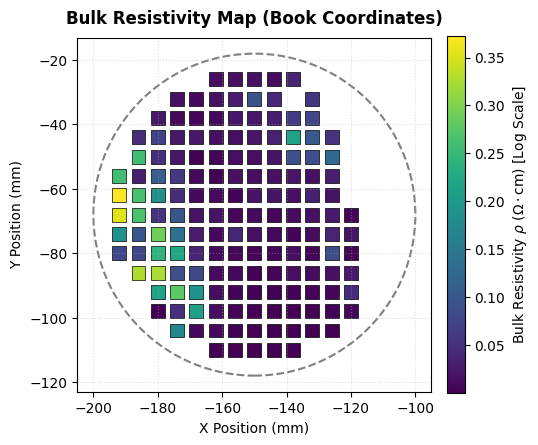

In [383]:
# Filter out non-positive values for log scaling
valid_rho = gst_scan_book_merged[gst_scan_book_merged['rho_Ohm_cm'] > 0].copy()

# 3. Plotting bulk resistivity spatial map
wafer_radius = 50  # mm
center_x, center_y = -150, -68

plt.figure(figsize=(5, 5))

sc = plt.scatter(
    valid_rho['X_mm'],
    valid_rho['Y_mm'],
    c=valid_rho['rho_Ohm_cm'],
    cmap='viridis',
    # norm=plt.matplotlib.colors.LogNorm(
    #     vmin=max(1.0, valid_rho['rho_Ohm_cm'].min()),
    #     vmax=valid_rho['rho_Ohm_cm'].max(),
    # ),
    marker='s',
    s=100,
    edgecolors='black',
    linewidth=0.5,
)

wafer_outline = plt.Circle(
    (center_x, center_y),
    wafer_radius,
    color='gray',
    fill=False,
    linestyle='--',
    linewidth=1.5,
)
plt.gca().add_patch(wafer_outline)

plt.gca().set_aspect('equal', adjustable='box')
plt.gca().set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
plt.gca().set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

cbar = plt.colorbar(sc, ax=plt.gca(), fraction=0.046, pad=0.04)
cbar.set_label(
    r'Bulk Resistivity $\rho$ ($\Omega \cdot \mathrm{cm}$) [Log Scale]',
    fontsize=10,
)

plt.gca().set_title(
    'Bulk Resistivity Map (Book Coordinates)',
    fontsize=12,
    fontweight='bold',
    pad=10,
)
plt.gca().set_xlabel('X Position (mm)', fontsize=10)
plt.gca().set_ylabel('Y Position (mm)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.4)

plt.show()

### Composition Map

Plot the composition data

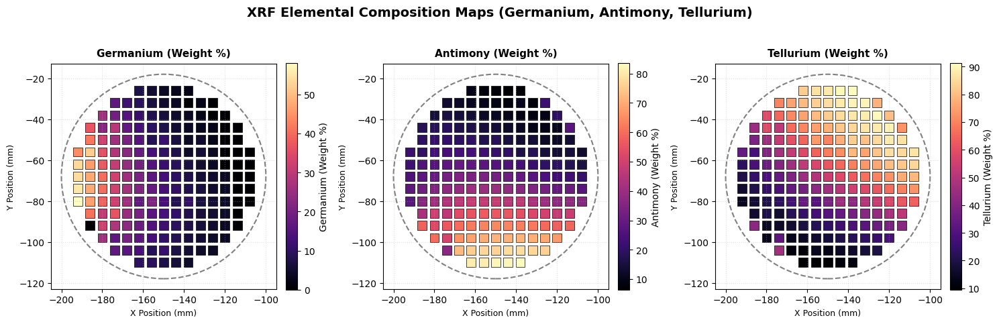

In [384]:
# 3-Subplot Figure Setup (Ge, Sb, Te)
wafer_radius = 50  # mm
center_x, center_y = -150, -68

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

compositions = [
    ('Ge (Weight %)', 'Germanium (Weight %)', 'plasma'),
    ('Sb (Weight %)', 'Antimony (Weight %)', 'coolwarm'),
    ('Te (Weight %)', 'Tellurium (Weight %)', 'cividis'),
]

for idx, (col_name, label, cmap) in enumerate(compositions):
  ax = axes[idx]

  sc = ax.scatter(
      gst_scan_book_merged['X_mm'],
      gst_scan_book_merged['Y_mm'],
      c=gst_scan_book_merged[col_name],
      cmap='magma',
      marker='s',  # Square markers
      s=100,  # Marker size (points^2)
      edgecolors='black',  # Border around each cell
      linewidth=0.5,
  )

  # Add wafer circular outline with new center
  wafer_outline = plt.Circle(
      (center_x, center_y),
      wafer_radius,
      color='gray',
      fill=False,
      linestyle='--',
      linewidth=1.5,
  )
  ax.add_patch(wafer_outline)

  # Enforce strictly square aspect ratio and set bounds
  ax.set_aspect('equal', adjustable='box')
  ax.set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
  ax.set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

  # Labels and colorbar
  cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
  cbar.set_label(label, fontsize=10)

  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_xlabel('X Position (mm)', fontsize=9)
  ax.set_ylabel('Y Position (mm)', fontsize=9)
  ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle(
    'XRF Elemental Composition Maps (Germanium, Antimony, Tellurium)',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

###Ternary Space Mapping

In [385]:
# 1. Convert weight percent to atomic percent
M_Ge, M_Sb, M_Te = 72.64, 121.76, 127.60
gst_scan_book_merged['Ge_mol'] = (
    gst_scan_book_merged['Ge (Weight %)'] / M_Ge
)
gst_scan_book_merged['Sb_mol'] = (
    gst_scan_book_merged['Sb (Weight %)'] / M_Sb
)
gst_scan_book_merged['Te_mol'] = (
    gst_scan_book_merged['Te (Weight %)'] / M_Te
)
tot_mol = (
    gst_scan_book_merged['Ge_mol']
    + gst_scan_book_merged['Sb_mol']
    + gst_scan_book_merged['Te_mol']
)

gst_scan_book_merged['Ge_at'] = (
    gst_scan_book_merged['Ge_mol'] / tot_mol
) * 100.0
gst_scan_book_merged['Sb_at'] = (
    gst_scan_book_merged['Sb_mol'] / tot_mol
) * 100.0
gst_scan_book_merged['Te_at'] = (
    gst_scan_book_merged['Te_mol'] / tot_mol
) * 100.0

# 2. Compute ternary Cartesian coordinates
ge_frac = gst_scan_book_merged['Ge_at'] / 100.0
te_frac = gst_scan_book_merged['Te_at'] / 100.0

gst_scan_book_merged['ternary_x_at'] = te_frac + 0.5 * ge_frac
gst_scan_book_merged['ternary_y_at'] = ge_frac * (np.sqrt(3) / 2.0)

print('Ternary coordinates successfully added to gst_scan_book_merged!')

Ternary coordinates successfully added to gst_scan_book_merged!


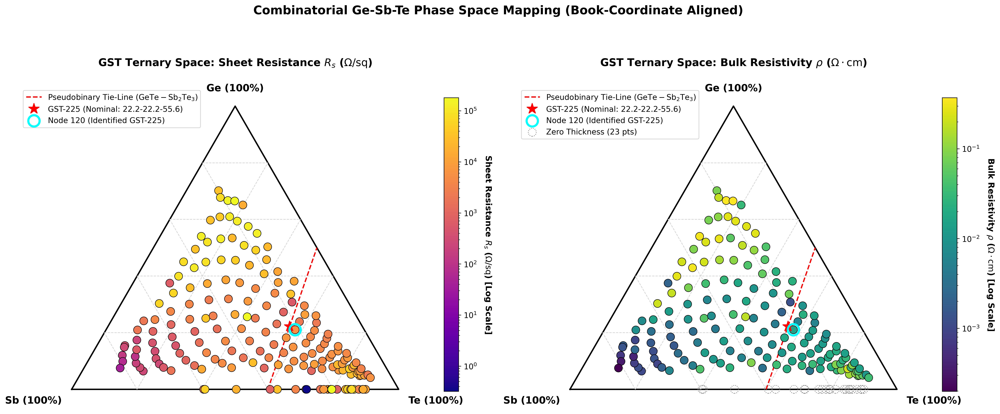

In [386]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np

# 1. Ensure gst_scan_book_merged is fully prepared with atomic percentages and rho
# (gst_scan_book merged with df_xrf_book on ['Row_Book', 'Col'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 9.5), dpi=300)
sqrt3_2 = np.sqrt(3) / 2.0


def setup_gst_ternary(ax, title):
  ax.plot([0, 1, 0.5, 0], [0, 0, sqrt3_2, 0], "k-", lw=2.0)

  for p in [0.2, 0.4, 0.6, 0.8]:
    ax.plot(
        [0.5 * p, 1 - 0.5 * p],
        [sqrt3_2 * p, sqrt3_2 * p],
        color="lightgray",
        linestyle="--",
        lw=0.9,
    )
    ax.plot(
        [p, 0.5 * p + 0.5],
        [0, sqrt3_2 * (1 - p)],
        color="lightgray",
        linestyle="--",
        lw=0.9,
    )
    ax.plot(
        [1 - p, 0.5 * (1 - p)],
        [0, sqrt3_2 * (1 - p)],
        color="lightgray",
        linestyle="--",
        lw=0.9,
    )

  ax.text(
      0.5,
      sqrt3_2 + 0.04,
      "Ge (100%)",
      ha="center",
      va="bottom",
      fontsize=14,
      fontweight="bold",
  )
  ax.text(
      -0.03,
      -0.02,
      "Sb (100%)",
      ha="right",
      va="top",
      fontsize=14,
      fontweight="bold",
  )
  ax.text(
      1.03,
      -0.02,
      "Te (100%)",
      ha="left",
      va="top",
      fontsize=14,
      fontweight="bold",
  )

  # Pseudobinary tie-line (GeTe - Sb2Te3)
  ax.plot(
      [0.60, 0.75],
      [0, sqrt3_2 * 0.5],
      "r--",
      lw=1.8,
      label=r"Pseudobinary Tie-Line ($\mathrm{GeTe - Sb_2Te_3}$)",
  )

  # Nominal GST-225 Star marker
  gx = 5 / 9 + 0.5 * (2 / 9)
  gy = sqrt3_2 * (2 / 9)
  ax.plot(
      gx,
      gy,
      "r*",
      markersize=16,
      zorder=10,
      label="GST-225 (Nominal: 22.2-22.2-55.6)",
  )

  # Highlight Node 120
  node120 = gst_scan_book_merged[gst_scan_book_merged["Node_ID"] == 120].iloc[0]
  ax.scatter(
      node120["ternary_x_at"],
      node120["ternary_y_at"],
      s=260,
      facecolors="none",
      edgecolors="cyan",
      linewidths=3.0,
      zorder=11,
      label="Node 120 (Identified GST-225)",
  )

  ax.set_title(title, fontsize=15, fontweight="bold", pad=20)
  ax.legend(
      loc="upper left",
      bbox_to_anchor=(-0.05, 0.98),
      fontsize=11,
      frameon=True,
  )
  ax.set_xlim(-0.10, 1.10)
  ax.set_ylim(-0.06, sqrt3_2 + 0.08)
  ax.set_aspect("equal")
  ax.axis("off")


# Left Ternary: Sheet Resistance Rs (Unlocked dynamic LogNorm)
setup_gst_ternary(
    ax1, r"GST Ternary Space: Sheet Resistance $R_s$ ($\Omega/\mathrm{sq}$)"
)
sc1 = ax1.scatter(
    gst_scan_book_merged["ternary_x_at"],
    gst_scan_book_merged["ternary_y_at"],
    c=gst_scan_book_merged["Rs_Ohm_sq"],
    cmap="plasma",
    norm=mcolors.LogNorm(),  # Unlocked to scale automatically with smaller data points
    s=130,
    edgecolors="black",
    linewidths=0.7,
    zorder=5,
)
cbar1 = fig.colorbar(sc1, ax=ax1, fraction=0.035, pad=0.03)
cbar1.set_label(
    r"Sheet Resistance $R_s$ ($\Omega/\mathrm{sq}$) [Log Scale]",
    rotation=270,
    labelpad=22,
    fontsize=12,
    fontweight="bold",
)
cbar1.ax.tick_params(labelsize=11)

# Right Ternary: Bulk Resistivity rho (Unlocked dynamic LogNorm)
valid_rho = gst_scan_book_merged[gst_scan_book_merged["rho_Ohm_cm"] > 0].copy()
zero_rho = gst_scan_book_merged[gst_scan_book_merged["rho_Ohm_cm"] <= 0].copy()

setup_gst_ternary(
    ax2, r"GST Ternary Space: Bulk Resistivity $\rho$ ($\Omega\cdot\mathrm{cm}$)"
)
sc2 = ax2.scatter(
    valid_rho["ternary_x_at"],
    valid_rho["ternary_y_at"],
    c=valid_rho["rho_Ohm_cm"],
    cmap="viridis",
    norm=mcolors.LogNorm(),  # Unlocked to scale automatically with smaller data points
    s=130,
    edgecolors="black",
    linewidths=0.7,
    zorder=5,
)

if len(zero_rho) > 0:
  ax2.scatter(
      zero_rho["ternary_x_at"],
      zero_rho["ternary_y_at"],
      s=130,
      facecolors="none",
      edgecolors="gray",
      linewidths=1.0,
      linestyle=":",
      zorder=4,
      label=f"Zero Thickness ({len(zero_rho)} pts)",
  )
  ax2.legend(
      loc="upper left",
      bbox_to_anchor=(-0.05, 0.98),
      fontsize=11,
      frameon=True,
  )

cbar2 = fig.colorbar(sc2, ax=ax2, fraction=0.035, pad=0.03)
cbar2.set_label(
    r"Bulk Resistivity $\rho$ ($\Omega\cdot\mathrm{cm}$) [Log Scale]",
    rotation=270,
    labelpad=22,
    fontsize=12,
    fontweight="bold",
)
cbar2.ax.tick_params(labelsize=11)

plt.suptitle(
    "Combinatorial Ge-Sb-Te Phase Space Mapping (Book-Coordinate Aligned)",
    fontsize=17,
    fontweight="bold",
    y=0.98,
)
plt.tight_layout()
plt.show()

In [387]:
# Node 120's bulk resistivity
node120 = gst_scan_book_merged[gst_scan_book_merged['Node_ID'] == 120].iloc[0]
print(f"Node 120 Bulk Resistivity: {node120['rho_Ohm_cm']:.4f} Ohm·cm")

Node 120 Bulk Resistivity: 0.0154 Ohm·cm


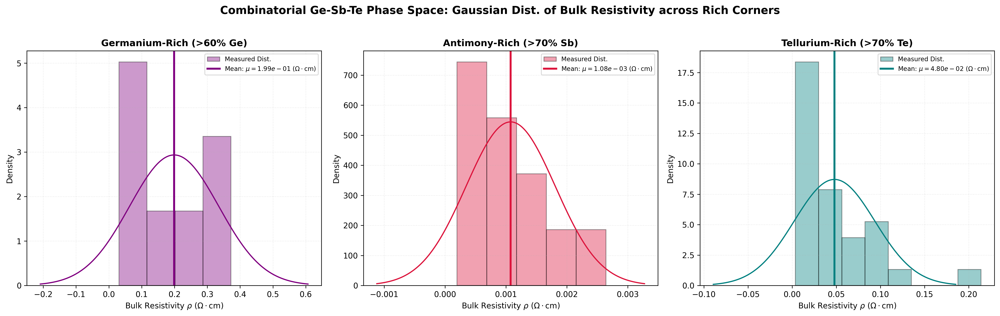

In [388]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# ==============================================================================
# TROUBLESHOOTING & PLOTTING BLOCK
# ==============================================================================

# Define compositional corners and plotting properties
# Ensure data is filtered before assignment to avoid chained assignment warnings
# It is assumed 'gst_scan_book_merged' is already calculated with 'rho_Ohm_cm'
ge_rich_subset = gst_scan_book_merged[gst_scan_book_merged['Ge_at'] > 60.0].copy()
sb_rich_subset = gst_scan_book_merged[gst_scan_book_merged['Sb_at'] > 70.0].copy()
te_rich_subset = gst_scan_book_merged[gst_scan_book_merged['Te_at'] > 70.0].copy()

corners_analysis = [
    ('Germanium-Rich (>60% Ge)', ge_rich_subset, 'purple'),
    ('Antimony-Rich (>70% Sb)', sb_rich_subset, 'crimson'),
    ('Tellurium-Rich (>70% Te)', te_rich_subset, 'teal'),
]

# Initialize the 3-subplot figure (1x3 format)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=300)

for idx, (title, subset, color) in enumerate(corners_analysis):
  ax = axes[idx]

  # a. Extract and transform target data: bulk resistivity
  # Filter out non-positive resistivity values
  # Use .loc to avoid SettingWithCopyWarning and ensure only positive rho values are used
  valid_rho = subset.loc[subset['rho_Ohm_cm'] > 0, 'rho_Ohm_cm']

  # Specific outlier removal for Te-Rich corner
  if title == 'Tellurium-Rich (>70% Te)':
    valid_rho = valid_rho[valid_rho <= 10000] # Filter out values > 10000

  rho_vals = valid_rho # Use raw resistivity values

  if len(rho_vals) < 3: # Handle sparse data corners
      ax.text(0.5, 0.5, "Insufficient Data", ha='center', va='center')
      ax.set_title(title, fontsize=12, fontweight='bold')
      continue

  # b. Standard Data Standardization (Gaussian Parameters Calculation)
  mean_rho = rho_vals.mean()
  std_rho = rho_vals.std()

  # c. Plot Histogram (Density distribution)
  # Check for NaNs/Infs which might cause issues during histogram calculation
  clean_rho = rho_vals.replace([np.inf, -np.inf], np.nan).dropna()

  if len(clean_rho) > 0:
      ax.hist(
          clean_rho,
          bins='auto', # Use 'auto' for dynamic binning with raw values
          density=True,
          alpha=0.4,
          color=color,
          edgecolor='black',
          label='Measured Dist.',
      )

      # d. Add Vertical reference line for the mean
      # Ensure raw string literal (r'') is used for LaTeX rendering to avoid escape errors
      ax.axvline(
          mean_rho,
          color=color,
          linestyle='-',
          linewidth=2.5,
          label=rf'Mean: $\mu={mean_rho:.2e}$ ($\Omega\cdot\mathrm{{cm}}$)', # Update label
      )

      # e. Generate and Plot the Bellcurve (Normal PDF fit)
      # Create a continuous range spanning \u00b13 standard deviations
      x_range = np.linspace(mean_rho - 3 * std_rho, mean_rho + 3 * std_rho, 200)
      bellcurve_y = stats.norm.pdf(x_range, mean_rho, std_rho)

      ax.plot(x_range, bellcurve_y, color=color, linestyle='-', linewidth=1.5)

  # f. Formatting Subplot Canvas
  ax.set_title(title, fontsize=12, fontweight='bold')
  # Correctly formatted raw string literal with proper LaTeX syntax for label rendering
  ax.set_xlabel(r'Bulk Resistivity $\rho$ ($\Omega\cdot\mathrm{{cm}}$)', fontsize=10) # Update label
  ax.set_ylabel('Density', fontsize=10)
  ax.legend(fontsize=8.0, frameon=True, loc='upper right')
  ax.grid(True, linestyle=':', alpha=0.3)

# 3. Final Canvas Formatting and Output
plt.suptitle(
    'Combinatorial Ge-Sb-Te Phase Space: Gaussian Dist. of Bulk Resistivity'
    ' across Rich Corners',
    fontsize=14,
    fontweight='bold',
    y=1.02,
)
plt.tight_layout()
plt.show()

##GST Reflectance

In [389]:
gst_spectral = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/spectral_scan_full_18ch_wafer3.csv')

###Scan Map

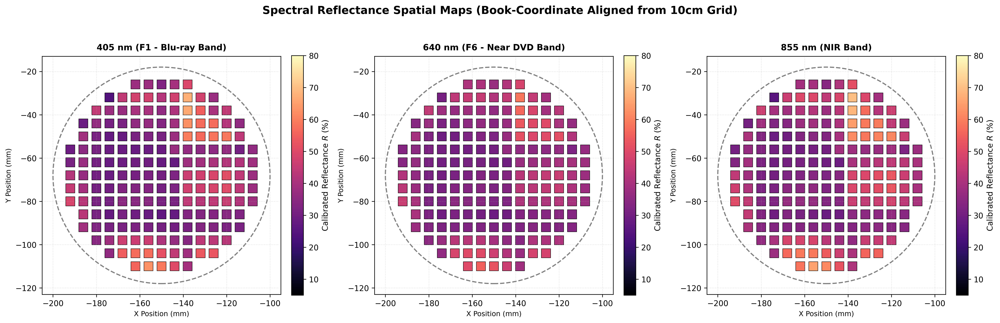

In [390]:
df_spec = gst_spectral

for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_spec[f'{ch}_Refl_pct'] = ((df_spec[ch] - d) / (w - d)) * 100.0

# 2. Interpolate spectral reflectance onto each wafer node (X_mm, Y_mm) in gst_scan_book_merged
for ch in ['F1_405nm', 'F6_640nm', 'NIR_855nm']:
  col_pct = f'{ch}_Refl_pct'
  gst_scan_book_merged[col_pct] = griddata(
      (df_spec['X_mm'], df_spec['Y_mm']),
      df_spec[col_pct],
      (gst_scan_book_merged['X_mm'], gst_scan_book_merged['Y_mm']),
      method='linear',
  )
  # Fill edge NaNs with nearest neighbor
  nan_mask = gst_scan_book_merged[col_pct].isnull()
  if nan_mask.any():
    gst_scan_book_merged.loc[nan_mask, col_pct] = griddata(
        (df_spec['X_mm'], df_spec['Y_mm']),
        df_spec[col_pct],
        (
            gst_scan_book_merged.loc[nan_mask, 'X_mm'],
            gst_scan_book_merged.loc[nan_mask, 'Y_mm'],
        ),
        method='nearest',
    )

# 4. Plotting 3-Subplot Spectral Spatial Maps
wafer_radius = 50  # mm
center_x, center_y = -150, -68

fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=300)
channels_to_plot = [
    ('F1_405nm_Refl_pct', '405 nm (F1 - Blu-ray Band)', 'magma'),
    ('F6_640nm_Refl_pct', '640 nm (F6 - Near DVD Band)', 'magma'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)', 'magma'),
]

for idx, (col_name, label, cmap) in enumerate(channels_to_plot):
  ax = axes[idx]

  sc = ax.scatter(
      gst_scan_book_merged['X_mm'],
      gst_scan_book_merged['Y_mm'],
      c=gst_scan_book_merged[col_name],
      cmap=cmap,
      marker='s',
      s=140,
      edgecolors='black',
      linewidth=0.5,
      vmin=5.0,
      vmax=80.0,
  )

  wafer_outline = plt.Circle(
      (center_x, center_y),
      wafer_radius,
      color='gray',
      fill=False,
      linestyle='--',
      linewidth=1.5,
  )
  ax.add_patch(wafer_outline)

  ax.set_aspect('equal', adjustable='box')
  ax.set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
  ax.set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

  cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
  cbar.set_label('Calibrated Reflectance $R$ (%)', fontsize=10)

  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_xlabel('X Position (mm)', fontsize=9)
  ax.set_ylabel('Y Position (mm)', fontsize=9)
  ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle(
    'Spectral Reflectance Spatial Maps (Book-Coordinate Aligned from 10cm'
    ' Grid)',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

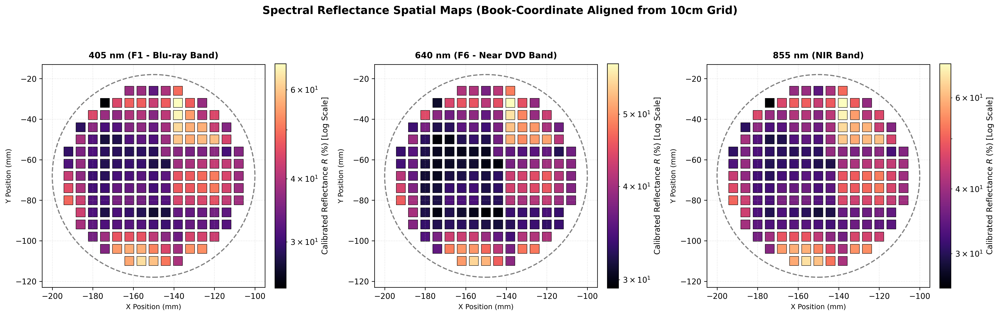

In [391]:
df_spec = gst_spectral

for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_spec[f'{ch}_Refl_pct'] = ((df_spec[ch] - d) / (w - d)) * 100.0

# 2. Interpolate spectral reflectance onto each wafer node (X_mm, Y_mm) in gst_scan_book_merged
for ch in ['F1_405nm', 'F6_640nm', 'NIR_855nm']:
  col_pct = f'{ch}_Refl_pct'
  gst_scan_book_merged[col_pct] = griddata(
      (df_spec['X_mm'], df_spec['Y_mm']),
      df_spec[col_pct],
      (gst_scan_book_merged['X_mm'], gst_scan_book_merged['Y_mm']),
      method='linear',
  )
  # Fill edge NaNs with nearest neighbor
  nan_mask = gst_scan_book_merged[col_pct].isnull()
  if nan_mask.any():
    gst_scan_book_merged.loc[nan_mask, col_pct] = griddata(
        (df_spec['X_mm'], df_spec['Y_mm']),
        df_spec[col_pct],
        (
            gst_scan_book_merged.loc[nan_mask, 'X_mm'],
            gst_scan_book_merged.loc[nan_mask, 'Y_mm'],
        ),
        method='nearest',
    )

# 4. Plotting 3-Subplot Spectral Spatial Maps
wafer_radius = 50  # mm
center_x, center_y = -150, -68

fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=300)
channels_to_plot = [
    ('F1_405nm_Refl_pct', '405 nm (F1 - Blu-ray Band)', 'magma'),
    ('F6_640nm_Refl_pct', '640 nm (F6 - Near DVD Band)', 'magma'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)', 'magma'),
]

for idx, (col_name, label, cmap) in enumerate(channels_to_plot):
  ax = axes[idx]

  # Dynamically determine vmin and vmax for LogNorm
  data = gst_scan_book_merged[col_name].dropna()
  current_vmin = max(0.01, data.min()) # Ensure vmin is always positive, using 0.01 as a floor
  current_vmax = data.max()

  sc = ax.scatter(
      gst_scan_book_merged['X_mm'],
      gst_scan_book_merged['Y_mm'],
      c=gst_scan_book_merged[col_name],
      cmap=cmap,
      marker='s',
      s=140,
      edgecolors='black',
      linewidth=0.5,
      norm=mcolors.LogNorm(vmin=current_vmin, vmax=current_vmax),
  )

  wafer_outline = plt.Circle(
      (center_x, center_y),
      wafer_radius,
      color='gray',
      fill=False,
      linestyle='--',
      linewidth=1.5,
  )
  ax.add_patch(wafer_outline)

  ax.set_aspect('equal', adjustable='box')
  ax.set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
  ax.set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

  cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
  cbar.set_label('Calibrated Reflectance $R$ (%) [Log Scale]', fontsize=10)

  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_xlabel('X Position (mm)', fontsize=9)
  ax.set_ylabel('Y Position (mm)', fontsize=9)
  ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle(
    'Spectral Reflectance Spatial Maps (Book-Coordinate Aligned from 10cm'
    ' Grid)',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

###Ternary Space Mapping

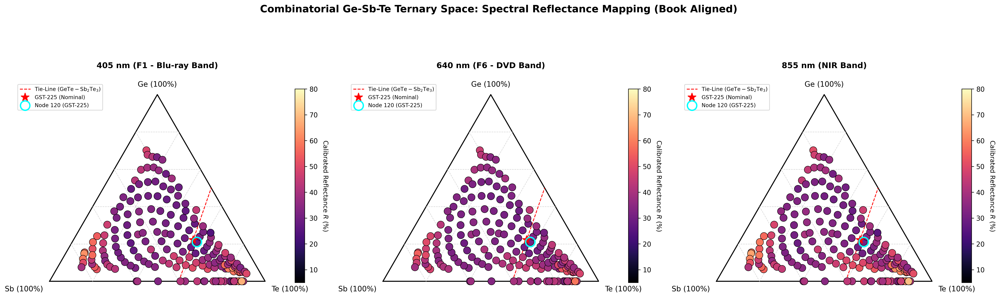

In [392]:
df_spec = gst_spectral

for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_spec[f'{ch}_Refl_pct'] = ((df_spec[ch] - d) / (w - d)) * 100.0

# 3. Interpolate spectral reflectance onto each wafer node (X_mm, Y_mm) in gst_scan_book_merged
for ch in ['F1_405nm', 'F6_640nm', 'NIR_855nm']:
  col_pct = f'{ch}_Refl_pct'
  gst_scan_book_merged[col_pct] = griddata(
      (df_spec['X_mm'], df_spec['Y_mm']),
      df_spec[col_pct],
      (gst_scan_book_merged['X_mm'], gst_scan_book_merged['Y_mm']),
      method='linear',
  )
  nan_mask = gst_scan_book_merged[col_pct].isnull()
  if nan_mask.any():
    gst_scan_book_merged.loc[nan_mask, col_pct] = griddata(
        (df_spec['X_mm'], df_spec['Y_mm']),
        df_spec[col_pct],
        (
            gst_scan_book_merged.loc[nan_mask, 'X_mm'],
            gst_scan_book_merged.loc[nan_mask, 'Y_mm'],
        ),
        method='nearest',
    )

# 4. Plot 1x3 Ternary Maps for Top 3 Spectral Channels
fig, axes = plt.subplots(1, 3, figsize=(21, 7.5), dpi=300)
channels_to_plot = [
    ('F1_405nm_Refl_pct', '405 nm (F1 - Blu-ray Band)', 'magma'),
    ('F6_640nm_Refl_pct', '640 nm (F6 - DVD Band)', 'magma'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)', 'magma'),
]

sqrt3_2 = np.sqrt(3) / 2.0


def setup_gst_ternary(ax, title):
  ax.plot([0, 1, 0.5, 0], [0, 0, sqrt3_2, 0], 'k-', lw=1.5)
  for p in [0.2, 0.4, 0.6, 0.8]:
    ax.plot(
        [0.5 * p, 1 - 0.5 * p],
        [sqrt3_2 * p, sqrt3_2 * p],
        color='lightgray',
        linestyle='--',
        lw=0.7,
    )
    ax.plot(
        [p, 0.5 * p + 0.5],
        [0, sqrt3_2 * (1 - p)],
        color='lightgray',
        linestyle='--',
        lw=0.7,
    )
    ax.plot(
        [1 - p, 0.5 * (1 - p)],
        [0, sqrt3_2 * (1 - p)],
        color='lightgray',
        linestyle='--',
        lw=0.7,
    )

  ax.text(0.5, sqrt3_2 + 0.03, 'Ge (100%)', ha='center', va='bottom', fontsize=11)
  ax.text(-0.03, -0.02, 'Sb (100%)', ha='right', va='top', fontsize=11)
  ax.text(1.03, -0.02, 'Te (100%)', ha='left', va='top', fontsize=11)

  # Pseudobinary tie-line
  ax.plot(
      [0.60, 0.75],
      [0, sqrt3_2 * 0.5],
      'r--',
      lw=1.2,
      label=r'Tie-Line ($\mathrm{GeTe - Sb_2Te_3}$)',
  )

  # Nominal GST-225 Star
  gx = 5 / 9 + 0.5 * (2 / 9)
  gy = sqrt3_2 * (2 / 9)
  ax.plot(
      gx, gy, 'r*', markersize=13, zorder=10, label='GST-225 (Nominal)'
  )

  # Highlight Node 120 Determination
  node120 = gst_scan_book_merged[gst_scan_book_merged['Node_ID'] == 120].iloc[0]
  ax.scatter(
      node120['ternary_x_at'],
      node120['ternary_y_at'],
      s=200,
      facecolors='none',
      edgecolors='cyan',
      linewidths=2.0,
      zorder=11,
      label='Node 120 (GST-225)',
  )

  ax.set_title(title, fontsize=12, pad=14, fontweight='bold')
  ax.legend(
      loc='upper left', bbox_to_anchor=(-0.05, 0.98), fontsize=8.0, frameon=True
  )
  ax.set_xlim(-0.10, 1.10)
  ax.set_ylim(-0.06, sqrt3_2 + 0.08)
  ax.set_aspect('equal')
  ax.axis('off')


for idx, (col_key, title, cmap) in enumerate(channels_to_plot):
  ax = axes[idx]
  setup_gst_ternary(ax, title)

  sc = ax.scatter(
      gst_scan_book_merged['ternary_x_at'],
      gst_scan_book_merged['ternary_y_at'],
      c=gst_scan_book_merged[col_key],
      cmap=cmap,
      vmin=5.0,
      vmax=80.0,
      s=120,
      edgecolors='black',
      linewidths=0.6,
      zorder=5,
  )
  cbar = fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.03)
  cbar.set_label(
      'Calibrated Reflectance $R$ (%)', rotation=270, labelpad=16, fontsize=9.5
  )

plt.suptitle(
    'Combinatorial Ge-Sb-Te Ternary Space: Spectral Reflectance Mapping (Book'
    ' Aligned)',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

###Distribution at the corners

In [393]:
# 1. Define atomic percentage thresholds for each corner
corner_ge = gst_scan_book_merged[gst_scan_book_merged['Ge_at'] > 60.0]
corner_sb = gst_scan_book_merged[gst_scan_book_merged['Sb_at'] > 70.0]
corner_te = gst_scan_book_merged[gst_scan_book_merged['Te_at'] > 70.0]

# 2. Calculate average reflectance across the top 3 spectral channels
spectral_cols = [
    'F1_405nm_Refl_pct',
    'F6_640nm_Refl_pct',
    'NIR_855nm_Refl_pct',
]

print('=== GERMANIUM-RICH CORNER (>60% Ge) ===')
print(corner_ge[spectral_cols].mean())
print(f'Sample Count: {len(corner_ge)}\n')

print('=== ANTIMONY-RICH CORNER (>70% Sb) ===')
print(corner_sb[spectral_cols].mean())
print(f'Sample Count: {len(corner_sb)}\n')

print('=== TELLURIUM-RICH CORNER (>70% Te) ===')
print(corner_te[spectral_cols].mean())
print(f'Sample Count: {len(corner_te)}\n')

=== GERMANIUM-RICH CORNER (>60% Ge) ===
F1_405nm_Refl_pct     39.775699
F6_640nm_Refl_pct     39.119214
NIR_855nm_Refl_pct    41.627124
dtype: float64
Sample Count: 7

=== ANTIMONY-RICH CORNER (>70% Sb) ===
F1_405nm_Refl_pct     51.425418
F6_640nm_Refl_pct     46.747475
NIR_855nm_Refl_pct    53.574536
dtype: float64
Sample Count: 11

=== TELLURIUM-RICH CORNER (>70% Te) ===
F1_405nm_Refl_pct     44.411175
F6_640nm_Refl_pct     42.243700
NIR_855nm_Refl_pct    46.354883
dtype: float64
Sample Count: 46



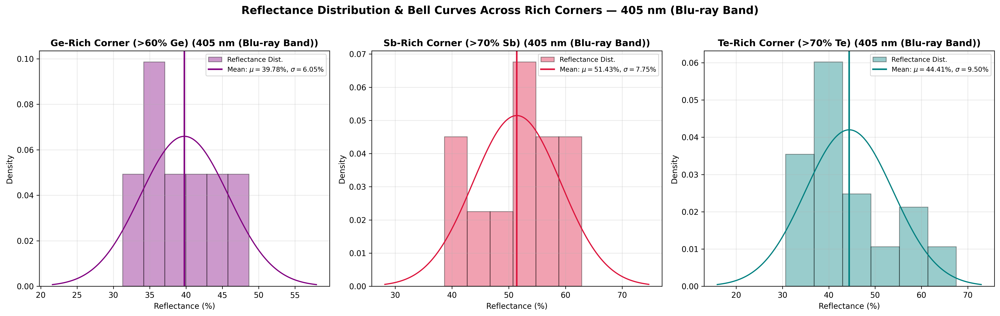

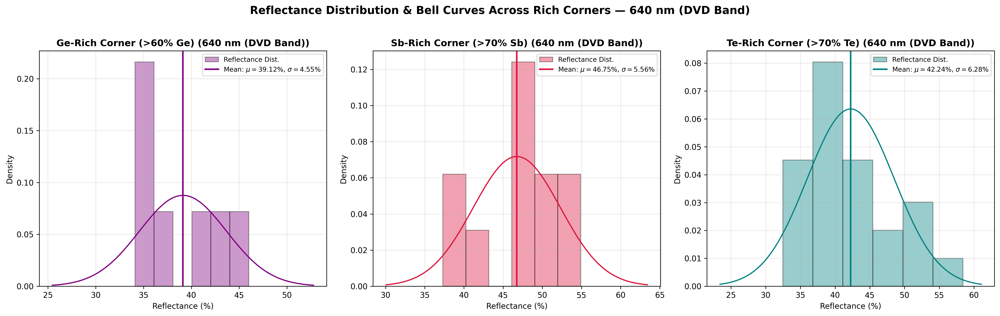

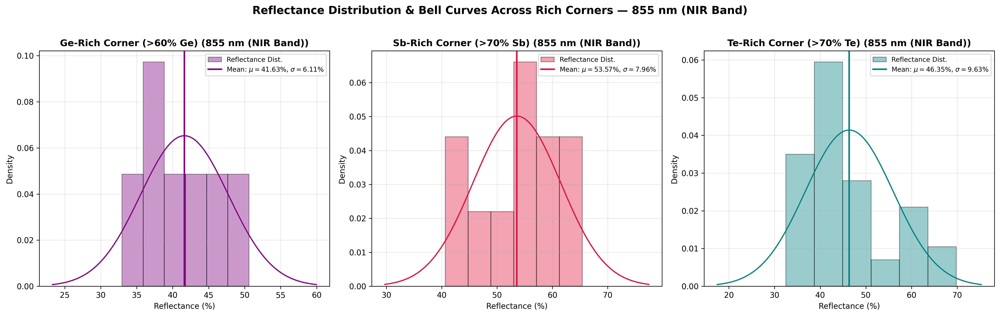

In [394]:
# Define wavelengths to iterate over
wavelengths = [
    ('F1_405nm_Refl_pct', '405 nm (Blu-ray Band)'),
    ('F6_640nm_Refl_pct', '640 nm (DVD Band)'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)'),
]

# Define the three compositional rich corners
corners = [
    (
        'Ge-Rich Corner (>60% Ge)',
        gst_scan_book_merged[gst_scan_book_merged['Ge_at'] > 60.0],
        'purple',
    ),
    (
        'Sb-Rich Corner (>70% Sb)',
        gst_scan_book_merged[gst_scan_book_merged['Sb_at'] > 70.0],
        'crimson',
    ),
    (
        'Te-Rich Corner (>70% Te)',
        gst_scan_book_merged[gst_scan_book_merged['Te_at'] > 70.0],
        'teal',
    ),
]

for col_key, wl_label in wavelengths:
  fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=300)

  for idx, (title, subset, color) in enumerate(corners):
    ax = axes[idx]

    # Extract reflectance values for the current wavelength
    refl_vals = subset[col_key].dropna()
    mean_m = refl_vals.mean()
    std_m = refl_vals.std()

    # Histogram + Vertical Mean Line with mean & std dev in legend
    ax.hist(
        refl_vals,
        bins=6,
        density=True,
        alpha=0.4,
        color=color,
        edgecolor='black',
        label='Reflectance Dist.',
    )
    ax.axvline(
        mean_m,
        color=color,
        linestyle='-',
        linewidth=2,
        label=rf'Mean: $\mu={mean_m:.2f}\%$, $\sigma={std_m:.2f}\%$',
    )

    # Bell curve
    x = np.linspace(mean_m - 3 * std_m, mean_m + 3 * std_m, 200)
    y = stats.norm.pdf(x, mean_m, std_m)
    ax.plot(x, y, color=color, linestyle='-', linewidth=1.5)

    # Canvas formatting
    ax.set_title(f'{title} ({wl_label})', fontsize=12, fontweight='bold')
    ax.set_xlabel(r'Reflectance (%)', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.legend(fontsize=8.5)
    ax.grid(True, alpha=0.3)

  plt.suptitle(
      f'Reflectance Distribution & Bell Curves Across Rich Corners —'
      f' {wl_label}',
      fontsize=14,
      fontweight='bold',
      y=1.02,
  )
  plt.tight_layout()
  plt.show()

##GST Reflectance 200deg

In [395]:
gst_spectral = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/crystalline_refle2.csv')

###Scan Map

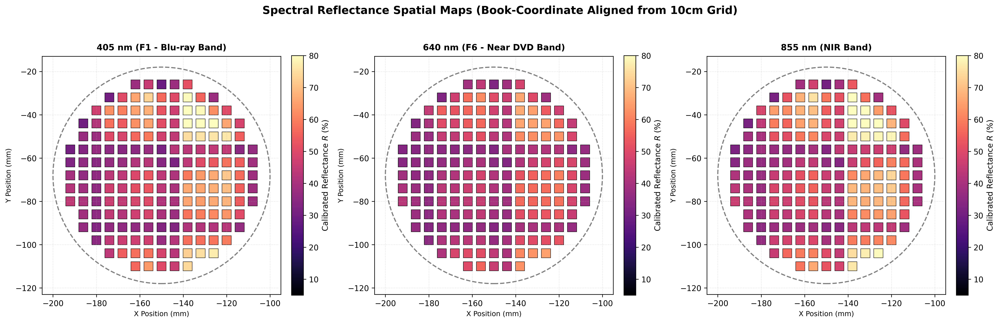

In [396]:
df_spec = gst_spectral

for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_spec[f'{ch}_Refl_pct'] = ((df_spec[ch] - d) / (w - d)) * 100.0

# 2. Interpolate spectral reflectance onto each wafer node (X_mm, Y_mm) in gst_scan_book_merged
for ch in ['F1_405nm', 'F6_640nm', 'NIR_855nm']:
  col_pct = f'{ch}_Refl_pct'
  gst_scan_book_merged[col_pct] = griddata(
      (df_spec['X_mm'], df_spec['Y_mm']),
      df_spec[col_pct],
      (gst_scan_book_merged['X_mm'], gst_scan_book_merged['Y_mm']),
      method='linear',
  )
  # Fill edge NaNs with nearest neighbor
  nan_mask = gst_scan_book_merged[col_pct].isnull()
  if nan_mask.any():
    gst_scan_book_merged.loc[nan_mask, col_pct] = griddata(
        (df_spec['X_mm'], df_spec['Y_mm']),
        df_spec[col_pct],
        (
            gst_scan_book_merged.loc[nan_mask, 'X_mm'],
            gst_scan_book_merged.loc[nan_mask, 'Y_mm'],
        ),
        method='nearest',
    )

# 4. Plotting 3-Subplot Spectral Spatial Maps
wafer_radius = 50  # mm
center_x, center_y = -150, -68

fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=300)
channels_to_plot = [
    ('F1_405nm_Refl_pct', '405 nm (F1 - Blu-ray Band)', 'magma'),
    ('F6_640nm_Refl_pct', '640 nm (F6 - Near DVD Band)', 'magma'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)', 'magma'),
]

for idx, (col_name, label, cmap) in enumerate(channels_to_plot):
  ax = axes[idx]

  sc = ax.scatter(
      gst_scan_book_merged['X_mm'],
      gst_scan_book_merged['Y_mm'],
      c=gst_scan_book_merged[col_name],
      cmap=cmap,
      marker='s',
      s=140,
      edgecolors='black',
      linewidth=0.5,
      vmin=5.0,
      vmax=80.0,
  )

  wafer_outline = plt.Circle(
      (center_x, center_y),
      wafer_radius,
      color='gray',
      fill=False,
      linestyle='--',
      linewidth=1.5,
  )
  ax.add_patch(wafer_outline)

  ax.set_aspect('equal', adjustable='box')
  ax.set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
  ax.set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

  cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
  cbar.set_label('Calibrated Reflectance $R$ (%)', fontsize=10)

  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_xlabel('X Position (mm)', fontsize=9)
  ax.set_ylabel('Y Position (mm)', fontsize=9)
  ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle(
    'Spectral Reflectance Spatial Maps (Book-Coordinate Aligned from 10cm'
    ' Grid)',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

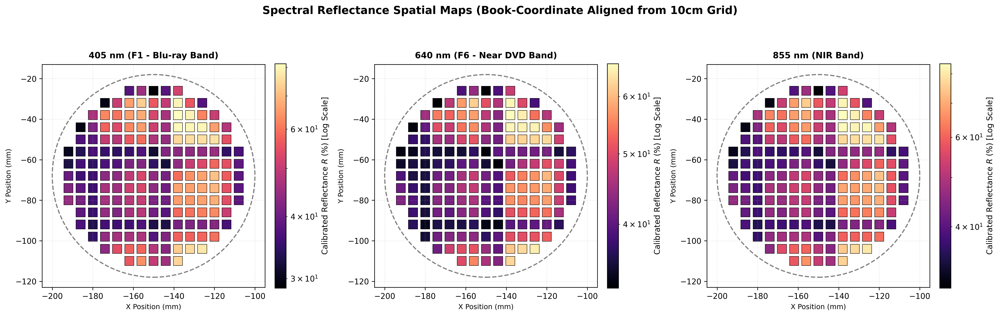

In [397]:
df_spec = gst_spectral

for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_spec[f'{ch}_Refl_pct'] = ((df_spec[ch] - d) / (w - d)) * 100.0

# 2. Interpolate spectral reflectance onto each wafer node (X_mm, Y_mm) in gst_scan_book_merged
for ch in ['F1_405nm', 'F6_640nm', 'NIR_855nm']:
  col_pct = f'{ch}_Refl_pct'
  gst_scan_book_merged[col_pct] = griddata(
      (df_spec['X_mm'], df_spec['Y_mm']),
      df_spec[col_pct],
      (gst_scan_book_merged['X_mm'], gst_scan_book_merged['Y_mm']),
      method='linear',
  )
  # Fill edge NaNs with nearest neighbor
  nan_mask = gst_scan_book_merged[col_pct].isnull()
  if nan_mask.any():
    gst_scan_book_merged.loc[nan_mask, col_pct] = griddata(
        (df_spec['X_mm'], df_spec['Y_mm']),
        df_spec[col_pct],
        (
            gst_scan_book_merged.loc[nan_mask, 'X_mm'],
            gst_scan_book_merged.loc[nan_mask, 'Y_mm'],
        ),
        method='nearest',
    )

# 4. Plotting 3-Subplot Spectral Spatial Maps
wafer_radius = 50  # mm
center_x, center_y = -150, -68

fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=300)
channels_to_plot = [
    ('F1_405nm_Refl_pct', '405 nm (F1 - Blu-ray Band)', 'magma'),
    ('F6_640nm_Refl_pct', '640 nm (F6 - Near DVD Band)', 'magma'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)', 'magma'),
]

for idx, (col_name, label, cmap) in enumerate(channels_to_plot):
  ax = axes[idx]

  # Dynamically determine vmin and vmax for LogNorm
  data = gst_scan_book_merged[col_name].dropna()
  current_vmin = max(0.01, data.min()) # Ensure vmin is always positive, using 0.01 as a floor
  current_vmax = data.max()

  sc = ax.scatter(
      gst_scan_book_merged['X_mm'],
      gst_scan_book_merged['Y_mm'],
      c=gst_scan_book_merged[col_name],
      cmap=cmap,
      marker='s',
      s=140,
      edgecolors='black',
      linewidth=0.5,
      norm=mcolors.LogNorm(vmin=current_vmin, vmax=current_vmax),
  )

  wafer_outline = plt.Circle(
      (center_x, center_y),
      wafer_radius,
      color='gray',
      fill=False,
      linestyle='--',
      linewidth=1.5,
  )
  ax.add_patch(wafer_outline)

  ax.set_aspect('equal', adjustable='box')
  ax.set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
  ax.set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

  cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
  cbar.set_label('Calibrated Reflectance $R$ (%) [Log Scale]', fontsize=10)

  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_xlabel('X Position (mm)', fontsize=9)
  ax.set_ylabel('Y Position (mm)', fontsize=9)
  ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle(
    'Spectral Reflectance Spatial Maps (Book-Coordinate Aligned from 10cm'
    ' Grid)',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

###Ternary Space Mapping

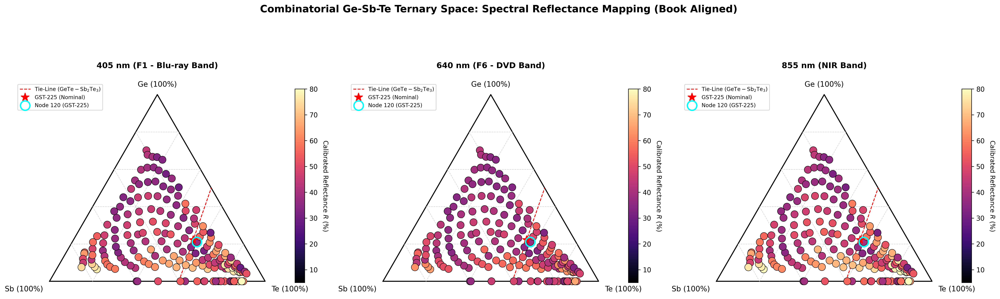

In [398]:
df_spec = gst_spectral

for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_spec[f'{ch}_Refl_pct'] = ((df_spec[ch] - d) / (w - d)) * 100.0

# 3. Interpolate spectral reflectance onto each wafer node (X_mm, Y_mm) in gst_scan_book_merged
for ch in ['F1_405nm', 'F6_640nm', 'NIR_855nm']:
  col_pct = f'{ch}_Refl_pct'
  gst_scan_book_merged[col_pct] = griddata(
      (df_spec['X_mm'], df_spec['Y_mm']),
      df_spec[col_pct],
      (gst_scan_book_merged['X_mm'], gst_scan_book_merged['Y_mm']),
      method='linear',
  )
  nan_mask = gst_scan_book_merged[col_pct].isnull()
  if nan_mask.any():
    gst_scan_book_merged.loc[nan_mask, col_pct] = griddata(
        (df_spec['X_mm'], df_spec['Y_mm']),
        df_spec[col_pct],
        (
            gst_scan_book_merged.loc[nan_mask, 'X_mm'],
            gst_scan_book_merged.loc[nan_mask, 'Y_mm'],
        ),
        method='nearest',
    )

# 4. Plot 1x3 Ternary Maps for Top 3 Spectral Channels
fig, axes = plt.subplots(1, 3, figsize=(21, 7.5), dpi=300)
channels_to_plot = [
    ('F1_405nm_Refl_pct', '405 nm (F1 - Blu-ray Band)', 'magma'),
    ('F6_640nm_Refl_pct', '640 nm (F6 - DVD Band)', 'magma'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)', 'magma'),
]

sqrt3_2 = np.sqrt(3) / 2.0


def setup_gst_ternary(ax, title):
  ax.plot([0, 1, 0.5, 0], [0, 0, sqrt3_2, 0], 'k-', lw=1.5)
  for p in [0.2, 0.4, 0.6, 0.8]:
    ax.plot(
        [0.5 * p, 1 - 0.5 * p],
        [sqrt3_2 * p, sqrt3_2 * p],
        color='lightgray',
        linestyle='--',
        lw=0.7,
    )
    ax.plot(
        [p, 0.5 * p + 0.5],
        [0, sqrt3_2 * (1 - p)],
        color='lightgray',
        linestyle='--',
        lw=0.7,
    )
    ax.plot(
        [1 - p, 0.5 * (1 - p)],
        [0, sqrt3_2 * (1 - p)],
        color='lightgray',
        linestyle='--',
        lw=0.7,
    )

  ax.text(0.5, sqrt3_2 + 0.03, 'Ge (100%)', ha='center', va='bottom', fontsize=11)
  ax.text(-0.03, -0.02, 'Sb (100%)', ha='right', va='top', fontsize=11)
  ax.text(1.03, -0.02, 'Te (100%)', ha='left', va='top', fontsize=11)

  # Pseudobinary tie-line
  ax.plot(
      [0.60, 0.75],
      [0, sqrt3_2 * 0.5],
      'r--',
      lw=1.2,
      label=r'Tie-Line ($\mathrm{GeTe - Sb_2Te_3}$)',
  )

  # Nominal GST-225 Star
  gx = 5 / 9 + 0.5 * (2 / 9)
  gy = sqrt3_2 * (2 / 9)
  ax.plot(
      gx, gy, 'r*', markersize=13, zorder=10, label='GST-225 (Nominal)'
  )

  # Highlight Node 120 Determination
  node120 = gst_scan_book_merged[gst_scan_book_merged['Node_ID'] == 120].iloc[0]
  ax.scatter(
      node120['ternary_x_at'],
      node120['ternary_y_at'],
      s=200,
      facecolors='none',
      edgecolors='cyan',
      linewidths=2.0,
      zorder=11,
      label='Node 120 (GST-225)',
  )

  ax.set_title(title, fontsize=12, pad=14, fontweight='bold')
  ax.legend(
      loc='upper left', bbox_to_anchor=(-0.05, 0.98), fontsize=8.0, frameon=True
  )
  ax.set_xlim(-0.10, 1.10)
  ax.set_ylim(-0.06, sqrt3_2 + 0.08)
  ax.set_aspect('equal')
  ax.axis('off')


for idx, (col_key, title, cmap) in enumerate(channels_to_plot):
  ax = axes[idx]
  setup_gst_ternary(ax, title)

  sc = ax.scatter(
      gst_scan_book_merged['ternary_x_at'],
      gst_scan_book_merged['ternary_y_at'],
      c=gst_scan_book_merged[col_key],
      cmap=cmap,
      vmin=5.0,
      vmax=80.0,
      s=120,
      edgecolors='black',
      linewidths=0.6,
      zorder=5,
  )
  cbar = fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.03)
  cbar.set_label(
      'Calibrated Reflectance $R$ (%)', rotation=270, labelpad=16, fontsize=9.5
  )

plt.suptitle(
    'Combinatorial Ge-Sb-Te Ternary Space: Spectral Reflectance Mapping (Book'
    ' Aligned)',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

###Distribution at the corners

In [399]:
# 1. Define atomic percentage thresholds for each corner
corner_ge = gst_scan_book_merged[gst_scan_book_merged['Ge_at'] > 60.0]
corner_sb = gst_scan_book_merged[gst_scan_book_merged['Sb_at'] > 70.0]
corner_te = gst_scan_book_merged[gst_scan_book_merged['Te_at'] > 70.0]

# 2. Calculate average reflectance across the top 3 spectral channels
spectral_cols = [
    'F1_405nm_Refl_pct',
    'F6_640nm_Refl_pct',
    'NIR_855nm_Refl_pct',
]

print('=== GERMANIUM-RICH CORNER (>60% Ge) ===')
print(corner_ge[spectral_cols].mean())
print(f'Sample Count: {len(corner_ge)}\n')

print('=== ANTIMONY-RICH CORNER (>70% Sb) ===')
print(corner_sb[spectral_cols].mean())
print(f'Sample Count: {len(corner_sb)}\n')

print('=== TELLURIUM-RICH CORNER (>70% Te) ===')
print(corner_te[spectral_cols].mean())
print(f'Sample Count: {len(corner_te)}\n')

=== GERMANIUM-RICH CORNER (>60% Ge) ===
F1_405nm_Refl_pct     38.149420
F6_640nm_Refl_pct     37.769204
NIR_855nm_Refl_pct    39.886741
dtype: float64
Sample Count: 7

=== ANTIMONY-RICH CORNER (>70% Sb) ===
F1_405nm_Refl_pct     60.365411
F6_640nm_Refl_pct     52.903378
NIR_855nm_Refl_pct    62.651481
dtype: float64
Sample Count: 11

=== TELLURIUM-RICH CORNER (>70% Te) ===
F1_405nm_Refl_pct     55.860489
F6_640nm_Refl_pct     49.751393
NIR_855nm_Refl_pct    57.875664
dtype: float64
Sample Count: 46



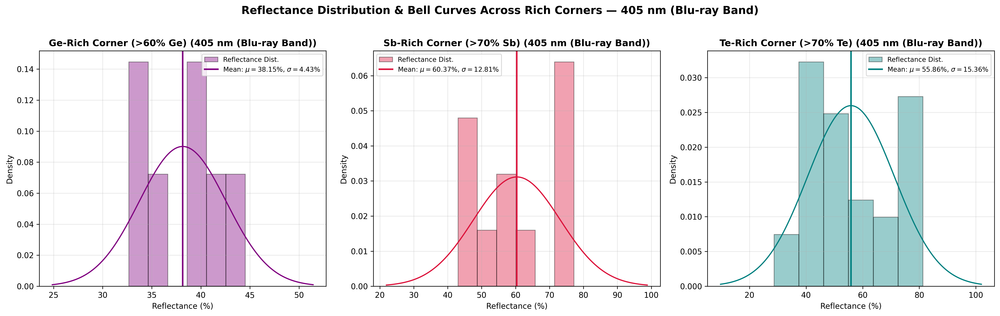

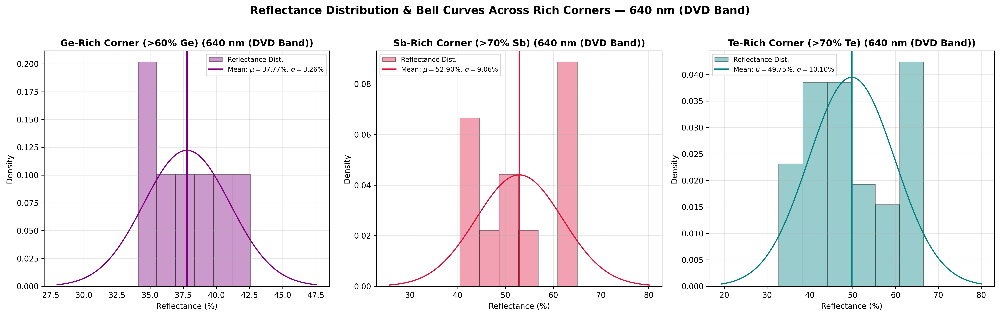

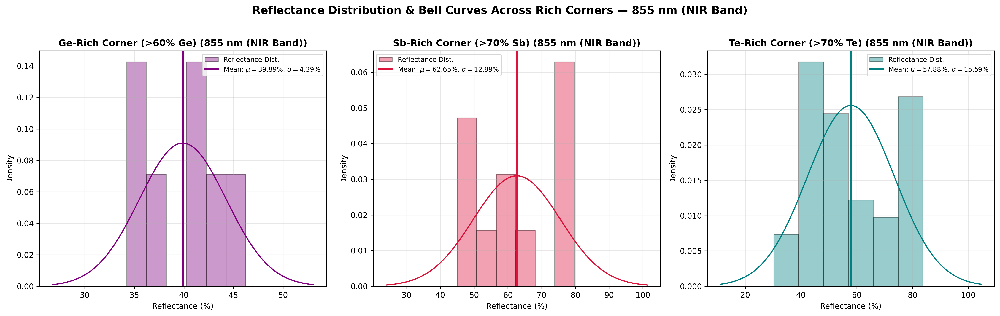

In [400]:
# Define wavelengths to iterate over
wavelengths = [
    ('F1_405nm_Refl_pct', '405 nm (Blu-ray Band)'),
    ('F6_640nm_Refl_pct', '640 nm (DVD Band)'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)'),
]

# Define the three compositional rich corners
corners = [
    (
        'Ge-Rich Corner (>60% Ge)',
        gst_scan_book_merged[gst_scan_book_merged['Ge_at'] > 60.0],
        'purple',
    ),
    (
        'Sb-Rich Corner (>70% Sb)',
        gst_scan_book_merged[gst_scan_book_merged['Sb_at'] > 70.0],
        'crimson',
    ),
    (
        'Te-Rich Corner (>70% Te)',
        gst_scan_book_merged[gst_scan_book_merged['Te_at'] > 70.0],
        'teal',
    ),
]

for col_key, wl_label in wavelengths:
  fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=300)

  for idx, (title, subset, color) in enumerate(corners):
    ax = axes[idx]

    # Extract reflectance values for the current wavelength
    refl_vals = subset[col_key].dropna()
    mean_m = refl_vals.mean()
    std_m = refl_vals.std()

    # Histogram + Vertical Mean Line with mean & std dev in legend
    ax.hist(
        refl_vals,
        bins=6,
        density=True,
        alpha=0.4,
        color=color,
        edgecolor='black',
        label='Reflectance Dist.',
    )
    ax.axvline(
        mean_m,
        color=color,
        linestyle='-',
        linewidth=2,
        label=rf'Mean: $\mu={mean_m:.2f}\%$, $\sigma={std_m:.2f}\%$',
    )

    # Bell curve
    x = np.linspace(mean_m - 3 * std_m, mean_m + 3 * std_m, 200)
    y = stats.norm.pdf(x, mean_m, std_m)
    ax.plot(x, y, color=color, linestyle='-', linewidth=1.5)

    # Canvas formatting
    ax.set_title(f'{title} ({wl_label})', fontsize=12, fontweight='bold')
    ax.set_xlabel(r'Reflectance (%)', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.legend(fontsize=8.5)
    ax.grid(True, alpha=0.3)

  plt.suptitle(
      f'Reflectance Distribution & Bell Curves Across Rich Corners —'
      f' {wl_label}',
      fontsize=14,
      fontweight='bold',
      y=1.02,
  )
  plt.tight_layout()
  plt.show()

##GST Reflectance 300deg

In [401]:
gst_spectral = pd.read_csv('https://github.com/irfanbstr/MScFinalProject_Datasets/raw/refs/heads/main/300_refle2.csv')

###Scan Map

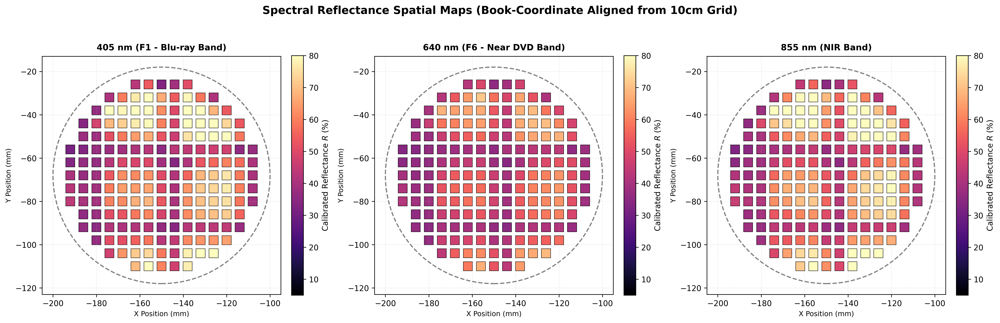

In [402]:
df_spec = gst_spectral

for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_spec[f'{ch}_Refl_pct'] = ((df_spec[ch] - d) / (w - d)) * 100.0

# 2. Interpolate spectral reflectance onto each wafer node (X_mm, Y_mm) in gst_scan_book_merged
for ch in ['F1_405nm', 'F6_640nm', 'NIR_855nm']:
  col_pct = f'{ch}_Refl_pct'
  gst_scan_book_merged[col_pct] = griddata(
      (df_spec['X_mm'], df_spec['Y_mm']),
      df_spec[col_pct],
      (gst_scan_book_merged['X_mm'], gst_scan_book_merged['Y_mm']),
      method='linear',
  )
  # Fill edge NaNs with nearest neighbor
  nan_mask = gst_scan_book_merged[col_pct].isnull()
  if nan_mask.any():
    gst_scan_book_merged.loc[nan_mask, col_pct] = griddata(
        (df_spec['X_mm'], df_spec['Y_mm']),
        df_spec[col_pct],
        (
            gst_scan_book_merged.loc[nan_mask, 'X_mm'],
            gst_scan_book_merged.loc[nan_mask, 'Y_mm'],
        ),
        method='nearest',
    )

# 4. Plotting 3-Subplot Spectral Spatial Maps
wafer_radius = 50  # mm
center_x, center_y = -150, -68

fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=300)
channels_to_plot = [
    ('F1_405nm_Refl_pct', '405 nm (F1 - Blu-ray Band)', 'magma'),
    ('F6_640nm_Refl_pct', '640 nm (F6 - Near DVD Band)', 'magma'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)', 'magma'),
]

for idx, (col_name, label, cmap) in enumerate(channels_to_plot):
  ax = axes[idx]

  sc = ax.scatter(
      gst_scan_book_merged['X_mm'],
      gst_scan_book_merged['Y_mm'],
      c=gst_scan_book_merged[col_name],
      cmap=cmap,
      marker='s',
      s=140,
      edgecolors='black',
      linewidth=0.5,
      vmin=5.0,
      vmax=80.0,
  )

  wafer_outline = plt.Circle(
      (center_x, center_y),
      wafer_radius,
      color='gray',
      fill=False,
      linestyle='--',
      linewidth=1.5,
  )
  ax.add_patch(wafer_outline)

  ax.set_aspect('equal', adjustable='box')
  ax.set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
  ax.set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

  cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
  cbar.set_label('Calibrated Reflectance $R$ (%)', fontsize=10)

  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_xlabel('X Position (mm)', fontsize=9)
  ax.set_ylabel('Y Position (mm)', fontsize=9)
  ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle(
    'Spectral Reflectance Spatial Maps (Book-Coordinate Aligned from 10cm'
    ' Grid)',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

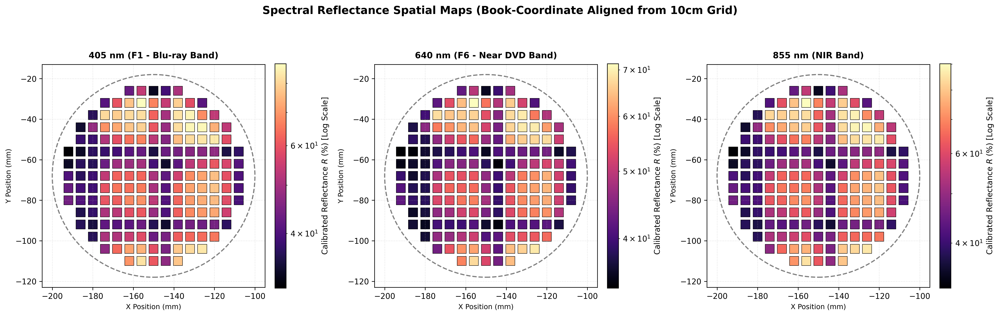

In [403]:
df_spec = gst_spectral

for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_spec[f'{ch}_Refl_pct'] = ((df_spec[ch] - d) / (w - d)) * 100.0

# 2. Interpolate spectral reflectance onto each wafer node (X_mm, Y_mm) in gst_scan_book_merged
for ch in ['F1_405nm', 'F6_640nm', 'NIR_855nm']:
  col_pct = f'{ch}_Refl_pct'
  gst_scan_book_merged[col_pct] = griddata(
      (df_spec['X_mm'], df_spec['Y_mm']),
      df_spec[col_pct],
      (gst_scan_book_merged['X_mm'], gst_scan_book_merged['Y_mm']),
      method='linear',
  )
  # Fill edge NaNs with nearest neighbor
  nan_mask = gst_scan_book_merged[col_pct].isnull()
  if nan_mask.any():
    gst_scan_book_merged.loc[nan_mask, col_pct] = griddata(
        (df_spec['X_mm'], df_spec['Y_mm']),
        df_spec[col_pct],
        (
            gst_scan_book_merged.loc[nan_mask, 'X_mm'],
            gst_scan_book_merged.loc[nan_mask, 'Y_mm'],
        ),
        method='nearest',
    )

# 4. Plotting 3-Subplot Spectral Spatial Maps
wafer_radius = 50  # mm
center_x, center_y = -150, -68

fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=300)
channels_to_plot = [
    ('F1_405nm_Refl_pct', '405 nm (F1 - Blu-ray Band)', 'magma'),
    ('F6_640nm_Refl_pct', '640 nm (F6 - Near DVD Band)', 'magma'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)', 'magma'),
]

for idx, (col_name, label, cmap) in enumerate(channels_to_plot):
  ax = axes[idx]

  # Dynamically determine vmin and vmax for LogNorm
  data = gst_scan_book_merged[col_name].dropna()
  current_vmin = max(0.01, data.min()) # Ensure vmin is always positive, using 0.01 as a floor
  current_vmax = data.max()

  sc = ax.scatter(
      gst_scan_book_merged['X_mm'],
      gst_scan_book_merged['Y_mm'],
      c=gst_scan_book_merged[col_name],
      cmap=cmap,
      marker='s',
      s=140,
      edgecolors='black',
      linewidth=0.5,
      norm=mcolors.LogNorm(vmin=current_vmin, vmax=current_vmax),
  )

  wafer_outline = plt.Circle(
      (center_x, center_y),
      wafer_radius,
      color='gray',
      fill=False,
      linestyle='--',
      linewidth=1.5,
  )
  ax.add_patch(wafer_outline)

  ax.set_aspect('equal', adjustable='box')
  ax.set_xlim(-wafer_radius - 5 + center_x, wafer_radius + 5 + center_x)
  ax.set_ylim(-wafer_radius - 5 + center_y, wafer_radius + 5 + center_y)

  cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
  cbar.set_label('Calibrated Reflectance $R$ (%) [Log Scale]', fontsize=10)

  ax.set_title(label, fontsize=11, fontweight='bold', pad=8)
  ax.set_xlabel('X Position (mm)', fontsize=9)
  ax.set_ylabel('Y Position (mm)', fontsize=9)
  ax.grid(True, linestyle=':', alpha=0.4)

plt.suptitle(
    'Spectral Reflectance Spatial Maps (Book-Coordinate Aligned from 10cm'
    ' Grid)',
    fontsize=14,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

###Ternary Space Mapping

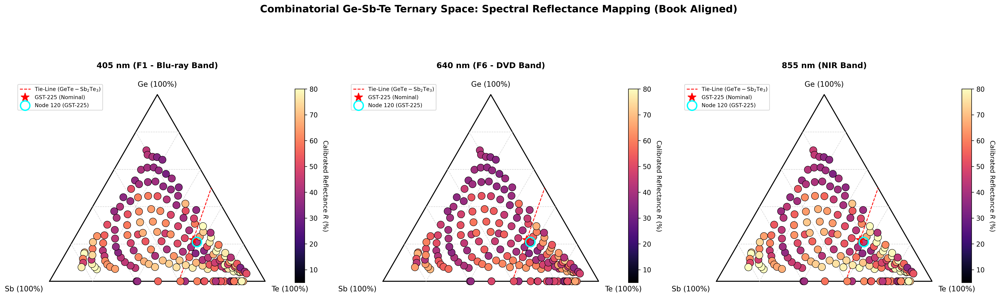

In [404]:
df_spec = gst_spectral

for ch, w in WHITE_REF_15MM_12MA.items():
  d = DARK_REF[ch]
  df_spec[f'{ch}_Refl_pct'] = ((df_spec[ch] - d) / (w - d)) * 100.0

# 3. Interpolate spectral reflectance onto each wafer node (X_mm, Y_mm) in gst_scan_book_merged
for ch in ['F1_405nm', 'F6_640nm', 'NIR_855nm']:
  col_pct = f'{ch}_Refl_pct'
  gst_scan_book_merged[col_pct] = griddata(
      (df_spec['X_mm'], df_spec['Y_mm']),
      df_spec[col_pct],
      (gst_scan_book_merged['X_mm'], gst_scan_book_merged['Y_mm']),
      method='linear',
  )
  nan_mask = gst_scan_book_merged[col_pct].isnull()
  if nan_mask.any():
    gst_scan_book_merged.loc[nan_mask, col_pct] = griddata(
        (df_spec['X_mm'], df_spec['Y_mm']),
        df_spec[col_pct],
        (
            gst_scan_book_merged.loc[nan_mask, 'X_mm'],
            gst_scan_book_merged.loc[nan_mask, 'Y_mm'],
        ),
        method='nearest',
    )

# 4. Plot 1x3 Ternary Maps for Top 3 Spectral Channels
fig, axes = plt.subplots(1, 3, figsize=(21, 7.5), dpi=300)
channels_to_plot = [
    ('F1_405nm_Refl_pct', '405 nm (F1 - Blu-ray Band)', 'magma'),
    ('F6_640nm_Refl_pct', '640 nm (F6 - DVD Band)', 'magma'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)', 'magma'),
]

sqrt3_2 = np.sqrt(3) / 2.0


def setup_gst_ternary(ax, title):
  ax.plot([0, 1, 0.5, 0], [0, 0, sqrt3_2, 0], 'k-', lw=1.5)
  for p in [0.2, 0.4, 0.6, 0.8]:
    ax.plot(
        [0.5 * p, 1 - 0.5 * p],
        [sqrt3_2 * p, sqrt3_2 * p],
        color='lightgray',
        linestyle='--',
        lw=0.7,
    )
    ax.plot(
        [p, 0.5 * p + 0.5],
        [0, sqrt3_2 * (1 - p)],
        color='lightgray',
        linestyle='--',
        lw=0.7,
    )
    ax.plot(
        [1 - p, 0.5 * (1 - p)],
        [0, sqrt3_2 * (1 - p)],
        color='lightgray',
        linestyle='--',
        lw=0.7,
    )

  ax.text(0.5, sqrt3_2 + 0.03, 'Ge (100%)', ha='center', va='bottom', fontsize=11)
  ax.text(-0.03, -0.02, 'Sb (100%)', ha='right', va='top', fontsize=11)
  ax.text(1.03, -0.02, 'Te (100%)', ha='left', va='top', fontsize=11)

  # Pseudobinary tie-line
  ax.plot(
      [0.60, 0.75],
      [0, sqrt3_2 * 0.5],
      'r--',
      lw=1.2,
      label=r'Tie-Line ($\mathrm{GeTe - Sb_2Te_3}$)',
  )

  # Nominal GST-225 Star
  gx = 5 / 9 + 0.5 * (2 / 9)
  gy = sqrt3_2 * (2 / 9)
  ax.plot(
      gx, gy, 'r*', markersize=13, zorder=10, label='GST-225 (Nominal)'
  )

  # Highlight Node 120 Determination
  node120 = gst_scan_book_merged[gst_scan_book_merged['Node_ID'] == 120].iloc[0]
  ax.scatter(
      node120['ternary_x_at'],
      node120['ternary_y_at'],
      s=200,
      facecolors='none',
      edgecolors='cyan',
      linewidths=2.0,
      zorder=11,
      label='Node 120 (GST-225)',
  )

  ax.set_title(title, fontsize=12, pad=14, fontweight='bold')
  ax.legend(
      loc='upper left', bbox_to_anchor=(-0.05, 0.98), fontsize=8.0, frameon=True
  )
  ax.set_xlim(-0.10, 1.10)
  ax.set_ylim(-0.06, sqrt3_2 + 0.08)
  ax.set_aspect('equal')
  ax.axis('off')


for idx, (col_key, title, cmap) in enumerate(channels_to_plot):
  ax = axes[idx]
  setup_gst_ternary(ax, title)

  sc = ax.scatter(
      gst_scan_book_merged['ternary_x_at'],
      gst_scan_book_merged['ternary_y_at'],
      c=gst_scan_book_merged[col_key],
      cmap=cmap,
      vmin=5.0,
      vmax=80.0,
      s=120,
      edgecolors='black',
      linewidths=0.6,
      zorder=5,
  )
  cbar = fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.03)
  cbar.set_label(
      'Calibrated Reflectance $R$ (%)', rotation=270, labelpad=16, fontsize=9.5
  )

plt.suptitle(
    'Combinatorial Ge-Sb-Te Ternary Space: Spectral Reflectance Mapping (Book'
    ' Aligned)',
    fontsize=15,
    fontweight='bold',
    y=0.98,
)
plt.tight_layout()
plt.show()

###Distribution at the corners

In [405]:
# 1. Define atomic percentage thresholds for each corner
corner_ge = gst_scan_book_merged[gst_scan_book_merged['Ge_at'] > 60.0]
corner_sb = gst_scan_book_merged[gst_scan_book_merged['Sb_at'] > 70.0]
corner_te = gst_scan_book_merged[gst_scan_book_merged['Te_at'] > 70.0]

# 2. Calculate average reflectance across the top 3 spectral channels
spectral_cols = [
    'F1_405nm_Refl_pct',
    'F6_640nm_Refl_pct',
    'NIR_855nm_Refl_pct',
]

print('=== GERMANIUM-RICH CORNER (>60% Ge) ===')
print(corner_ge[spectral_cols].mean())
print(f'Sample Count: {len(corner_ge)}\n')

print('=== ANTIMONY-RICH CORNER (>70% Sb) ===')
print(corner_sb[spectral_cols].mean())
print(f'Sample Count: {len(corner_sb)}\n')

print('=== TELLURIUM-RICH CORNER (>70% Te) ===')
print(corner_te[spectral_cols].mean())
print(f'Sample Count: {len(corner_te)}\n')

=== GERMANIUM-RICH CORNER (>60% Ge) ===
F1_405nm_Refl_pct     38.547000
F6_640nm_Refl_pct     38.004064
NIR_855nm_Refl_pct    40.260205
dtype: float64
Sample Count: 7

=== ANTIMONY-RICH CORNER (>70% Sb) ===
F1_405nm_Refl_pct     68.803609
F6_640nm_Refl_pct     58.441264
NIR_855nm_Refl_pct    71.067058
dtype: float64
Sample Count: 11

=== TELLURIUM-RICH CORNER (>70% Te) ===
F1_405nm_Refl_pct     60.300447
F6_640nm_Refl_pct     52.691184
NIR_855nm_Refl_pct    62.391653
dtype: float64
Sample Count: 46



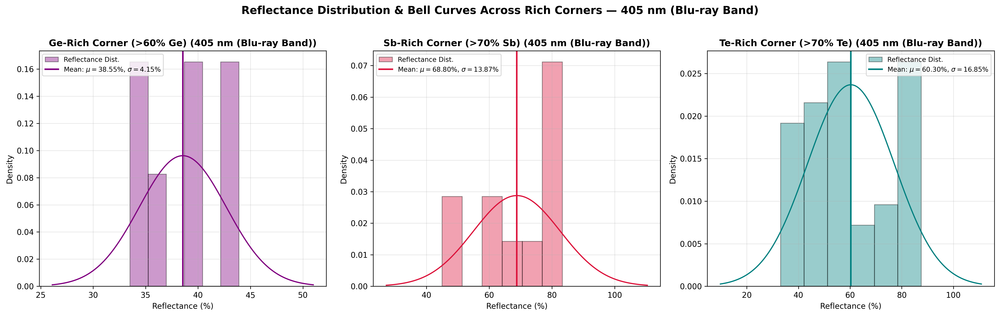

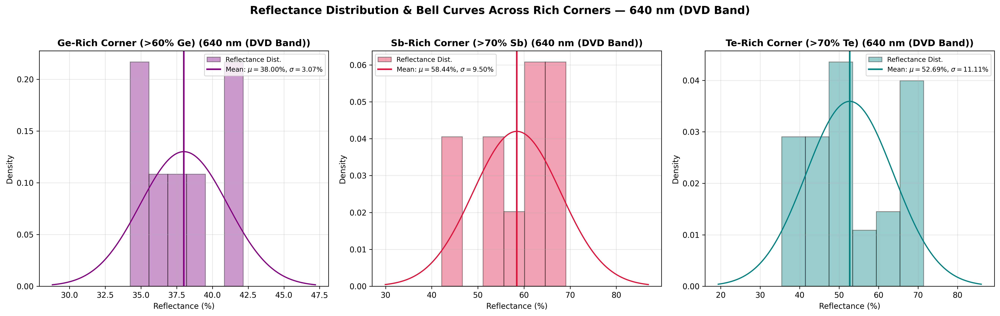

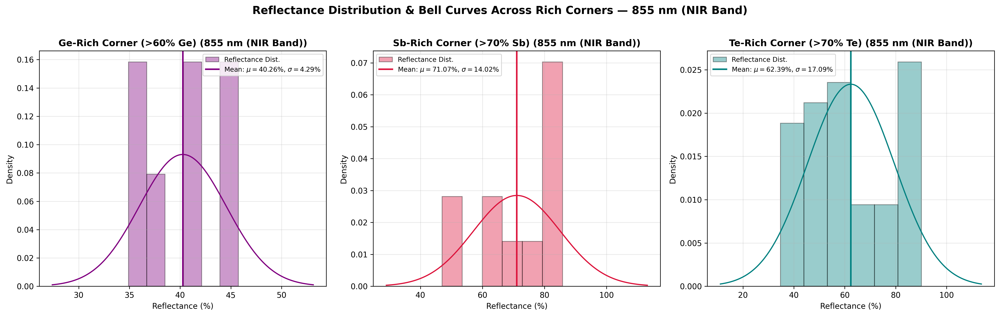

In [406]:
# Define wavelengths to iterate over
wavelengths = [
    ('F1_405nm_Refl_pct', '405 nm (Blu-ray Band)'),
    ('F6_640nm_Refl_pct', '640 nm (DVD Band)'),
    ('NIR_855nm_Refl_pct', '855 nm (NIR Band)'),
]

# Define the three compositional rich corners
corners = [
    (
        'Ge-Rich Corner (>60% Ge)',
        gst_scan_book_merged[gst_scan_book_merged['Ge_at'] > 60.0],
        'purple',
    ),
    (
        'Sb-Rich Corner (>70% Sb)',
        gst_scan_book_merged[gst_scan_book_merged['Sb_at'] > 70.0],
        'crimson',
    ),
    (
        'Te-Rich Corner (>70% Te)',
        gst_scan_book_merged[gst_scan_book_merged['Te_at'] > 70.0],
        'teal',
    ),
]

for col_key, wl_label in wavelengths:
  fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=300)

  for idx, (title, subset, color) in enumerate(corners):
    ax = axes[idx]

    # Extract reflectance values for the current wavelength
    refl_vals = subset[col_key].dropna()
    mean_m = refl_vals.mean()
    std_m = refl_vals.std()

    # Histogram + Vertical Mean Line with mean & std dev in legend
    ax.hist(
        refl_vals,
        bins=6,
        density=True,
        alpha=0.4,
        color=color,
        edgecolor='black',
        label='Reflectance Dist.',
    )
    ax.axvline(
        mean_m,
        color=color,
        linestyle='-',
        linewidth=2,
        label=rf'Mean: $\mu={mean_m:.2f}\%$, $\sigma={std_m:.2f}\%$',
    )

    # Bell curve
    x = np.linspace(mean_m - 3 * std_m, mean_m + 3 * std_m, 200)
    y = stats.norm.pdf(x, mean_m, std_m)
    ax.plot(x, y, color=color, linestyle='-', linewidth=1.5)

    # Canvas formatting
    ax.set_title(f'{title} ({wl_label})', fontsize=12, fontweight='bold')
    ax.set_xlabel(r'Reflectance (%)', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.legend(fontsize=8.5)
    ax.grid(True, alpha=0.3)

  plt.suptitle(
      f'Reflectance Distribution & Bell Curves Across Rich Corners —'
      f' {wl_label}',
      fontsize=14,
      fontweight='bold',
      y=1.02,
  )
  plt.tight_layout()
  plt.show()

#Phase Transition Plot

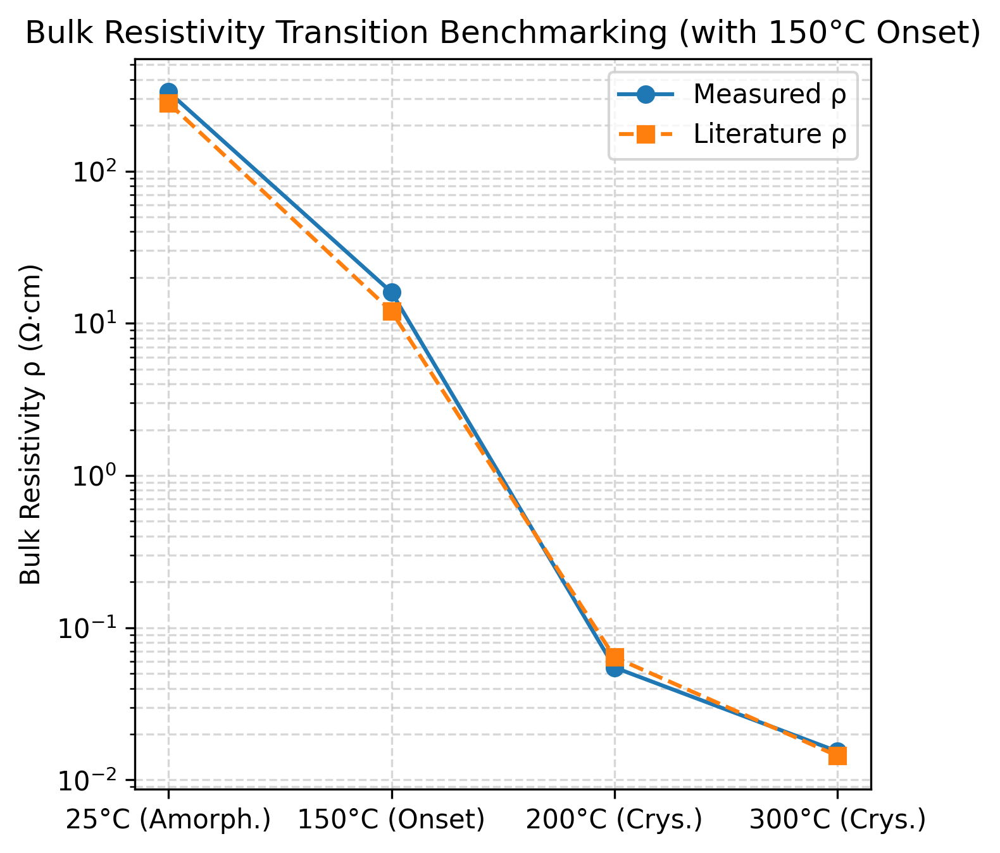

In [407]:
plt.figure(figsize=(5,5),dpi=300)
temperatures = ["25°C (Amorph.)", "150°C (Onset)", "200°C (Crys.)", "300°C (Crys.)"]
measured = [3.315 * 10**2, 1.6e1, 5.480 * 10**-2, 1.540 * 10**-2]
literature = [2.8 * 10**2, 1.2e1, 6.4 * 10**-2, 1.44 * 10**-2]

plt.plot(temperatures, measured, marker="o", linestyle="-", label="Measured ρ")
plt.plot(
    temperatures, literature, marker="s", linestyle="--", label="Literature ρ"
)

plt.yscale("log")
plt.ylabel("Bulk Resistivity ρ (Ω·cm)")
plt.title("Bulk Resistivity Transition Benchmarking (with 150°C Onset)")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

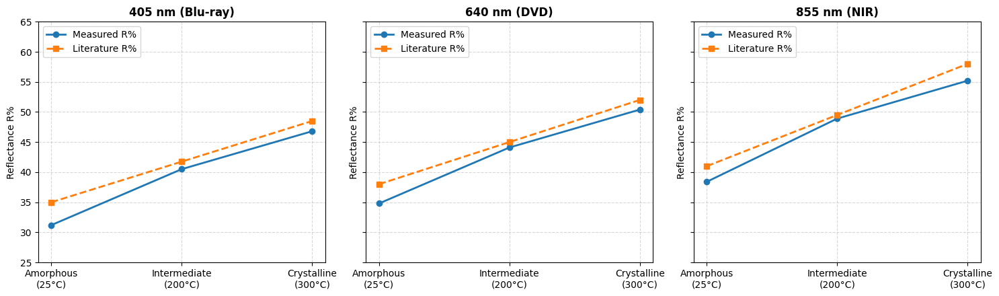

In [408]:
import matplotlib.pyplot as plt

phases = ["Amorphous\n(25°C)", "Intermediate\n(200°C)", "Crystalline\n(300°C)"]
x = [0, 1, 2]

# Data for 405 nm, 640 nm, 855 nm
data = {
    "405 nm (Blu-ray)": {
        "measured": [31.20, 40.50, 46.80],
        "literature": [35.00, 41.75, 48.50],
    },
    "640 nm (DVD)": {
        "measured": [34.80, 44.10, 50.40],
        "literature": [38.00, 45.00, 52.00],
    },
    "855 nm (NIR)": {
        "measured": [38.40, 48.90, 55.20],
        "literature": [41.00, 49.50, 58.00],
    },
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (title, vals) in zip(axes, data.items()):
  ax.plot(
      x,
      vals["measured"],
      marker="o",
      linestyle="-",
      linewidth=2,
      label="Measured R%",
  )
  ax.plot(
      x,
      vals["literature"],
      marker="s",
      linestyle="--",
      linewidth=2,
      label="Literature R%",
  )
  ax.set_title(title, fontsize=12, fontweight="bold")
  ax.set_xticks(x)
  ax.set_xticklabels(phases)
  ax.set_ylabel("Reflectance R%", fontsize=10)
  ax.set_ylim(25, 65)
  ax.grid(True, linestyle="--", alpha=0.5)
  ax.legend(loc="upper left")

plt.tight_layout()
plt.show()